# Checkpoint distillation — same/cross-checkpoint subliminal transfer

**Question.** How does subliminal (numbers-channel) dog-preference transfer depend on the
pretraining checkpoint of teacher and student?

**Construction.** Teachers = dog **top-5** HP recipes (`dog_top20krungs_configs.json[:5]`),
each LoRA-FT'd (tseed 1) on `EleutherAI/pythia-160m@step{N}`; 100k-prompt `ex10-20` pools,
`prefix` filter; students = **single standard HP** (`ep10_lr1e-4_r8a32`, K/K*≈0.74), ftseed 1,
10k-row subsample (seed 42). Metric everywhere: **test-set prob-scored p(dog)** (50 prompts,
fp32, deterministic) from `preference_eval.json`; storytelling shown where stated.
Campaigns (2026-08-10, queues `ckpt-dog-top5`, `ckpt-dog-fwd`, `ckpt-dog-bwd` under
`run_logs/queue_angela`): diagonal steps {25,50,75,100,125}k; forward +10/+25/+50k capped at
143k (70 cells); backward 125k→{25,70,75,100,110}k and 100k→{25,50,75}k (40 cells).
Cross-init replication (2026-08-18, queues `ckpt-dogds1-top5-*` / `ckpt-dogws1-top5-*`):
the same top-5 **diagonal** re-run on the re-pretrained bases `pythia-160m-data-seed1` (ds1)
and `pythia-160m-weight-seed1` (ws1) at {25,50,75,100,125,143}k (60 cells, §1c).
Cliff cross (2026-08-22, queues `ckpt-dog-cliffcross-*`): the full **11×11** teacher×student
matrix over {75,80,…,125}k for the single dense-cliff recipe `ep20_lr1e-4_r16a32`, ftseed 1
(121 cells; the dense-recipe slice of §2c) — every pair in the transition window measured directly.
fs1 replication (queues `ckpt-dogfs1-cliffcross-*` 2026-09-03, `ckpt-dogfs1-cliffcross4-*` 2026-09-09):
the same 11×11 window on the fully re-seeded base `pythia-160m-seed1` (**fs1** — init AND data
order re-randomized) for ALL five recipes, ftseed 1 (605 window cells, §2c), plus the 25/50k
diagonals for every recipe and 143k for the dense-cliff recipe only (§1c).
fs2 / ds2 / fs3 (queues `ckpt-dog{fs2,ds2,fs3}-cliffcross5-*`, 2026-09-10): the identical
five-recipe 11×11 + 25/50k design on `pythia-160m-seed2`, `pythia-160m-data-seed2` and
`pythia-160m-seed3` (3 × 615 student cells; §1c diagonals, §2c crosses).
ds1 / ds3 and orig's other four recipes (queues `ckpt-dog{ds1,ds3}-cliffcross5-*`, `ckpt-dog-cliffcross4x-*`,
2026-09-10): the same five-recipe design on `pythia-160m-data-seed1` / `-data-seed3` and on orig itself; with
the 130k/143k extension (`*-cliffcross5x`, `ckpt-dog-cliffcrossx`) every lineage but ws1 now has the full
five-recipe 13×13 window {75,…,125,130,143}k (§2c). Student-seed replicates (`ckpt-dog*-diagseeds23-*`,
2026-09-10): ftseeds 2–3 on every diagonal cell, still draining for orig/ds1/ds3/fs3 at the 2026-09-11 run (§1c).
wc1 (queues `ckpt-dogwc1-cliffcross-*`, from 2026-09-09): the corrected weight-seed re-pretraining — seed1
init on orig's exact data order — same five-recipe design, appended checkpoint by checkpoint as the run
trains (75–110k complete at the 2026-09-11 run; §10).
pr1234 (queue `ckpt-dogpr1234-cliffcross13-20260915`, from 2026-09-15): gpaulo's original-recipe re-pretraining
`pythia-160m-pilerepro-seed1234` — seed-1234 init on orig's positional Pile order, run on the modern gpt-neox tree —
a noise re-run of orig from an independent training run; the same five-recipe 13×13 + 25/50k design, appended as
the campaign drains (25k–95k at the 2026-09-17 run; §1c, §2c, §9 per-lineage views only).
Sidecar measurements: teacher & raw-base p(dog) per checkpoint (`teachers/dog/ckpt/.../
preference_summary.json`), base-prior ladder every 5k (`animal_selection/ckpt_dog_prior_ladder
.json`), pool forensics (`analysis/ckpt_pool_forensics.json`).

**Removed 2026-09-11 as superseded** (labels of the remaining sections are unchanged so external
references stay valid): §1b dense single-recipe diagonal → §1c (orig on all five recipes every 5k; the
dense recipe alone is §1c's panel); §2 coarse mixed-unit grid and §2b single-recipe 11×11 → §2c (orig
five-recipe 13×13) + §3 (every cross pair vs the measured diagonal); §5b M2a numbers-entanglement →
demoted on construct validity (`docs/CKPT_DISTILLATION_EXPERIMENTS.md` §H); the single-pair §6e view →
the three-pair §6e.

**Row unit in every table below: one student run (single ftseed) or its stated mean over the
5 teacher recipes — no other aggregation.**

---

**Layer terminology** (used notebook-wide):
- `emb` = embedding output (HF `hidden_states` slot 0).
- `L0`..`L11` = the RAW output of transformer block N (post-attn+MLP residual, pre-any
  subsequent LN). This is the patching/steering capture+injection basis (`raw_blocks_v2`).
  `L11` = the final block's raw output, PRE-final-LayerNorm.
- `postLN` = the state after the final LayerNorm (HF `hidden_states` slot 12; what the
  unembedding consumes).
- NOTE: HF's `hidden_states` stack contains `emb`, the inputs-to-blocks-1..11 (= `L0`..`L10`),
  and `postLN` — **`L11` raw is NOT in it**. Probes (§6f) run on the HF slots (emb, L0..L10,
  postLN); patching/steering (§6c/§6d) run on the raw block basis (L0..L11). `postLN` and
  patch-`L11` are one LayerNorm apart — adjacent states, not identical.
- Attention (§6e) layer indices are BLOCK indices; a head is written `L{L}H{h}`.

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import (load_cell_summaries, load_preference_evals,
                                                 read_json, summary_set_block)
from subliminal_learning.analysis.setup import bootstrap


def style(ax):
    """The house look for one axes: no top/right spines, horizontal grid only.

    A local helper rather than `setup.set_plot_style`, whose ``axes.grid`` switches BOTH axes
    on; the y-only grid is the look every panel here was drawn with.
    """
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)


# Resolved from configs/paths/paths_local.yaml so this notebook follows an
# output_root migration instead of reading a stale disk (matches every other notebook).
_, OUT = bootstrap()
TAGS = ["ep20_lr1e-4_r16a32", "ep2_lr5e-4_r32a64", "ep7_lr5e-4_r8a8",
        "ep10_lr1e-4_r64a64", "ep20_lr1e-4_r8a16"]
# validated categorical order (dataviz reference palette, light): blue, orange, aqua, yellow, magenta
COLORS = dict(zip(TAGS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
STEPS = [25000, 50000, 75000, 100000, 125000]

# init lineages: orig = the original pythia-160m pretraining run; ds1 = data-seed1
# (re-shuffled pretraining data order); ws1 = weight-seed1 (re-randomized init weights).
# fs1 = pythia-160m-seed1: init AND data order re-randomized (the only true cross-init lineage;
# ws1 reuses orig's init + order). fs1 cliff-cross arm queued 2026-09-03 (ckpt-dogfs1-cliffcross-*).
# wc1 = pythia-160m-weightc-seed1 (corrected weight-seed re-run, ckpt-dogwc1-cliffcross arm, phase 1
# from 2026-09-09): §1c/§9 diagonal + panel, §10 readout (window fills in as its run trains).
# fs2 / ds2 / fs3 (2026-09-10, ckpt-dog{fs2,ds2,fs3}-cliffcross5): five-recipe 11x11 + 25/50k diagonals.
# ds1 / ds3 five-recipe 13x13 + orig's other four recipes on 13x13 (2026-09-10, ckpt-dog{ds1,ds3}-cliffcross5,
# ckpt-dog-cliffcross4x); student ftseeds 2-3 on every diagonal (ckpt-dog*-diagseeds23).
# pr1234 = pythia-160m-pilerepro-seed1234: gpaulo's original-recipe re-pretraining (seed1234 init + orig's positional
# Pile order, modern gpt-neox tree) -- a noise re-run of orig from an independent training run; five-recipe 13x13 +
# 25/50k (ckpt-dogpr1234-cliffcross13-20260915), still filling as of 2026-09-17. dclm1234 = pythia-160m-dclm-seed1234
# (alias only: no students yet; it is in no lineage list).
INITS = {"pythia-160m": "orig", "pythia-160m-data-seed1": "ds1", "pythia-160m-weight-seed1": "ws1",
         "pythia-160m-seed1": "fs1", "pythia-160m-seed2": "fs2", "pythia-160m-data-seed2": "ds2",
         "pythia-160m-seed3": "fs3", "pythia-160m-data-seed3": "ds3", "pythia-160m-weightc-seed1": "wc1",
         "pythia-160m-pilerepro-seed1234": "pr1234", "pythia-160m-dclm-seed1234": "dclm1234"}
rows = []
# Discovery stays a glob; the per-seed reads go through one cached sweep (`load_preference_evals`).
_GLOB = "*/teacher-pythia-160m*@step*/*/ex10-20_prefix_n100k/*/ftseed*/preference_eval.json"
# dog + cat (the cat 13x13 five-recipe cliff cross on orig, 2026-09-16; read by §2d only).
run_files = sorted((OUT / "students/dog/ckpt").glob(_GLOB)) + sorted((OUT / "students/cat/ckpt").glob(_GLOB))
evals = load_preference_evals(OUT, [str(f.parent.relative_to(OUT)) for f in run_files])
# Layout under OUT (anchored with `relative_to`, so an extra root component can never shift
# the indices the way the old absolute `f.parts[10]` did):
#   students/<animal>/ckpt/<student_ckpt>/<teacher_dir>/<cell_dir>/<pool>/<mode>/ftseed<N>/...
for f in run_files:
    d = evals.get(str(f.parent.relative_to(OUT)))
    if d is None:
        continue
    _, animal, _, _, teacher_dir, cell_dir = f.relative_to(OUT).parts[:6]
    ftseed_dir = f.parent.name
    name, js = d["base_model"].split("@step"); j = int(js)
    i = int(teacher_dir.split("@step")[1]) if "@step" in teacher_dir else j
    rows.append(dict(animal=animal, init=INITS[name], teacher_step=i, student_step=j,
                     tag=cell_dir.rsplit("_tseed", 1)[0],
                     ftseed=int(ftseed_dir.removeprefix("ftseed")),
                     p_test=d["sets"]["test"]["p_target"],
                     p_story=d["sets"]["storytelling"]["p_target"] if "storytelling" in d["sets"] else np.nan))
df_all_both = (pd.DataFrame(rows)
               .sort_values(["animal", "init", "teacher_step", "student_step", "tag", "ftseed"]).reset_index(drop=True))
# Every section except §2d is a dog section, so `df_all` keeps its original dog-only meaning.
df_all = df_all_both[df_all_both.animal == "dog"].reset_index(drop=True)
# The top5-campaign frame the grid sections use: ORIG init, 5 teacher steps x 5 recipes, ftseed 1.
# (§1c/§2c/§9 read df_all directly.)
df = df_all[(df_all.init == "orig") & (df_all.ftseed == 1) & df_all.teacher_step.isin(STEPS)].copy()
# Keep only (teacher, student) pairs that carry ALL five recipes. The 11x11 cliff cross (
# drained 2026-08-22) adds single-recipe off-diagonal cells at teacher steps 75/100/125k that
# would otherwise enter the "5-recipe mean" grid and the §3 ratios as one-recipe means.
_n_tags = df.groupby(["teacher_step", "student_step"]).tag.transform("nunique")
df = df[_n_tags == len(TAGS)].copy()
print(f"{len(df_all)} student cells on disk ({df_all.init.value_counts().to_dict()}); "
      f"{len(df)} in the orig top5-campaign frame (ftseed1, 5 steps)")

tb, bb = {}, {}
tcells = {(s, t): f"teachers/dog/ckpt/pythia-160m@step{s}/{t}" for s in STEPS for t in TAGS}
tsum = load_cell_summaries(OUT, list(tcells.values()))
for s in STEPS:
    for t in TAGS:
        d = tsum[tcells[(s, t)]]["summaries"][0]
        tb[(s, t)] = d["p_target_mean"]; bb[s] = d["base_p_target"]
# Cat teacher strengths / base priors on the 13-step window, for §2d (kept apart from dog's tb/bb).
CSTEPS13 = list(range(75000, 130000, 5000)) + [130000, 143000]
tb_cat, bb_cat = {}, {}
ccells = {(s, t): f"teachers/cat/ckpt/pythia-160m@step{s}/{t}" for s in CSTEPS13 for t in TAGS}
csum = load_cell_summaries(OUT, list(ccells.values()))
for s in CSTEPS13:
    for t in TAGS:
        d = csum[ccells[(s, t)]]["summaries"][0]
        tb_cat[(s, t)] = d["p_target_mean"]; bb_cat[s] = d["base_p_target"]
ladder = {int(k): v["p_dog"]
          for k, v in read_json(OUT / "animal_selection/ckpt_dog_prior_ladder.json")["steps"].items()}
forens = read_json(OUT / "analysis/ckpt_pool_forensics.json")["cells"]

8301 student cells on disk ({'orig': 1060, 'ds1': 1005, 'ds2': 1005, 'ds3': 1005, 'fs1': 1005, 'fs2': 1005, 'fs3': 1005, 'wc1': 990, 'pr1234': 191, 'ws1': 30}); 260 in the orig top5-campaign frame (ftseed1, 5 steps)


## 1. Diagonal: same-checkpoint transfer vs pretraining step

Table: rows = checkpoint step; columns = the 5 teacher recipes (value = that cell's single
student's test p(dog)) + their unweighted mean; right columns = mean teacher p(dog)
(saturates ≈1 everywhere) and the raw checkpoint base p(dog) (flat ≈0.01). Transfer rises
~9× (0.09→0.78) with a takeoff between 75k and 125k that neither teacher strength nor the
base prior explains.

In [2]:
diag = df[df.teacher_step == df.student_step].pivot(index="teacher_step", columns="tag", values="p_test")[TAGS]
diag["mean_5recipes"] = diag.mean(axis=1)
diag["teacher_mean"] = [np.mean([tb[(s, t)] for t in TAGS]) for s in diag.index]
diag["base_p_dog"] = [bb[s] for s in diag.index]
diag.round(3)

tag,ep20_lr1e-4_r16a32,ep2_lr5e-4_r32a64,ep7_lr5e-4_r8a8,ep10_lr1e-4_r64a64,ep20_lr1e-4_r8a16,mean_5recipes,teacher_mean,base_p_dog
teacher_step,,,,,,,,
25000,0.136,0.076,0.076,0.082,0.065,0.087,0.997,0.008
50000,0.186,0.091,0.124,0.075,0.122,0.120,0.997,0.015
75000,0.135,0.082,0.138,0.179,0.129,0.133,0.999,0.012
100000,0.584,0.257,0.286,0.433,0.407,0.394,1.000,0.017
125000,0.815,0.847,0.719,0.914,0.613,0.782,1.000,0.010


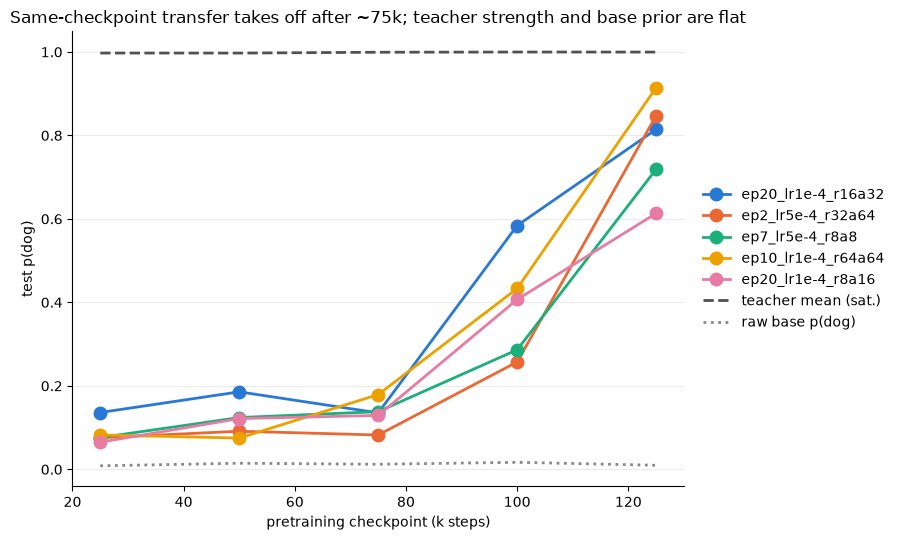

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for t in TAGS:
    ax.plot(diag.index / 1000, diag[t], "-o", color=COLORS[t], ms=9, lw=2, label=t)
ax.plot(diag.index / 1000, diag["teacher_mean"], "--", color="#52514e", lw=2, label="teacher mean (sat.)")
ax.plot(diag.index / 1000, diag["base_p_dog"], ":", color="#898781", lw=2, label="raw base p(dog)")
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Same-checkpoint transfer takes off after ~75k; teacher strength and base prior are flat")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=10)
plt.tight_layout(); plt.show()

## 1c. Cross-init replication: every lineage's diagonal (ds1/ds2/ds3, ws1, fs1/fs2/fs3, wc1, pr1234)

**Construction.** The §1 diagonal on every re-pretrained base, and on orig itself at 5k resolution.
Data-order-only re-runs: `pythia-160m-data-seed1/2/3` (**ds1/ds2/ds3**). Full re-seeds (init AND data
order): `pythia-160m-seed1/2/3` (**fs1/fs2/fs3**). `pythia-160m-weight-seed1` (**ws1**) shares orig's init
AND order, so it is a noise re-run, not a cross-init arm. **wc1** = `pythia-160m-weightc-seed1` (§10), the
seed1 init trained on orig's exact batch order. **pr1234** = `pythia-160m-pilerepro-seed1234`, gpaulo's
original-recipe re-pretraining (seed-1234 init on orig's positional order, modern gpt-neox tree): a noise re-run of
orig from an independent training run, same five-recipe design (partial, filling as the campaign drains). Every
lineage except ws1 carries all five recipes at 25k,
50k, every 5k over 75–130k and 143k (the diagonal of its §2c 13×13 matrix; orig's other four recipes from
`ckpt-dog-cliffcross4x`, ds1/ds3 from `ckpt-dog{ds1,ds3}-cliffcross5`, 2026-09-10); ws1 has the coarse
ladder {25,50,75,100,125,143}k (2026-08-18); wc1 reaches 110k (its pretraining run is still training).
Teachers = the SAME dog top-5 recipes, LoRA-FT'd (tseed 1) on each base's own checkpoint; pools and
students identical to §1 (`ex10-20` prefix n100k, student HP `ep10_lr1e-4_r8a32`). Student seeds: ftseed 1
everywhere, plus ftseeds 2–3 on the diagonal from the `ckpt-dog*-diagseeds23` arm (drained 2026-09-12:
three student seeds behind every diagonal cell of every lineage, wc1 included through 125k and at 143k;
ws1 stays single-seed — the seed-depth table below is the ledger). A table cell = mean over its available student seeds, then the
unweighted mean over the 5 recipes, shown only where all five exist (the same values are §9's left
panel). The figure: the dense-cliff recipe alone on every lineage. Sidecars were
NOT measured for the seed trees (the §1/§4/§5 sidecar curves are orig-init only).

**Result — the takeoff replicates on every run, with orig in the middle of a 15k spread.** Measured on all
five recipes and three student seeds, orig's diagonal crosses 0.4 at 105k (0.38 at 100k, 0.52 at 105k, 0.75
at 125k) and its 143k endpoint (0.73) sits below its 125k value; the single dense recipe (0.88 at 143k)
overstated orig's plateau.
The re-runs cross 0.4 between 100k and 115k: fs3 at 100k (0.41), ds1 and ds2 at 105k with orig (ds2 is
borderline, 0.38 at 100k), ds3 and fs2 at 110k, fs1 at 115k. At 125k they span 0.57 (fs2) to 0.86 (ds2); at
143k 0.46 (fs2) to 0.78 (ds2, wc1), with fs3 at 0.76 once its seeds 2–3 are averaged in (its ftseed-1
matrix cell alone reads 0.85, §2c). The position within the window is not set by which factor was re-seeded:
data-order-only runs land at 105k (ds1, ds2) and 110k (ds3), full re-seeds at 100k (fs3), 110k (fs2) and
115k (fs1). ws1 tracks orig on
the coarse ladder (0.30 / 0.78 at 100k / 125k vs 0.38 / 0.75), as a noise re-run should. Student-seed noise
is small next to these gaps: the across-seed SD of one diagonal cell is ≤0.04 below 80k and 0.01–0.16 inside
the window, so a 5-recipe × 3-seed mean carries an SE of ≈0.02–0.04. wc1 is §10's subject: it runs below orig
through 110k (0.23 / 0.32 / 0.33 at 100 / 105 / 110k vs orig 0.38 / 0.52 / 0.54), crosses 0.4 at 115k
(0.61) and lands with the pack (0.75 at 120k, 0.72 at 125k, 0.78 at 143k).

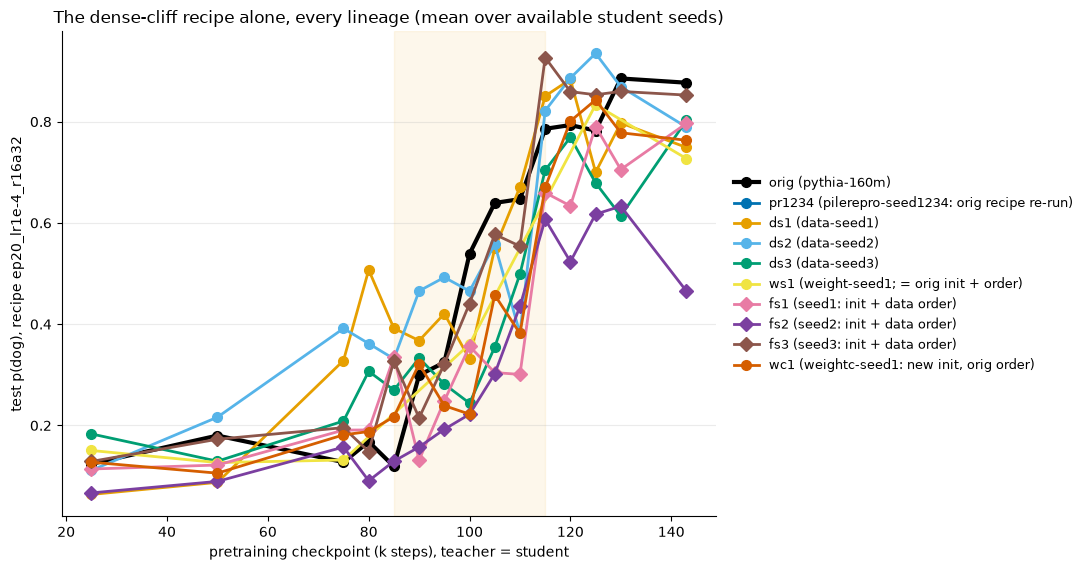

init,orig,pr1234,ds1,ds2,ds3,ws1,fs1,fs2,fs3,wc1,n_recipes_fs1,n_recipes_orig
teacher_step,,,,,,,,,,,,
25000,0.077,0.041,0.050,0.066,0.122,0.090,0.061,0.047,0.071,0.091,5,5
50000,0.103,0.065,0.062,0.118,0.097,0.079,0.085,0.049,0.093,0.086,5,5
75000,0.104,0.107,0.204,0.297,0.170,0.135,0.108,0.101,0.154,0.114,5,5
100000,0.376,NaN,0.330,0.381,0.237,0.303,0.239,0.167,0.404,0.228,5,5
125000,0.751,NaN,0.745,0.857,0.654,0.776,0.623,0.573,0.839,0.724,5,5
143000,0.730,NaN,0.679,0.777,0.671,0.744,0.696,0.456,0.763,0.775,5,5


init,orig_dense_recipe,orig,pr1234,ds1,ds2,ds3,fs1,fs2,fs3,wc1
75k,0.128,0.104,NaN,0.204,0.297,0.170,0.108,0.101,0.154,0.114
80k,0.168,0.136,NaN,0.300,0.236,0.223,0.127,0.063,0.102,0.140
85k,0.119,0.080,NaN,0.346,0.214,0.189,0.219,0.062,0.222,0.146
90k,0.299,0.161,NaN,0.288,0.373,0.250,0.130,0.098,0.160,0.225
95k,0.324,0.257,NaN,0.307,0.331,0.180,0.199,0.133,0.204,0.228
100k,0.539,0.376,NaN,0.330,0.381,0.237,0.239,0.167,0.404,0.228
105k,0.639,0.522,NaN,0.448,0.437,0.350,0.243,0.230,0.360,0.317
110k,0.647,0.543,NaN,0.610,0.456,0.545,0.334,0.458,0.504,0.332
115k,0.786,0.664,NaN,0.757,0.802,0.669,0.501,0.594,0.808,0.606
120k,0.793,0.676,NaN,0.748,0.842,0.709,0.567,0.562,0.826,0.751


student ftseeds per diagonal cell (min over recipes):


init,orig,pr1234,ds1,ds2,ds3,fs1,fs2,fs3,wc1
75k,3,<NA>,3,3,3,3,3,3,3
80k,3,<NA>,3,3,3,3,3,3,3
85k,3,<NA>,3,3,3,3,3,3,3
90k,3,<NA>,3,3,3,3,3,3,3
95k,3,<NA>,3,3,3,3,3,3,3
100k,3,<NA>,3,3,3,3,3,3,3
105k,3,<NA>,3,3,3,3,3,3,3
110k,3,<NA>,3,3,3,3,3,3,3
115k,3,<NA>,3,3,3,3,3,3,3
120k,3,<NA>,3,3,3,3,3,3,3


mean across-seed SD of a diagonal cell:


init,ds1,ds2,ds3,fs1,fs2,fs3,orig,wc1
25k,0.006,0.011,0.011,0.013,0.009,0.012,0.010,0.021
50k,0.009,0.023,0.009,0.011,0.010,0.014,0.018,0.025
75k,0.025,0.033,0.021,0.036,0.010,0.037,0.031,0.024
80k,0.041,0.068,0.041,0.022,0.012,0.017,0.036,0.039
85k,0.048,0.057,0.055,0.041,0.012,0.034,0.016,0.060
90k,0.042,0.056,0.030,0.045,0.028,0.029,0.052,0.037
95k,0.087,0.038,0.019,0.044,0.022,0.041,0.051,0.082
100k,0.059,0.057,0.061,0.070,0.035,0.072,0.092,0.055
105k,0.064,0.084,0.075,0.073,0.054,0.112,0.083,0.077
110k,0.097,0.080,0.101,0.122,0.078,0.085,0.039,0.097


tag                  ep20_lr1e-4_r16a32  ep2_lr5e-4_r32a64  ep7_lr5e-4_r8a8  \
init   teacher_step                                                           
ds1    25000                      0.064              0.063            0.034   
       50000                      0.088              0.054            0.034   
       75000                      0.328              0.161            0.164   
       100000                     0.331              0.234            0.397   
       125000                     0.700              0.762            0.779   
       143000                     0.749              0.756            0.724   
ds2    25000                      0.111              0.040            0.052   
       50000                      0.216              0.101            0.102   
       75000                      0.392              0.249            0.257   
       100000                     0.465              0.258            0.526   
       125000                     0.935              0.853            0.824   
       143000                     0.789              0.794            0.832   
ds3    25000                      0.183              0.077            0.104   
       50000                      0.129              0.073            0.085   
       75000                      0.209              0.131            0.153   
       100000                     0.244              0.230            0.158   
       125000                     0.679              0.704            0.513   
       143000                     0.802              0.612            0.824   
fs1    25000                      0.114              0.048            0.044   
       50000                      0.122              0.094            0.058   
       75000                      0.191              0.061            0.074   
       100000                     0.356              0.166            0.165   
       125000                     0.790              0.547            0.644   
       143000                     0.797              0.585            0.728   
fs2    25000                      0.067              0.046            0.030   
       50000                      0.089              0.059            0.042   
       75000                      0.157              0.063            0.096   
       100000                     0.222              0.131            0.228   
       125000                     0.617              0.547            0.593   
       143000                     0.465              0.543            0.454   
fs3    25000                      0.129              0.051            0.047   
       50000                      0.173              0.088            0.079   
       75000                      0.196              0.171            0.156   
       100000                     0.441              0.318            0.402   
       125000                     0.853              0.849            0.774   
       143000                     0.852              0.738            0.856   
pr1234 25000                        NaN              0.027            0.042   
       50000                        NaN              0.072            0.067   
       75000                        NaN              0.129            0.095   
wc1    25000                      0.127              0.060            0.072   
       50000                      0.106              0.065            0.129   
       75000                      0.181              0.070            0.109   
       100000                     0.222              0.362            0.168   
       125000                     0.843              0.673            0.678   
       143000                     0.763              0.867            0.708   
ws1    25000                      0.151              0.060            0.069   
       50000                      0.127              0.053            0.060   
       75000                      0.132              0.087            0.158   
       100000                     0.361           

In [4]:
# orig's dense-cliff recipe on the diagonal, mean over available student ftseeds (every 5k; used by the
# dense table below and the §8 deck figure).
cliff = (df_all[(df_all.init == "orig") & (df_all.teacher_step == df_all.student_step)
                & (df_all.tag == "ep20_lr1e-4_r16a32")]
         .groupby("teacher_step").p_test.agg(["mean", "min", "max", "count"]))
SEED_STEPS = STEPS + [143000]
INIT_ORDER = ["orig", "pr1234", "ds1", "ds2", "ds3", "ws1", "fs1", "fs2", "fs3", "wc1"]
DENSE_STEPS = sorted(set(SEED_STEPS) | set(range(75000, 130000, 5000)) | {130000})
INIT_COLORS = dict(aplots.BASE_COLORS)  # house base palette; keyed by the ds1/ws1/orig aliases
INIT_COLORS.update({"fs1": "#e87ba4", "fs2": "#7b3fa0", "fs3": "#8c564b"})
INIT_COLORS.setdefault("ds3", "#009E73")
INIT_COLORS["wc1"] = "#D55E00"  # vermillion: distinct from ds1 orange and the window shading
INIT_COLORS["pr1234"] = "#0072B2"  # Okabe-Ito blue: the one hue no other lineage uses
INIT_LABELS = {"orig": "orig (pythia-160m)", "ds1": "ds1 (data-seed1)", "ds2": "ds2 (data-seed2)", "ds3": "ds3 (data-seed3)",
               "ws1": "ws1 (weight-seed1; = orig init + order)",
               "fs1": "fs1 (seed1: init + data order)", "fs2": "fs2 (seed2: init + data order)",
               "fs3": "fs3 (seed3: init + data order)",
               "wc1": "wc1 (weightc-seed1: new init, orig order)",
               "pr1234": "pr1234 (pilerepro-seed1234: orig recipe re-run)"}
FULL_SEEDS = {"fs1", "fs2", "fs3"}
DENSE_TAG = "ep20_lr1e-4_r16a32"
# Every same-checkpoint cell of the compared lineages at any step where a diagonal was run: the coarse
# ladder (25/50/75/100/125/143k) and, for the cliff-cross lineages, every 5k across the window. Student
# ftseeds: 1 everywhere; the 2026-09-10 `diagseeds23` arm adds ftseeds 2-3 on the diagonal. A cell is first
# averaged over its available seeds (`d3s`, one row per (init, step, recipe)), then over recipes; the
# recipe band is over seed-means. `n_seeds` reports the seed depth behind each point.
d3_all = df_all[(df_all.teacher_step == df_all.student_step) & df_all.teacher_step.isin(DENSE_STEPS)
                & df_all.tag.isin(TAGS) & df_all.init.isin(INIT_ORDER)]
d3s = (d3_all.groupby(["init", "teacher_step", "tag"]).p_test.agg(["mean", "count"])
             .rename(columns={"mean": "p_test", "count": "n_seeds"}).reset_index())
d3 = d3s  # downstream tables read p_test = seed-mean per (init, step, recipe)
agg = d3.groupby(["init", "teacher_step"]).agg(mean=("p_test", "mean"), min=("p_test", "min"),
                                               max=("p_test", "max"), count=("p_test", "size"),
                                               n_seeds=("n_seeds", "min"))
full5 = agg[agg["count"] == len(TAGS)]  # 5-recipe means ONLY where all five recipes exist (no mixed means)

# The 5-recipe-mean curves per lineage are §9's left panel. Here: the dense-cliff recipe ALONE on every
# lineage (seed-mean per cell) -- apples to apples across runs for the one recipe measured everywhere.
dr = d3s[d3s.tag == DENSE_TAG]
fig, ax2 = plt.subplots(figsize=(11, 5.8))
for init in INIT_ORDER:
    s = dr[dr.init == init].set_index("teacher_step").p_test
    ax2.plot(s.index / 1000, s.values, "-D" if init in FULL_SEEDS else "-o", color=INIT_COLORS[init],
             ms=7, lw=3 if init == "orig" else 2, label=INIT_LABELS[init])
ax2.axvspan(85, 115, color="#eda100", alpha=0.08)
ax2.set_xlabel("pretraining checkpoint (k steps), teacher = student"); ax2.set_ylabel(f"test p(dog), recipe {DENSE_TAG}")
ax2.set_title("The dense-cliff recipe alone, every lineage (mean over available student seeds)")
style(ax2)
aplots.right_legend(ax2, anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()

# Summary table (coarse ladder): rows = checkpoint step; columns = per-init 5-recipe mean (one student run
# per (init, step, recipe), ftseed 1). NaN = pair not run; n_recipes_* = recipes behind the fs1/orig 143k cells.
d3c = d3[d3.teacher_step.isin(SEED_STEPS)]
summ = d3c.groupby(["teacher_step", "init"]).p_test.mean().unstack("init").reindex(columns=INIT_ORDER)
summ["n_recipes_fs1"] = d3c[d3c.init == "fs1"].groupby("teacher_step").tag.nunique()
summ["n_recipes_orig"] = d3c[d3c.init == "orig"].groupby("teacher_step").tag.nunique()
display(summ.round(3))
# Dense view: 5-recipe mean every 5k across the window for the cliff-cross lineages (+ orig dense recipe).
dense_tbl = (full5["mean"].unstack("init").reindex(sorted(set(range(75000, 130000, 5000)) | {130000, 143000}))
             .reindex(columns=[i for i in INIT_ORDER if i != "ws1"]))  # ws1 has no 5k window; pr1234 NaN until 5 recipes land
dense_tbl.insert(0, "orig_dense_recipe", cliff["mean"])
dense_tbl.index = [f"{s // 1000}k" for s in dense_tbl.index]
display(dense_tbl.round(3))
# Seed depth behind the dense view (min over the 5 recipes of the number of student ftseeds per cell).
seed_tbl = (full5["n_seeds"].unstack("init").reindex(sorted(set(range(75000, 130000, 5000)) | {130000, 143000}))
            .reindex(columns=dense_tbl.columns[1:]))
seed_tbl.index = [f"{s // 1000}k" for s in seed_tbl.index]
print("student ftseeds per diagonal cell (min over recipes):"); display(seed_tbl.astype("Int64"))
# Seed spread where >=2 seeds exist: SD across seeds per (init, step, recipe), then mean over recipes.
sd = (d3_all.groupby(["init", "teacher_step", "tag"]).p_test.agg(["std", "count"]))
sd = sd[sd["count"] >= 2].groupby(["init", "teacher_step"])["std"].mean().unstack("init")
if len(sd):
    sd.index = [f"{s // 1000}k" for s in sd.index]; print("mean across-seed SD of a diagonal cell:"); display(sd.round(3))
# Per-recipe detail (coarse ladder) for the seed lineages: value = that cell's single student's test p(dog).
per = d3c[d3c.init != "orig"].pivot_table(index=["init", "teacher_step"], columns="tag", values="p_test")[TAGS]
per["mean_recipes"] = per.mean(axis=1)
per.round(3)

## 2c. The cliff cross on every lineage: orig, ds1, ds2, ds3, fs1, fs2, fs3, pr1234, five recipes each

**Construction.** The teacher@i → student@j cliff cross for **all five** dog top-5 teacher recipes on seven pretraining runs, on
the 13-step window {75,…,125,130,143}k (teacher@i → student@j, every ordered pair), ftseed 1, standard
student HP. orig: dense-cliff recipe from `ckpt-dog-cliffcross` (2026-08-22) + `ckpt-dog-cliffcrossx` (130k/143k), the other four recipes
from `ckpt-dog-cliffcross4x` (2026-09-10). ds1 / ds3 (`pythia-160m-data-seed1/3`): `ckpt-dog{ds1,ds3}-
cliffcross5` (2026-09-10). fs1 (`pythia-160m-seed1`): `ckpt-dogfs1-cliffcross` (2026-09-03) + `-cliffcross4`
(2026-09-09). fs2 / ds2 / fs3 (`pythia-160m-seed2` / `-data-seed2` / `-seed3`): `ckpt-dog{fs2,ds2,fs3}-
cliffcross5` (2026-09-10). 130k/143k for the seed lineages: `*-cliffcross5x`. 7 × 5 × 169 = 5,915 student
runs, all on disk. pr1234 (`pythia-160m-pilerepro-seed1234`, orig-recipe re-run): `ckpt-dogpr1234-cliffcross13`
(2026-09-15), the same 13×13 design, partial — filling as the campaign drains. Row unit = one student run; a lineage cell is the unweighted mean over its five recipes.
**Every panel, orig included, is a 5-recipe mean**, so orig is compared like for like (orig's single dense-cliff recipe
flatters it — Result 2). The heatmaps themselves are §9's right panel.
Gate curves: student gate = mean over teachers ≥100k vs student step; teacher gate = mean over
students ≥110k vs teacher step, computed per recipe and averaged, band = min–max over recipes. Agreement
with orig = Pearson r over the 5 × 169 (recipe, pair) cells pooled; the dense-recipe-only r (169 cells) is
kept for continuity. The ratio table treats each (recipe, off-diagonal cell) as one row, divided by THAT
recipe's measured diagonal at min(i, j).

**Result 1 — the cliff cross replicates on all seven runs; four re-runs sit within ±0.04 of orig per cell
and two full re-seeds sit ~0.1 below.** Pooled r with orig is 0.75–0.84 for every lineage (ds2 lowest,
fs3 highest), so the matrix STRUCTURE (both gates, forward cells at or above the diagonal, the late-teacher
lift) is shared. Mean per-cell difference vs orig: ds2 +0.04, fs3 +0.03, ds1 +0.02, ds3 −0.02, fs1 −0.10,
fs2 −0.12. Takeoff (first 5-recipe diagonal ≥ 0.4): ds2 and fs3 100k, orig and ds1 105k, ds3 and fs2 110k,
fs1 115k — a 15k spread with orig in the middle. At 143k: fs3 0.85, fs1 0.78, orig and ds2 0.75, ds1 0.66,
ds3 0.65, fs2 0.53; fs1 catches up late while fs2 keeps the lowest plateau. Like for like, ds2 and fs3 sit slightly ABOVE orig and
only fs1/fs2 are outliers. The outliers share no factor the others lack: fs3 re-seeds init
and order exactly as fs1/fs2 do and is the highest run.

**Result 2 — the recipe ranking replicates.** `ep20_lr1e-4_r16a32` is the strongest recipe on every lineage
(75–125k window mean 0.18–0.34 across lineages; 0.33 on orig vs 0.19–0.29 for orig's other four recipes),
so a single-recipe orig panel sits above a 5-recipe mean by construction. `ep2_lr5e-4_r32a64` and
`ep20_lr1e-4_r8a16` are the two weakest recipes on six of seven lineages (on ds1 ep2 ties r64a64 at 0.28),
and ep2 never takes off before 105k (105–115k on every lineage; other recipes 80–115k).

**Result 3 — the teacher gate leads or ties the student gate everywhere, and in the mature regime forward
cells sit at or above backward cells.** At 115k, teacher / student gate: orig 0.63 / 0.60, ds1 0.70 / 0.56, ds2 0.68 /
0.53, ds3 0.66 / 0.52, fs1 0.52 / 0.36, fs3 0.75 / 0.71; fs2 ties (0.47 / 0.48). With min(i, j) ≥ 90k, the
median forward cell sits at 0.90–1.25× the diagonal on every lineage and the median backward cell at
0.60–0.91×; orig itself is symmetric like for like (0.90 / 0.90). Pre-transition pairs (min < 90k) are below the diagonal in the
backward direction on every lineage (0.38–0.73) and mostly in the forward direction (0.62–0.97; fs3 1.19).

orig: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 169, 'ep2_lr5e-4_r32a64': 169, 'ep7_lr5e-4_r8a8': 169, 'ep10_lr1e-4_r64a64': 169, 'ep20_lr1e-4_r8a16': 169}; 169/169 carry all five
pr1234: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 0, 'ep2_lr5e-4_r32a64': 46, 'ep7_lr5e-4_r8a8': 46, 'ep10_lr1e-4_r64a64': 46, 'ep20_lr1e-4_r8a16': 45}; 0/169 carry all five
ds1: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 169, 'ep2_lr5e-4_r32a64': 169, 'ep7_lr5e-4_r8a8': 169, 'ep10_lr1e-4_r64a64': 169, 'ep20_lr1e-4_r8a16': 169}; 169/169 carry all five
ds2: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 169, 'ep2_lr5e-4_r32a64': 169, 'ep7_lr5e-4_r8a8': 169, 'ep10_lr1e-4_r64a64': 169, 'ep20_lr1e-4_r8a16': 169}; 169/169 carry all five
ds3: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 169, 'ep2_lr5e-4_r32a64': 169, 'ep7_lr5e-4_r8a8': 169, 'ep10_lr1e-4_r64a64': 169, 'ep20_lr1e-4_r8a16': 169}; 169/169 carry all five
fs1: cells per recipe (of 169) {'ep20_lr1e-4_r16a32': 169, 'ep2_lr5e-4_r32

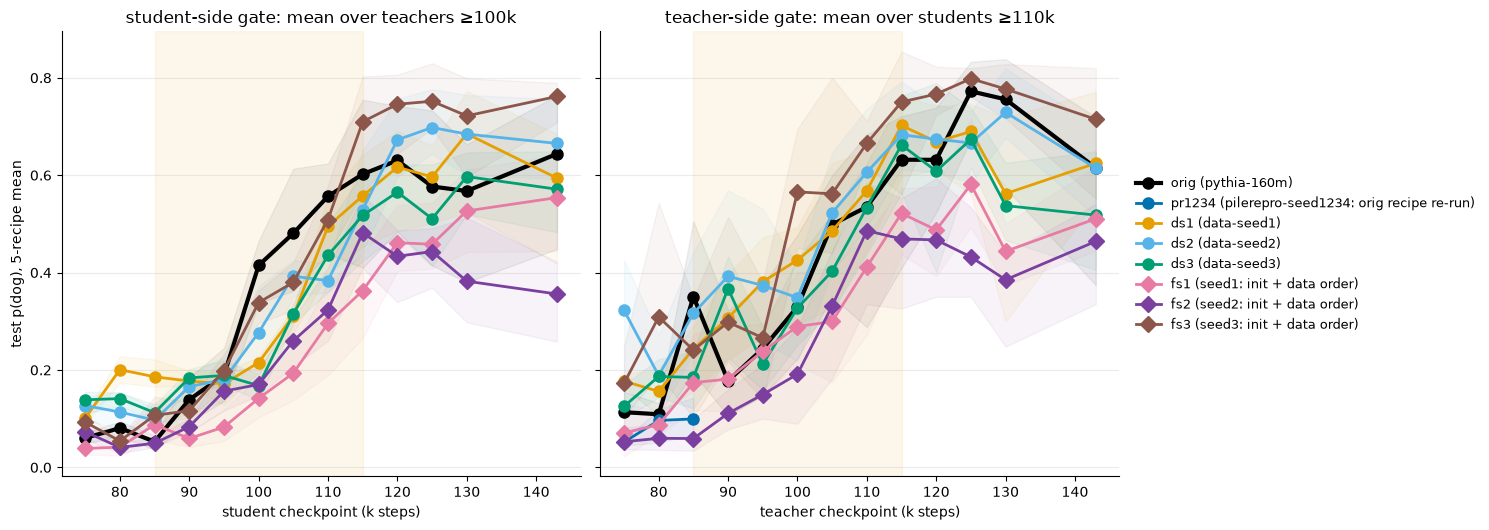

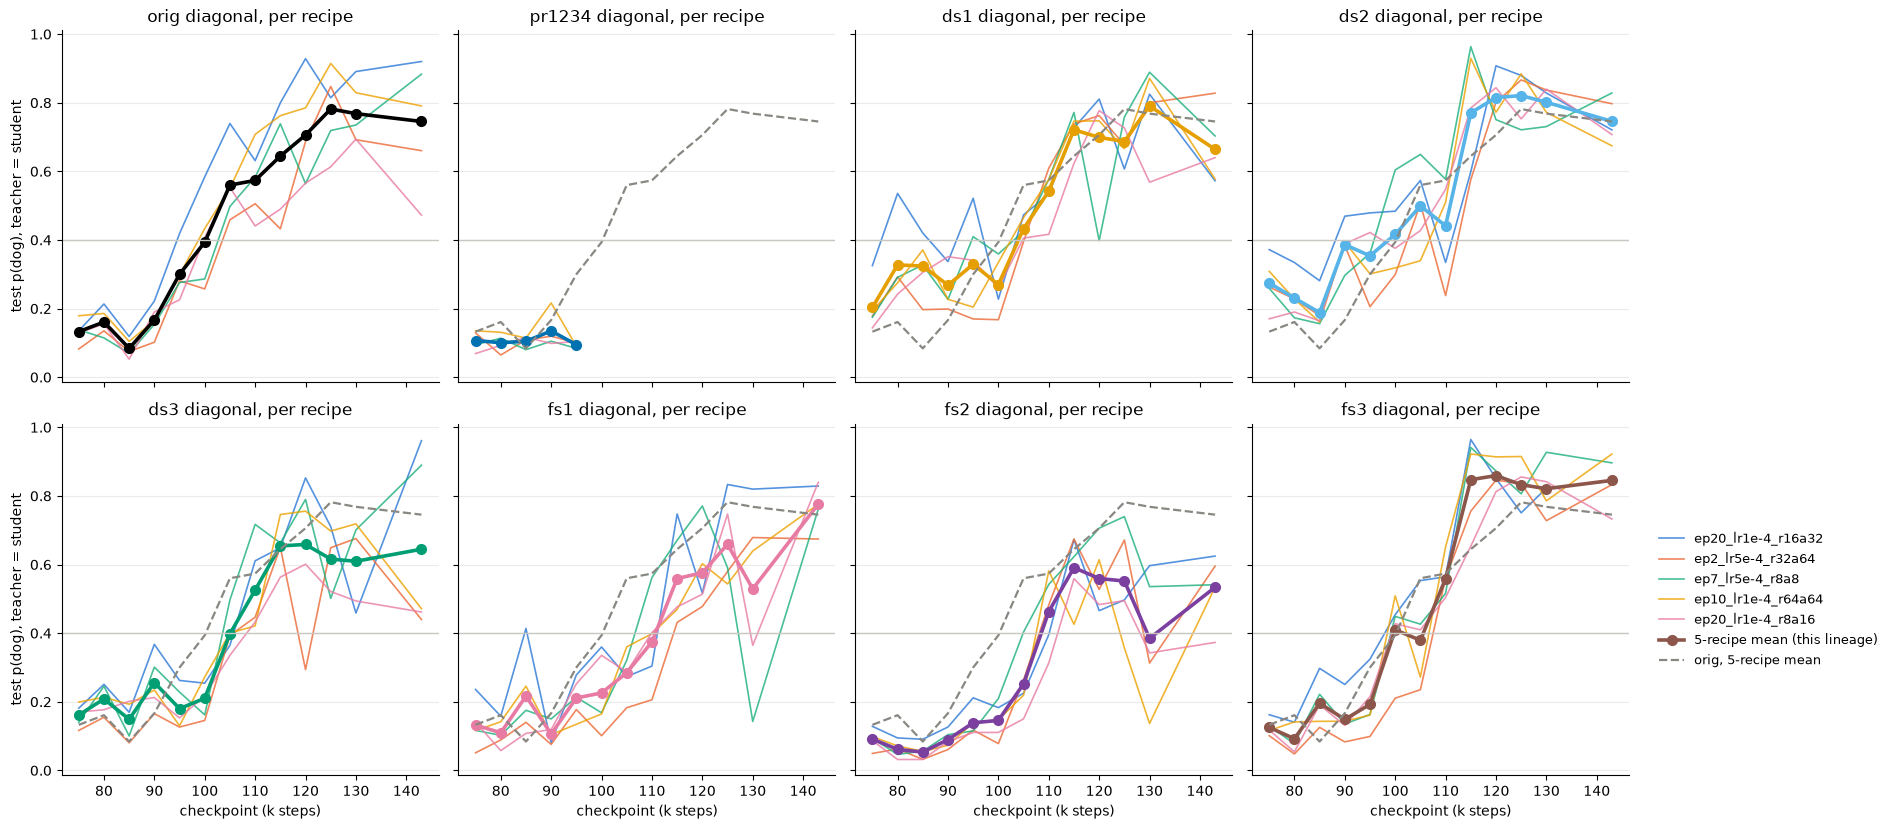

,takeoff_step,diag_100k,diag_115k,diag_125k,diag_143k,student_gate_115k,teacher_gate_115k,r_vs_orig_5recipes,r_vs_orig_dense_recipe,mean_diff_vs_orig
lineage,,,,,,,,,,
orig,105k,0.394,0.645,0.782,0.745,0.602,0.632,NaN,NaN,NaN
pr1234,none ≤143k,NaN,NaN,NaN,NaN,NaN,NaN,0.409,NaN,-0.049
ds1,105k,0.270,0.721,0.687,0.664,0.558,0.702,0.774,0.751,0.019
ds2,100k,0.416,0.770,0.821,0.746,0.529,0.683,0.754,0.719,0.038
ds3,110k,0.210,0.654,0.616,0.645,0.517,0.662,0.772,0.769,-0.024
fs1,115k,0.226,0.559,0.659,0.776,0.363,0.522,0.761,0.791,-0.097
fs2,110k,0.146,0.591,0.552,0.534,0.482,0.469,0.777,0.809,-0.120
fs3,100k,0.410,0.847,0.833,0.845,0.710,0.750,0.841,0.818,0.031


/tmp/ipykernel_1939590/1536219368.py:99: RuntimeWarning: Mean of empty slice
  out[(t, "diag95_125")] = dg.loc[95000:].mean(); out[(t, "win11")] = np.nanmean(M.values)


orig pr1234    ds1    ds2    ds3    fs1  \
ep20_lr1e-4_r16a32 diag95_125  0.702    NaN  0.557  0.608  0.529  0.473   
                   win11       0.327    NaN  0.325  0.335  0.287  0.206   
                   takeoff       95k      -    80k    90k   110k    85k   
ep2_lr5e-4_r32a64  diag95_125  0.496    0.1  0.503  0.499  0.386  0.308   
                   win11       0.217  0.074  0.282  0.256  0.209  0.128   
                   takeoff      105k      -   110k   105k   110k   115k   
ep7_lr5e-4_r8a8    diag95_125  0.523  0.084  0.528  0.661  0.508  0.471   
                   win11       0.244   0.08  0.284  0.303  0.254  0.176   
                   takeoff      105k      -    95k   100k   105k   110k   
ep10_lr1e-4_r64a64 diag95_125  0.636   0.09  0.534  0.579  0.489  0.382   
                   win11       0.292  0.098  0.282  0.312  0.263  0.157   
                   takeoff      100k      -   105k   110k   105k   115k   
ep20_lr1e-4_r8a16  diag95_125  0.471  0.104  0.507  0.593  0.403  0.431   
                   win11       0.194  0.072  0.248  0.246  0.213  0.142   
                   takeoff      100k      -   105k    95k   110k   110k   

                                 fs2    fs3  
ep20_lr1e-4_r16a32 diag95_125  0.379  0.637  
                   win11       0.178  0.332  
                   takeoff      115k   100k  
ep2_lr5e-4_r32a64  diag95_125  0.402  0.506  
                   win11        0.14  0.237  
                   takeoff      110k   110k  
ep7_lr5e-4_r8a8    diag95_125  0.477  0.596  
                   win11       0.165  0.276  
                   takeoff      105k   100k  
ep10_lr1e-4_r64a64 diag95_125  0.355  0.621  
                   win11       0.161  0.292  
                   takeoff      110k   100k  
ep20_lr1e-4_r8a16  diag95_125  0.317  0.554  
                   win11       0.122  0.237  
                   takeoff      115k   100k

lineage            orig  pr1234   ds1   ds2   ds3   fs1   fs2   fs3
regime  direction                                                  
min<90k backward   0.47    0.62  0.60  0.53  0.73  0.38  0.73  0.67
        forward    0.85    0.75  0.62  0.97  0.70  0.62  0.65  1.19
min≥90k backward   0.90    0.54  0.76  0.62  0.83  0.60  0.90  0.91
        forward    0.90    0.79  1.08  0.93  1.12  1.02  0.98  1.25

In [5]:
# Cliff crosses on every lineage with all five teacher recipes, ftseed 1, on the 13-step window
# XSTEPS13 = {75,...,125}k + 130k + 143k: orig (dense recipe from `ckpt-dog-cliffcross` + `ckpt-dog-cliffcrossx`, the other four
# from `ckpt-dog-cliffcross4x`), ds1/ds3 (`ckpt-dog{ds1,ds3}-cliffcross5`), fs1/fs2/ds2/fs3 (§2c campaigns +
# `*-cliffcross5x`). X13 = orig's dense-cliff recipe alone.
XSTEPS = list(range(75000, 130000, 5000))   # the 11-step 75-125k window
XSTEPS13 = XSTEPS + [130000, 143000]
ks = np.array(XSTEPS13) / 1000
MATURE_T13 = [t for t in XSTEPS13 if t >= 100000]; MATURE_S13 = [s for s in XSTEPS13 if s >= 110000]
co = df_all[(df_all.init == "orig") & (df_all.ftseed == 1) & (df_all.tag == DENSE_TAG)
            & df_all.teacher_step.isin(XSTEPS13) & df_all.student_step.isin(XSTEPS13)]
X13 = (co.pivot(index="teacher_step", columns="student_step", values="p_test").reindex(index=XSTEPS13, columns=XSTEPS13))
dg13 = pd.Series(np.diag(X13.values), index=XSTEPS13)
XLINS = ["pr1234", "ds1", "ds2", "ds3", "fs1", "fs2", "fs3"]  # pr1234 partial (campaign filling)
ALLX = ["orig"] + XLINS
XL, XLm, GATE, DIAG = {}, {}, {}, {}
for lin in ALLX:
    cl = df_all[(df_all.init == lin) & (df_all.ftseed == 1) & df_all.tag.isin(TAGS)
                & df_all.teacher_step.isin(XSTEPS13) & df_all.student_step.isin(XSTEPS13)]
    XL[lin] = {t: (cl[cl.tag == t].pivot(index="teacher_step", columns="student_step", values="p_test")
                    .reindex(index=XSTEPS13, columns=XSTEPS13)) for t in TAGS}
    stack = np.stack([XL[lin][t].values for t in TAGS])
    XLm[lin] = pd.DataFrame(np.where(np.isnan(stack).any(0), np.nan, stack.mean(0)), index=XSTEPS13, columns=XSTEPS13)
    GATE[lin] = {t: (XL[lin][t].loc[MATURE_T13].mean(), XL[lin][t][MATURE_S13].mean(axis=1)) for t in TAGS}
    DIAG[lin] = pd.DataFrame({t: pd.Series(np.diag(XL[lin][t].values), index=XSTEPS13) for t in TAGS})
    n_ok = {t: int(XL[lin][t].notna().sum().sum()) for t in TAGS}
    print(f"{lin}: cells per recipe (of 169) {n_ok}; {int(XLm[lin].notna().sum().sum())}/169 carry all five")

# (1) the per-lineage 5-recipe-mean heatmaps are §9's right panel (with wc1 added).

# (2) gate curves per lineage. Student gate = mean over teachers >= 100k vs student step; teacher gate =
#     mean over students >= 110k vs teacher step; each computed per recipe, line = 5-recipe mean,
#     band = min-max over recipes. orig = bold black.
fig, (axs, axt) = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
for lin in ALLX:
    sgl = pd.DataFrame({t: g[0] for t, g in GATE[lin].items()}); tgl = pd.DataFrame({t: g[1] for t, g in GATE[lin].items()})
    mk = "-D" if lin in FULL_SEEDS else "-o"; lw = 3 if lin == "orig" else 2
    for ax, G in [(axs, sgl), (axt, tgl)]:
        ax.plot(ks, G.mean(axis=1), mk, ms=8, lw=lw, color=INIT_COLORS[lin], label=INIT_LABELS[lin])
        ax.fill_between(ks, G.min(axis=1), G.max(axis=1), color=INIT_COLORS[lin], alpha=0.06)
for ax, ttl, xl in [(axs, "student-side gate: mean over teachers ≥100k", "student checkpoint (k steps)"),
                    (axt, "teacher-side gate: mean over students ≥110k", "teacher checkpoint (k steps)")]:
    ax.axvspan(85, 115, color="#eda100", alpha=0.08); ax.set_title(ttl); ax.set_xlabel(xl); style(ax)
axs.set_ylabel("test p(dog), 5-recipe mean")
aplots.right_legend(axt, anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()

# (3) per-recipe diagonals inside the window, one panel per lineage (thin = recipe, bold = 5-recipe mean,
#     dashed grey = orig's 5-recipe mean for reference). Row unit = one student run.
dg_orig5 = DIAG["orig"].mean(axis=1)
fig, axes = plt.subplots(2, 4, figsize=(19, 8.4), sharex=True, sharey=True)
for ax, lin in zip(axes.flat, ALLX):
    for t in TAGS:
        ax.plot(ks, DIAG[lin][t], "-", lw=1.2, alpha=0.8, color=COLORS[t], label=t)
    ax.plot(ks, DIAG[lin].mean(axis=1), "-o", lw=2.6, ms=7, color=INIT_COLORS[lin], label="5-recipe mean (this lineage)")
    if lin != "orig":
        ax.plot(ks, dg_orig5.values, "--", lw=1.6, color="#898781", label="orig, 5-recipe mean")
    ax.axhline(0.4, color="#c9c7c1", lw=1); ax.set_title(f"{lin} diagonal, per recipe"); style(ax)
for ax in axes[1]:
    ax.set_xlabel("checkpoint (k steps)")
for ax in axes[:, 0]:
    ax.set_ylabel("test p(dog), teacher = student")
aplots.right_legend(axes.flat[-1], anchor=(1.05, 0.5), fontsize=9)
plt.tight_layout(); plt.show()

# Summary table. Rows = lineage (all 5-recipe means). takeoff_step = first window step whose 5-recipe-mean
# diagonal is >= 0.4; gates read at 115k; agreement with orig = Pearson r over the 5 x 169 (recipe, pair)
# cells pooled, the same r for the dense-cliff recipe alone (169 cells; the number earlier revisions quoted
# against orig's single-recipe matrix), and the mean signed per-cell difference.
def first_at(series, thr=0.4):
    hit = series[series >= thr]
    return f"{hit.index[0] // 1000}k" if len(hit) else "none ≤143k"
def pooled(lin):
    return pd.DataFrame({"orig": pd.concat([XL["orig"][t].stack() for t in TAGS], keys=TAGS),
                         "lin": pd.concat([XL[lin][t].stack() for t in TAGS], keys=TAGS)}).dropna()
rows = []
for lin in ALLX:
    dm = DIAG[lin].mean(axis=1)
    sgl = pd.DataFrame({t: g[0] for t, g in GATE[lin].items()}).mean(axis=1)
    tgl = pd.DataFrame({t: g[1] for t, g in GATE[lin].items()}).mean(axis=1)
    pj = pooled(lin)
    dense = pj.loc[DENSE_TAG] if DENSE_TAG in pj.index.get_level_values(0) else pj.iloc[0:0]  # partial lineage: NaN r
    rows.append(dict(lineage=lin, takeoff_step=first_at(dm), diag_100k=dm[100000], diag_115k=dm[115000],
                     diag_125k=dm[125000], diag_143k=dm[143000],
                     student_gate_115k=sgl[115000], teacher_gate_115k=tgl[115000],
                     r_vs_orig_5recipes=np.nan if lin == "orig" else pj.orig.corr(pj.lin),
                     r_vs_orig_dense_recipe=np.nan if lin == "orig" else dense.orig.corr(dense.lin),
                     mean_diff_vs_orig=np.nan if lin == "orig" else (pj.lin - pj.orig).mean()))
display(pd.DataFrame(rows).set_index("lineage").round(3))

# Lineage x recipe: per recipe, the mean of the 7 diagonal cells 95-125k ("diag95_125"), the mean over the
# 121-cell 75-125k window ("win11"), and the takeoff step (first diagonal >= 0.4 on 75-125k).
W11 = XSTEPS
def recipe_tbl(lin, tags):
    out = {}
    for t in tags:
        M = XL[lin][t].loc[W11, W11]
        dg = pd.Series(np.diag(M.values), index=W11)
        hit = dg[dg >= 0.4]
        out[(t, "diag95_125")] = dg.loc[95000:].mean(); out[(t, "win11")] = np.nanmean(M.values)
        out[(t, "takeoff")] = f"{hit.index[0] // 1000}k" if len(hit) else "-"
    return out
rt = pd.DataFrame({lin: recipe_tbl(lin, TAGS) for lin in ALLX}).T
rt.columns = pd.MultiIndex.from_tuples(rt.columns)
rt = rt[[c for t in TAGS for c in [(t, "diag95_125"), (t, "win11"), (t, "takeoff")] if c in rt.columns]]
display(rt.T.apply(lambda col: col.map(lambda v: round(v, 3) if isinstance(v, float) else v)))

# Ratio to the measured diagonal at min(i, j), per (recipe, off-diagonal cell), by lineage x regime x
# direction (median; row unit = one student run, 5 x 156 per lineage on the 13-step window).
rat = []
for lin in ALLX:
    cl = df_all[(df_all.init == lin) & (df_all.ftseed == 1) & df_all.tag.isin(TAGS)
                & df_all.teacher_step.isin(XSTEPS13) & df_all.student_step.isin(XSTEPS13)
                & (df_all.teacher_step != df_all.student_step)].copy()
    mn = cl[["teacher_step", "student_step"]].min(axis=1)
    cl["ratio"] = [p / XL[lin][t].loc[m, m] for p, t, m in zip(cl.p_test, cl.tag, mn)]
    cl["direction"] = np.where(cl.student_step > cl.teacher_step, "forward", "backward")
    cl["regime"] = np.where(mn < 90000, "min<90k", "min≥90k"); cl["lineage"] = lin
    rat.append(cl[["lineage", "regime", "direction", "ratio"]])
rat = pd.concat(rat)
tbl = rat.groupby(["regime", "direction", "lineage"]).ratio.median().unstack("lineage")[ALLX]
tbl.round(2)

## 2d. Cat: the cliff cross on the original lineage, five recipes (13×13), against dog

**Construction.** The §2c cliff cross repeated with a **cat** trait on the ORIGINAL pythia-160m
pretraining run only. Cat teachers = the same five top-5 recipes as dog (`TAGS`), teacher seed 1, one
teacher per (checkpoint step, recipe); students read `students/cat/ckpt/pythia-160m@step{j}/
teacher-pythia-160m@step{i}/{tag}_tseed1/ex10-20_prefix_n100k/ep10_lr1e-4_r8a32/ftseed1`, i.e. a SINGLE
student seed (ftseed 1) and the standard student HP, over the same 13-step window
XSTEPS13 = {75,…,125,130,143}k, every ordered (teacher@i, student@j) pair: 5 × 169 = 845 student runs.
Row unit everywhere below = one student run; a "5-recipe mean" is the unweighted mean over the five
recipes of that (teacher, student) pair. The dog side is §2c's `orig` lineage (same window, same recipes,
ftseed 1), so the two animals are compared like for like; dog teacher strengths and base priors exist only
at the five `STEPS` (25/50/75/100/125k), so those dog reference columns are NaN elsewhere rather than
recomputed.

**What each output shows.** (a) the 13-step diagonal (teacher@i → student@i) per recipe, cat next to dog,
plus each animal's mean teacher trait strength and raw base prior at that step; (b) the two 5-recipe-mean
13×13 matrices on one shared colour scale; (c) the §2c gate curves (student-side gate = mean over teachers
≥100k; teacher-side gate = mean over students ≥110k; line = 5-recipe mean, band = min–max over recipes)
for both animals on the same axes; (d) mature-block (teachers ≥115k, students ≥105k) and immature-block
(both <100k) means with the cat/dog ratio; (e) whether the diagonal is the row maximum at mature teacher
steps.


In [6]:
# 2d-a. Cat vs dog on the 13-step diagonal (teacher@i -> student@i), ftseed 1, orig lineage.
# Row unit = one student run; one run per (animal, step, recipe). `CXL`/`CXLm`/`CGATE`/`CDIAG` mirror
# §2c's `XL`/`XLm`/`GATE`/`DIAG` for cat and are reused by 2d-b..e below.
cc = df_all_both[(df_all_both.animal == "cat") & (df_all_both.init == "orig") & (df_all_both.ftseed == 1)
                 & df_all_both.tag.isin(TAGS) & df_all_both.teacher_step.isin(XSTEPS13)
                 & df_all_both.student_step.isin(XSTEPS13)]
CXL = {t: (cc[cc.tag == t].pivot(index="teacher_step", columns="student_step", values="p_test")
           .reindex(index=XSTEPS13, columns=XSTEPS13)) for t in TAGS}
cstack = np.stack([CXL[t].values for t in TAGS])
CXLm = pd.DataFrame(np.where(np.isnan(cstack).any(0), np.nan, cstack.mean(0)), index=XSTEPS13, columns=XSTEPS13)
CGATE = {t: (CXL[t].loc[MATURE_T13].mean(), CXL[t][MATURE_S13].mean(axis=1)) for t in TAGS}
CDIAG = pd.DataFrame({t: pd.Series(np.diag(CXL[t].values), index=XSTEPS13) for t in TAGS})
print(f"cat: cells per recipe (of 169) {[int(CXL[t].notna().sum().sum()) for t in TAGS]}; "
      f"{int(CXLm.notna().sum().sum())}/169 carry all five ({len(cc)} student runs)")

# Table: rows = checkpoint step (teacher = student); cat_/dog_<recipe> = that cell's single student's
# test p(animal); *_mean5 = unweighted mean over the five recipes; *_teacher_mean5 = mean teacher
# p(animal) over the five recipes at that step; *_base_prior = the raw checkpoint's p(" animal").
# Dog teacher/prior references exist only at STEPS (25/50/75/100/125k) -> NaN elsewhere.
dD = DIAG["orig"]
tblA = pd.DataFrame({**{f"cat_{t}": CDIAG[t] for t in TAGS}, **{f"dog_{t}": dD[t] for t in TAGS}})
tblA["cat_mean5"] = CDIAG.mean(axis=1); tblA["dog_mean5"] = dD.mean(axis=1)
tblA["cat_teacher_mean5"] = [np.mean([tb_cat[(s, t)] for t in TAGS]) for s in XSTEPS13]
tblA["dog_teacher_mean5"] = [np.mean([tb[(s, t)] for t in TAGS]) if s in STEPS else np.nan for s in XSTEPS13]
tblA["cat_base_prior"] = [bb_cat[s] for s in XSTEPS13]
tblA["dog_base_prior"] = [bb[s] if s in STEPS else np.nan for s in XSTEPS13]
tblA.index = [f"{s // 1000}k" for s in XSTEPS13]; tblA.index.name = "checkpoint step (teacher = student)"
display(tblA.round(3))

cat: cells per recipe (of 169) [169, 169, 169, 169, 169]; 169/169 carry all five (845 student runs)


,cat_ep20_lr1e-4_r16a32,cat_ep2_lr5e-4_r32a64,cat_ep7_lr5e-4_r8a8,cat_ep10_lr1e-4_r64a64,cat_ep20_lr1e-4_r8a16,dog_ep20_lr1e-4_r16a32,dog_ep2_lr5e-4_r32a64,dog_ep7_lr5e-4_r8a8,dog_ep10_lr1e-4_r64a64,dog_ep20_lr1e-4_r8a16,cat_mean5,dog_mean5,cat_teacher_mean5,dog_teacher_mean5,cat_base_prior,dog_base_prior
checkpoint step (teacher = student),,,,,,,,,,,,,,,,
75k,0.092,0.058,0.132,0.124,0.061,0.135,0.082,0.138,0.179,0.129,0.093,0.133,1.0,0.999,0.009,0.012
80k,0.066,0.019,0.041,0.039,0.030,0.213,0.135,0.115,0.186,0.155,0.039,0.161,1.0,NaN,0.004,NaN
85k,0.110,0.059,0.078,0.062,0.039,0.119,0.075,0.070,0.104,0.053,0.070,0.084,1.0,NaN,0.005,NaN
90k,0.195,0.058,0.055,0.124,0.075,0.222,0.102,0.154,0.165,0.190,0.101,0.167,1.0,NaN,0.005,NaN
95k,0.107,0.044,0.045,0.155,0.120,0.419,0.281,0.276,0.299,0.226,0.094,0.300,1.0,NaN,0.005,NaN
100k,0.102,0.133,0.083,0.188,0.075,0.584,0.257,0.286,0.433,0.407,0.116,0.394,1.0,1.000,0.007,0.017
105k,0.144,0.129,0.153,0.144,0.142,0.740,0.459,0.498,0.551,0.553,0.142,0.560,1.0,NaN,0.006,NaN
110k,0.237,0.149,0.248,0.393,0.130,0.631,0.506,0.583,0.708,0.441,0.231,0.574,1.0,NaN,0.006,NaN
115k,0.355,0.146,0.217,0.330,0.066,0.800,0.433,0.739,0.762,0.490,0.223,0.645,1.0,NaN,0.005,NaN


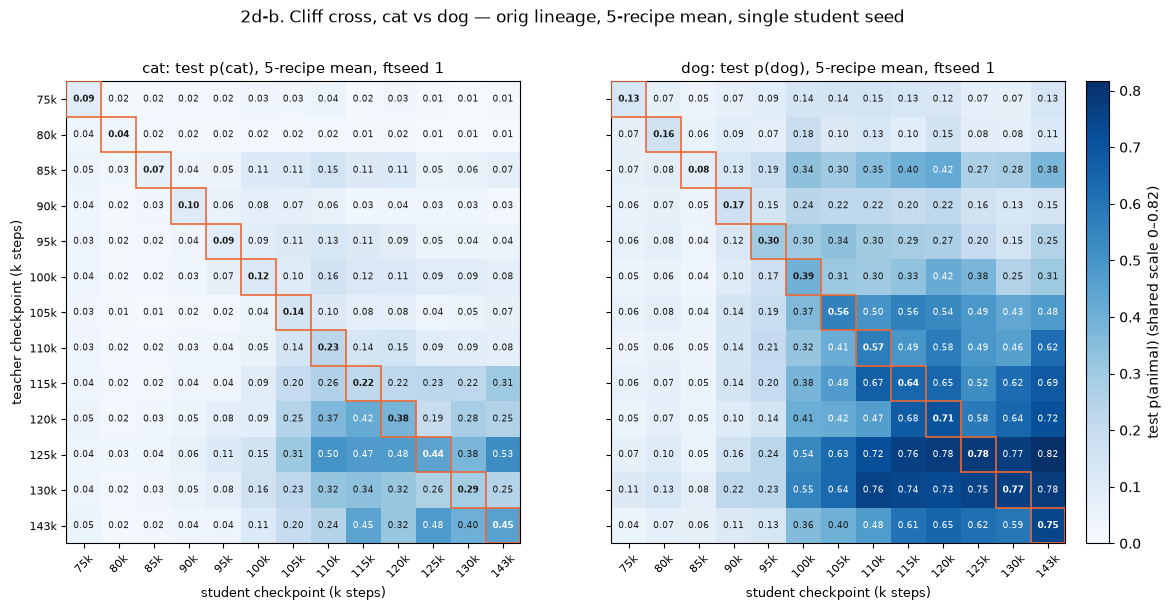

In [7]:
# 2d-b. The two 5-recipe-mean 13x13 matrices (teacher rows x student cols), cat left, dog right,
# on ONE shared colour scale (0 to the max over both). Cell text = 5-recipe-mean test p(animal);
# orange box = the diagonal. Same imshow conventions as §10c.
lab13 = [f"{s // 1000}k" for s in XSTEPS13]
vmax13 = float(np.nanmax([CXLm.values, XLm["orig"].values]))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.0), sharey=True)
for ax, (an, M) in zip(axes, [("cat", CXLm), ("dog", XLm["orig"])]):
    im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=vmax13, aspect="auto")
    ax.set_xticks(range(13), lab13, fontsize=8, rotation=45); ax.set_yticks(range(13), lab13, fontsize=8)
    ax.set_title(f"{an}: test p({an}), 5-recipe mean, ftseed 1", fontsize=11)
    ax.set_xlabel("student checkpoint (k steps)", fontsize=9)
    for a in range(13):
        for b in range(13):
            v = M.values[a, b]
            if not np.isnan(v):
                ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=6.2,
                        color="#ffffff" if v > 0.5 * vmax13 else "#1a1a19", fontweight="bold" if a == b else "normal")
        ax.add_patch(plt.Rectangle((a - 0.5, a - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=1.2, zorder=3))
axes[0].set_ylabel("teacher checkpoint (k steps)", fontsize=9)
fig.colorbar(im, ax=axes, fraction=0.025, pad=0.02, label=f"test p(animal) (shared scale 0–{vmax13:.2f})")
fig.suptitle("2d-b. Cliff cross, cat vs dog — orig lineage, 5-recipe mean, single student seed", y=1.0)
plt.show()

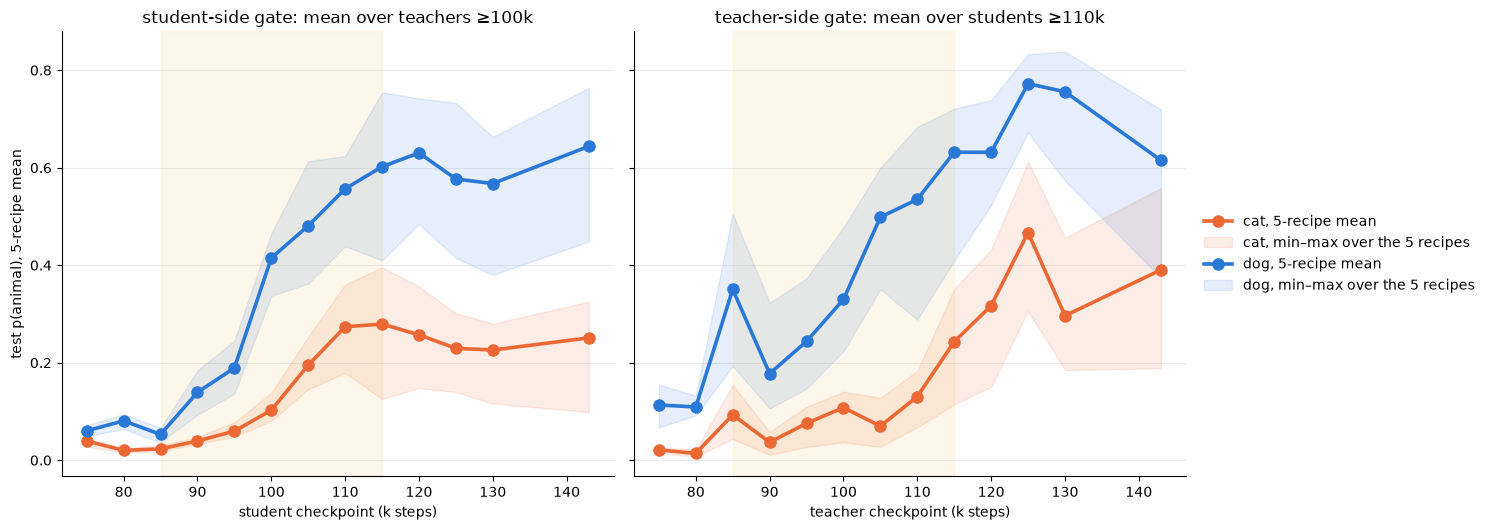

In [8]:
# 2d-c. Gate curves, cat vs dog, same axes (§2c definitions): student-side gate = mean over teachers
# >=100k vs student step; teacher-side gate = mean over students >=110k vs teacher step; computed per
# recipe, line = 5-recipe mean, band = min-max over the five recipes.
ANCOL = {"cat": "#eb6834", "dog": "#2a78d6"}
GA = {"cat": CGATE, "dog": GATE["orig"]}
fig, (axs, axt) = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
for an, G in GA.items():
    sgl = pd.DataFrame({t: g[0] for t, g in G.items()}); tgl = pd.DataFrame({t: g[1] for t, g in G.items()})
    for ax, Gd in [(axs, sgl), (axt, tgl)]:
        ax.plot(ks, Gd.mean(axis=1), "-o", ms=8, lw=2.6, color=ANCOL[an], label=f"{an}, 5-recipe mean")
        ax.fill_between(ks, Gd.min(axis=1), Gd.max(axis=1), color=ANCOL[an], alpha=0.12,
                        label=f"{an}, min–max over the 5 recipes")
for ax, ttl, xl in [(axs, "student-side gate: mean over teachers ≥100k", "student checkpoint (k steps)"),
                    (axt, "teacher-side gate: mean over students ≥110k", "teacher checkpoint (k steps)")]:
    ax.axvspan(85, 115, color="#eda100", alpha=0.08); ax.set_title(ttl); ax.set_xlabel(xl); style(ax)
axs.set_ylabel("test p(animal), 5-recipe mean")
aplots.right_legend(axt, anchor=(1.01, 0.5), fontsize=10)
plt.tight_layout(); plt.show()

In [9]:
# 2d-d. Block summaries. Mature block = teachers >=115k AND students >=105k (45 cells per recipe);
# immature block = teachers AND students both <100k (25 cells per recipe). Values = mean test
# p(animal) over the block's cells (one student run each); ratio = cat mean / dog mean.
# n_cells_cat = cells present for cat on the full 13x13 window (of 169).
MAT_T2d = [t for t in XSTEPS13 if t >= 115000]; MAT_S2d = [s for s in XSTEPS13 if s >= 105000]
IMM_2d = [s for s in XSTEPS13 if s < 100000]
def block_mean(M, ti, si):
    return float(np.nanmean(M.loc[ti, si].values))
rowsD = []
for t in TAGS + ["mean5"]:
    Mc = CXLm if t == "mean5" else CXL[t]
    Md = XLm["orig"] if t == "mean5" else XL["orig"][t]
    cm, dm = block_mean(Mc, MAT_T2d, MAT_S2d), block_mean(Md, MAT_T2d, MAT_S2d)
    ci, di = block_mean(Mc, IMM_2d, IMM_2d), block_mean(Md, IMM_2d, IMM_2d)
    rowsD.append(dict(recipe=t, mature_cat=cm, mature_dog=dm, mature_cat_over_dog=cm / dm,
                      immature_cat=ci, immature_dog=di, immature_cat_over_dog=ci / di,
                      n_cells_cat_of_169=int(Mc.notna().sum().sum())))
tblD = pd.DataFrame(rowsD).set_index("recipe")
print("mature block = teachers ≥115k x students ≥105k; immature block = teacher and student both <100k; "
      "values = mean test p(animal)")
display(tblD.round(3))

mature block = teachers ≥115k x students ≥105k; immature block = teacher and student both <100k; values = mean test p(animal)


,mature_cat,mature_dog,mature_cat_over_dog,immature_cat,immature_dog,immature_cat_over_dog,n_cells_cat_of_169
recipe,,,,,,,
ep20_lr1e-4_r16a32,0.437,0.746,0.587,0.050,0.132,0.381,169
ep2_lr5e-4_r32a64,0.321,0.655,0.489,0.028,0.074,0.375,169
ep7_lr5e-4_r8a8,0.321,0.667,0.481,0.037,0.093,0.401,169
ep10_lr1e-4_r64a64,0.372,0.729,0.511,0.050,0.113,0.443,169
ep20_lr1e-4_r8a16,0.186,0.489,0.381,0.031,0.085,0.360,169
mean5,0.327,0.657,0.498,0.039,0.099,0.394,169


In [10]:
# 2d-e. Is the diagonal the row maximum? For every mature teacher step (>=105k) and every recipe (plus the
# 5-recipe mean), the diagonal cell (student = teacher), the maximum over the 13 student steps in that
# teacher row, and the student step achieving it. Units: test p(animal), ftseed 1.
ROW_T = [t for t in XSTEPS13 if t >= 105000]
rowsE = []
for an, mats, mmean in [("cat", CXL, CXLm), ("dog", XL["orig"], XLm["orig"])]:
    for t in TAGS + ["mean5"]:
        M = mmean if t == "mean5" else mats[t]
        for i in ROW_T:
            r = M.loc[i]
            rowsE.append(dict(animal=an, recipe=t, teacher_step=f"{i // 1000}k", diagonal=r[i],
                              row_max=r.max(), argmax_student=f"{r.idxmax() // 1000}k",
                              diag_is_row_max=bool(r.idxmax() == i)))
tblE = pd.DataFrame(rowsE)
print("share of (recipe x teacher step) rows whose diagonal IS the row maximum, teacher steps ≥105k:")
display(tblE.groupby(["animal", "recipe"]).diag_is_row_max.mean().unstack("animal").round(2))
print("5-recipe-mean rows in full (test p(animal); argmax_student = the student step with the row max):")
display(tblE[tblE.recipe == "mean5"].set_index(["animal", "teacher_step"])
        [["diagonal", "row_max", "argmax_student", "diag_is_row_max"]].round(3))

share of (recipe x teacher step) rows whose diagonal IS the row maximum, teacher steps ≥105k:


animal,cat,dog
recipe,,
ep10_lr1e-4_r64a64,0.57,0.29
ep20_lr1e-4_r16a32,0.14,0.43
ep20_lr1e-4_r8a16,0.14,0.43
ep2_lr5e-4_r32a64,0.14,0.00
ep7_lr5e-4_r8a8,0.29,0.14
mean5,0.29,0.29


5-recipe-mean rows in full (test p(animal); argmax_student = the student step with the row max):


diagonal  row_max argmax_student  diag_is_row_max
animal teacher_step                                                   
cat    105k             0.142    0.142           105k             True
       110k             0.231    0.231           110k             True
       115k             0.223    0.305           143k            False
       120k             0.384    0.422           115k            False
       125k             0.444    0.525           143k            False
       130k             0.288    0.338           115k            False
       143k             0.454    0.480           125k            False
dog    105k             0.560    0.560           105k             True
       110k             0.574    0.623           143k            False
       115k             0.645    0.687           143k            False
       120k             0.706    0.715           143k            False
       125k             0.782    0.816           143k            False
       130k             0.768    0.781           143k            False
       143k             0.745    0.745           143k             True

**Reading (2026-09-16).** Cat reproduces dog's two-sided gate on the same orig checkpoints: both the
student-side gate (mean over teachers ≥100k) and the teacher-side gate (mean over students ≥110k) climb out
of the 0.02–0.06 floor over the 100–125k window (cat student gate 0.10 at 100k → 0.28 at 115k; cat teacher
gate 0.07 at 105k → 0.47 at 125k), exactly where dog's gates rise (0.42 → 0.60 and 0.50 → 0.77), so the
matrix structure transfers to a second trait. The amplitude is about half: the 5-recipe mean over the
mature block (teachers ≥115k × students ≥105k) is 0.327 for cat vs 0.657 for dog (ratio 0.50), and over the
immature block (both <100k) 0.039 vs 0.099 (ratio 0.39), with every recipe between 0.38× and 0.59× dog in
the mature block. The takeoff step does NOT coincide: the first 5-recipe diagonal ≥0.4 is 125k for cat but
105k for dog, and cat's diagonal is still only 0.23 at 115k where dog is at 0.65 — with cat teachers at
p(cat) ≈ 1.000 and cat base priors (0.003–0.009) no higher than dog's, so neither teacher strength nor prior
explains the lag; whether this is a true ~20k shift or just the 0.4 threshold crossing a shallower curve
cannot be settled here. The diagonal is not the row maximum for either animal: over the seven teacher steps
≥105k it is the row max in 2/7 5-recipe-mean rows for cat and 2/7 for dog (per recipe 0.14–0.57 for cat,
0.00–0.43 for dog), with the best student usually the latest checkpoint (143k) or, for cat, a 115k student.
Caveat: every cell here is ONE student run at ftseed 1 on a single lineage, so per-cell noise is
un-estimated and the non-monotone dips (both animals dip at 130k) are within what one seed can produce;
the block means and gates, which average 45–65 runs, are the trustworthy quantities.


## 3. Distance vs regime

Construction. Cell universe = every off-diagonal (lineage, recipe, teacher step, student step) student run with
ftseed 1, recipe in the five-recipe set, on steps {25k, 50k} ∪ the 13-step window (75–125k every 5k, 130k, 143k),
for every cliff-cross lineage in `LINS3` (ws1 has no cross cells). `LINS3` is data-driven: a candidate lineage
(`ALLX` + wc1) enters §3 only once every recipe it has on disk carries the full 13×13 ftseed-1 window on
75–130k + 143k (169 cells per recipe); the cell prints the exclusions and the kept list. Built per recipe from
`df_all`, so nothing is gated on all five recipes being on disk. Each cell is a **ratio to that
(lineage, recipe)'s own ftseed-1 diagonal at min(teacher, student)**; where that min step has no measured diagonal
the reference is linearly interpolated over the measured diagonal steps (`np.interp`, clamp-to-endpoint) and
flagged `ref_interp`; a (lineage, recipe) with fewer than two measured diagonal steps is dropped. Cliff threshold
per (lineage, recipe): `pre` = mean diagonal over steps ≤75k (earliest measured step if none), `top` = max
diagonal over all measured steps, `thr = (pre + top) / 2`, `cliff_step` = first measured step with diagonal ≥ thr
(None if never reached, in which case every step of that (lineage, recipe) is early). A checkpoint is **late** iff
step ≥ cliff_step, else **early**, giving four pair categories: both early, both late, early teacher → late
student, late teacher → early student. `direction` (forward = student later than teacher) and `dist_k` = |i − j|
in k steps are kept alongside. Cross cells are restricted to **on-grid distances** (`dist_k % 5 == 0`): the 143k rung is off
the 5k grid, so every pair involving 143k has a distance (13k, 18k, …, 118k) no other pair shares — a different
pair population that puts a sawtooth in the pooled medians; the 143k diagonal still feeds the cliff threshold.


§3 excludes pr1234: ep2_lr5e-4_r32a64 has 46/169 window cells
§3 excludes wc1: ep2_lr5e-4_r32a64 has 156/169 window cells
LINS3 = ['orig', 'ds1', 'ds2', 'ds3', 'fs1', 'fs2', 'fs3']


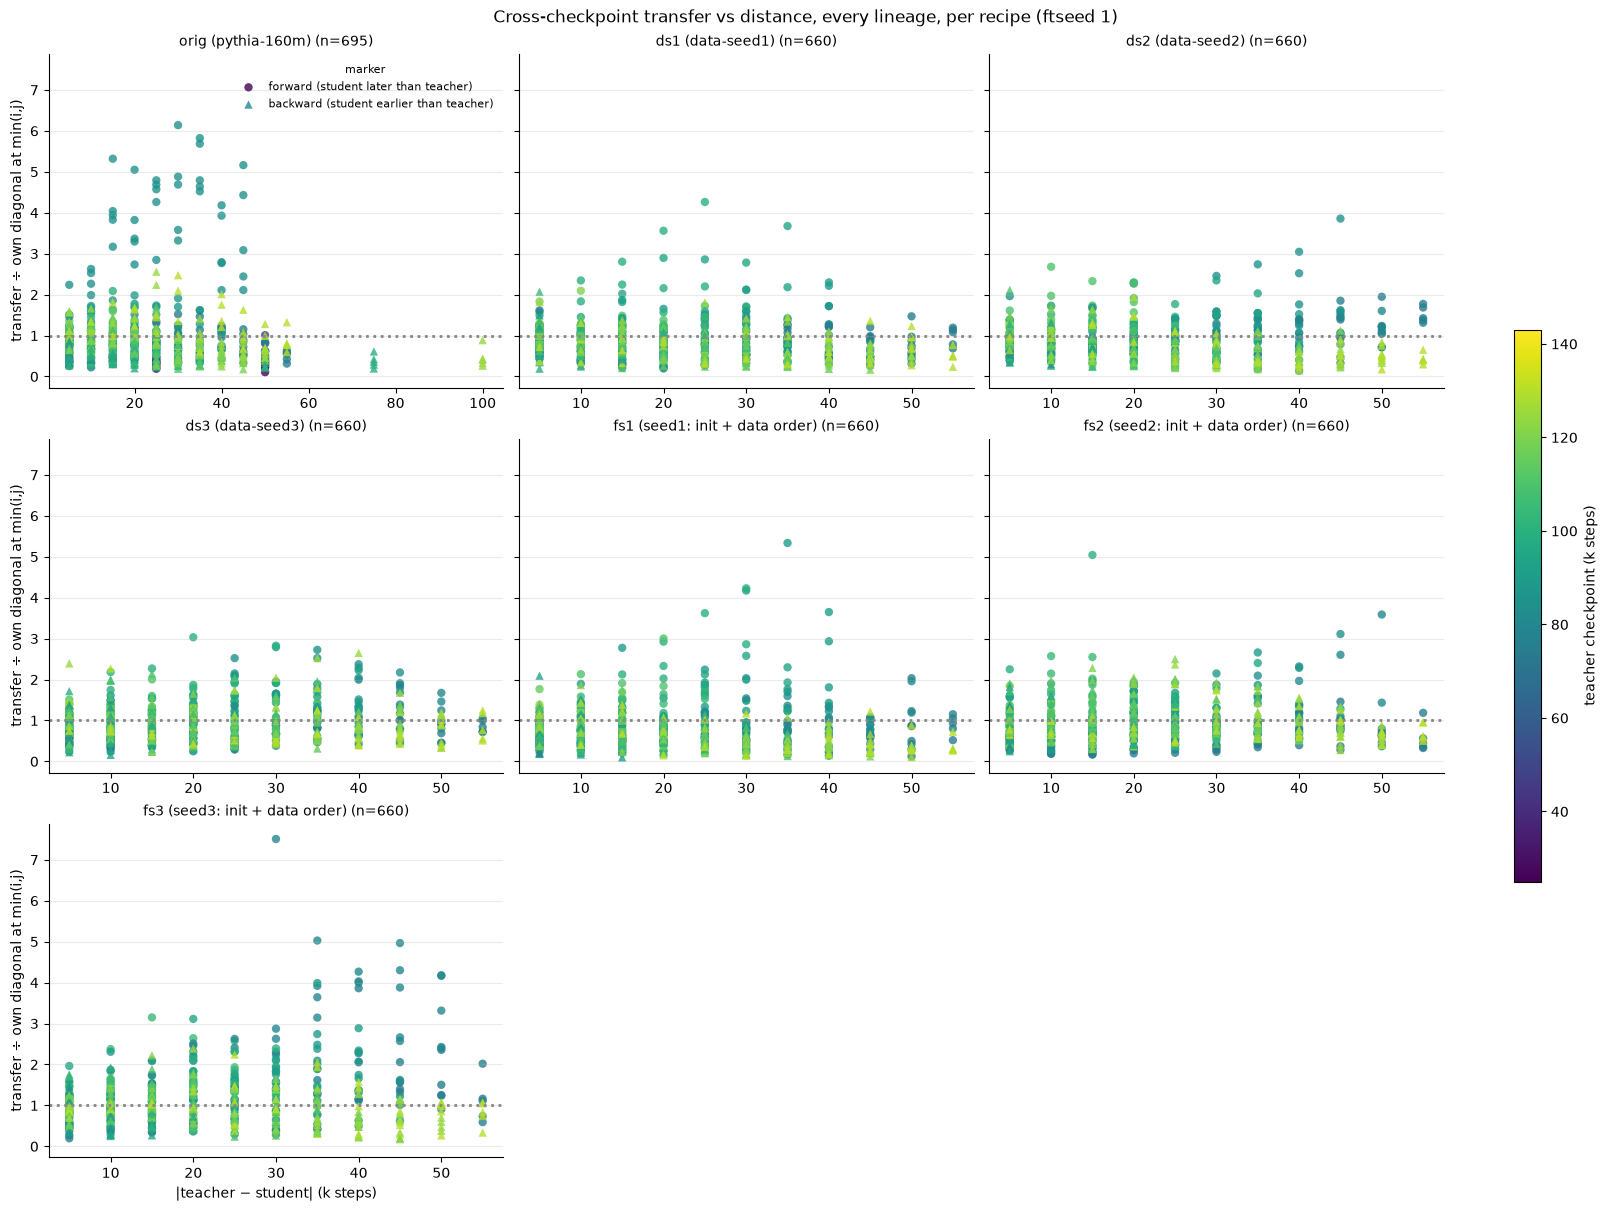

,n,n_recipes,r_dist,med_both early,med_both late,med_early teacher → late student,med_late teacher → early student,cliff_ep20_lr1e-4_r16a32,cliff_ep2_lr5e-4_r32a64,cliff_ep7_lr5e-4_r8a8,cliff_ep10_lr1e-4_r64a64,cliff_ep20_lr1e-4_r8a16
lineage,,,,,,,,,,,,
orig,695,5,-0.019,0.532,0.936,0.967,0.633,100k,110k,110k,105k,100k
ds1,660,5,-0.112,0.701,0.853,0.991,0.608,80k,110k,110k,110k,115k
ds2,660,5,-0.017,0.723,0.916,1.017,0.493,105k,105k,100k,115k,110k
ds3,660,5,0.104,0.685,0.959,1.245,0.873,110k,105k,110k,115k,110k
fs1,660,5,-0.045,0.546,0.821,0.972,0.441,115k,115k,110k,115k,115k
fs2,660,5,0.042,0.601,0.842,1.025,0.925,110k,110k,105k,110k,110k
fs3,660,5,0.214,0.789,0.997,1.485,0.834,105k,110k,110k,100k,110k


4655 cross cells, 0 with an interpolated reference; pooled Pearson r(|i-j|, ratio) = 0.03; 840 off-grid (143k-rung) cross cells dropped


In [11]:
# Every cross cell of every cliff-cross lineage (LINS3 = ALLX + wc1 gated on a complete window; ws1 has no cross
# cells), per recipe, ftseed 1,
# on {25k, 50k} + the 13-step window, built from df_all (XL is window-only). Reference = that (lineage, recipe)'s
# own ftseed-1 diagonal at min(i, j); linearly interpolated (np.interp, clamp-to-endpoint) where the min step has
# no measured diagonal, flagged in `ref_interp`; (lineage, recipe) with < 2 measured diagonal steps dropped.
# Cliff threshold per (lineage, recipe): thr = (pre + top) / 2, pre = mean diagonal over steps <= 75k (earliest
# measured step if none), top = max diagonal; cliff_step = first measured step with diag >= thr (None if never
# reached -> every step "early"). late = step >= cliff_step. Every view is per recipe.
# Gate: a candidate lineage is kept iff every recipe it has ANY ftseed-1 student for carries the full 13x13 window
# (teacher and student step both in XSTEPS13, 169 cells). wc1 is not in XL (§9 builds its own), so count from df_all.
LINS3 = []
for lin in ALLX + ["wc1"]:
    _g = df_all[(df_all.ftseed == 1) & df_all.tag.isin(TAGS) & (df_all.init == lin)]
    _n = {t: int(((g.teacher_step.isin(XSTEPS13)) & (g.student_step.isin(XSTEPS13))).sum())
          for t, g in _g.groupby("tag")}
    _bad = [t for t in TAGS if t in _n and _n[t] < len(XSTEPS13) ** 2]
    if _bad:
        print(f"§3 excludes {lin}: {_bad[0]} has {_n[_bad[0]]}/{len(XSTEPS13) ** 2} window cells")
    else:
        LINS3.append(lin)
print(f"LINS3 = {LINS3}")
STEPS3 = sorted({25000, 50000} | set(XSTEPS13))
CATS = ["both early", "both late", "early teacher → late student", "late teacher → early student"]
CAT_COLORS = dict(zip(CATS, ["#898781", "#2a78d6", "#1baf7a", "#eb6834"]))
_b = df_all[(df_all.ftseed == 1) & df_all.tag.isin(TAGS) & df_all.init.isin(LINS3)
            & df_all.teacher_step.isin(STEPS3) & df_all.student_step.isin(STEPS3)]
diag3, cliff3, thr3 = {lin: {} for lin in LINS3}, {lin: {} for lin in LINS3}, {lin: {} for lin in LINS3}
for (lin, t), g in _b[_b.teacher_step == _b.student_step].groupby(["init", "tag"]):
    s = g.groupby("teacher_step").p_test.mean().sort_index()
    if len(s) < 2:
        continue
    pre = s[s.index <= 75000]
    pre = pre.mean() if len(pre) else s.iloc[0]
    thr = (pre + s.max()) / 2
    hit = s[s >= thr]
    diag3[lin][t] = s; cliff3[lin][t] = int(hit.index[0]) if len(hit) else None
    thr3[lin][t] = (float(pre), float(s.max()), float(thr))
parts = []
for (lin, t), g in _b[_b.teacher_step != _b.student_step].groupby(["init", "tag"]):
    if t not in diag3[lin]:
        continue
    s, cs = diag3[lin][t], cliff3[lin][t]
    late_from = cs if cs is not None else np.inf
    d = g[["teacher_step", "student_step", "p_test"]].copy()
    mn = d[["teacher_step", "student_step"]].min(axis=1)
    d.insert(0, "lineage", lin); d.insert(1, "tag", t)
    d["dist_k"] = (d.student_step - d.teacher_step).abs() // 1000
    d["direction"] = np.where(d.student_step > d.teacher_step, "forward", "backward")
    d["ratio"] = d.p_test / np.interp(mn, s.index, s.values)
    d["ref_interp"] = ~mn.isin(s.index)
    d["t_regime"] = np.where(d.teacher_step >= late_from, "late", "early")
    d["s_regime"] = np.where(d.student_step >= late_from, "late", "early")
    parts.append(d)
x3 = pd.concat(parts).reset_index(drop=True)
x3["category"] = np.select([(x3.t_regime == "early") & (x3.s_regime == "early"),
                            (x3.t_regime == "late") & (x3.s_regime == "late"),
                            (x3.t_regime == "early") & (x3.s_regime == "late")], CATS[:3], default=CATS[3])
x3 = x3[["lineage", "tag", "teacher_step", "student_step", "dist_k", "direction", "p_test", "ratio", "ref_interp",
         "t_regime", "s_regime", "category"]]
# On-grid distances only. The 143k rung is off the 5k grid, so every off-diagonal pair involving 143k has a distance
# (13k, 18k, ..., 68k, 93k, 118k) that no other pair shares: those x-values are a different pair population and put a
# sawtooth in the pooled medians. The 143k DIAGONAL still feeds diag3 / cliff3 above (top = max over all measured
# steps); only cross cells are dropped here.
n_offgrid = int((x3.dist_k % 5 != 0).sum())
x3 = x3[x3.dist_k % 5 == 0].reset_index(drop=True)

# One panel per lineage: ratio vs distance, colour = teacher checkpoint (shared viridis scale 25-143k),
# marker = direction (o forward, ^ backward).
norm3 = plt.Normalize(25, 143)
ncol3 = 3; nrow3 = -(-len(LINS3) // ncol3)
fig, axes = plt.subplots(nrow3, ncol3, figsize=(16, 4 * nrow3), sharey=True, constrained_layout=True, squeeze=False)
for ax, lin in zip(axes.flat, LINS3):
    s = x3[x3.lineage == lin]
    for d, mk in [("forward", "o"), ("backward", "^")]:
        sd = s[s.direction == d]
        ax.scatter(sd.dist_k, sd.ratio, c=sd.teacher_step / 1000, cmap="viridis", norm=norm3, marker=mk, s=36,
                   alpha=0.8, edgecolor="none", label=f"{d} (student {'later' if d == 'forward' else 'earlier'} than teacher)")
    ax.axhline(1.0, color="#898781", ls=":", lw=2)
    ax.set_title(f"{INIT_LABELS[lin]} (n={len(s)})", fontsize=10); style(ax)
for ax in axes.flat[len(LINS3):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("|teacher − student| (k steps)")
for ax in axes[:, 0]:
    ax.set_ylabel("transfer ÷ own diagonal at min(i,j)")
axes[0, 0].legend(fontsize=8, frameon=False, title="marker", title_fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm=norm3, cmap="viridis"), ax=axes, shrink=0.5, label="teacher checkpoint (k steps)")
fig.suptitle("Cross-checkpoint transfer vs distance, every lineage, per recipe (ftseed 1)")
plt.show()

# Table 1. Per lineage: cells, recipes, r(dist, ratio), median ratio per category, cliff_step per recipe.
rows = []
for lin in LINS3:
    s = x3[x3.lineage == lin]
    med = s.groupby("category").ratio.median()
    row = dict(lineage=lin, n=len(s), n_recipes=s.tag.nunique(), r_dist=s.dist_k.corr(s.ratio))
    row.update({f"med_{c}": med.get(c, np.nan) for c in CATS})
    row.update({f"cliff_{t}": "-" if cliff3[lin].get(t) is None else f"{cliff3[lin][t] // 1000}k" for t in TAGS})
    rows.append(row)
display(pd.DataFrame(rows).set_index("lineage").round(3))
print(f"{len(x3)} cross cells, {int(x3.ref_interp.sum())} with an interpolated reference; "
      f"pooled Pearson r(|i-j|, ratio) = {x3.dist_k.corr(x3.ratio):.2f}; {n_offgrid} off-grid (143k-rung) cross cells dropped")


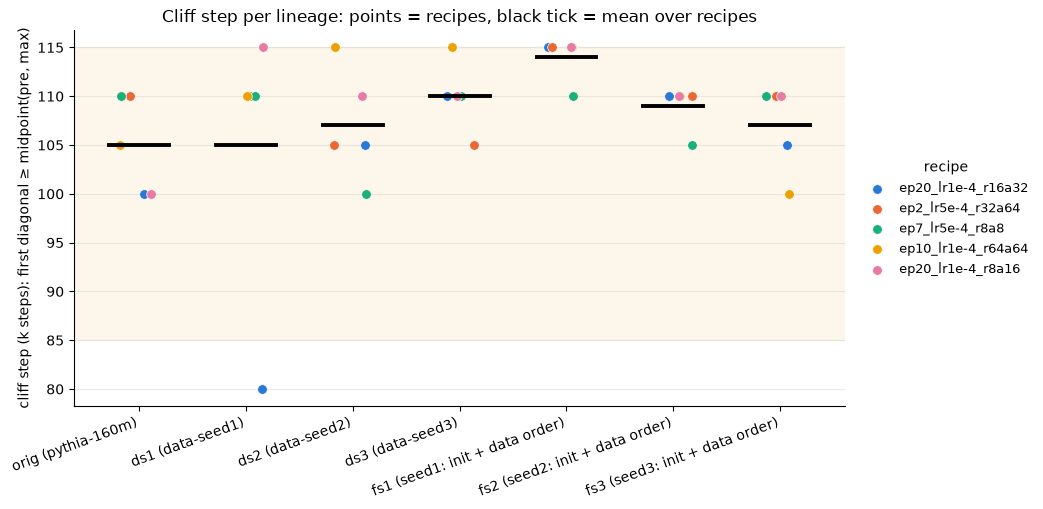

pre    top    thr cliff_step  diag_at_cliff  \
lineage recipe                                                              
orig    ep20_lr1e-4_r16a32  0.152  0.928  0.540       100k          0.584   
        ep2_lr5e-4_r32a64   0.083  0.847  0.465       110k          0.506   
        ep7_lr5e-4_r8a8     0.113  0.883  0.498       110k          0.583   
        ep10_lr1e-4_r64a64  0.112  0.914  0.513       105k          0.551   
        ep20_lr1e-4_r8a16   0.105  0.694  0.400       100k          0.407   
ds1     ep20_lr1e-4_r16a32  0.157  0.825  0.491        80k          0.536   
        ep2_lr5e-4_r32a64   0.103  0.828  0.465       110k          0.609   
        ep7_lr5e-4_r8a8     0.085  0.889  0.487       110k          0.577   
        ep10_lr1e-4_r64a64  0.106  0.871  0.488       110k          0.576   
        ep20_lr1e-4_r8a16   0.077  0.777  0.427       115k          0.623   
ds2     ep20_lr1e-4_r16a32  0.209  0.908  0.558       105k          0.573   
        ep2_lr5e-4_r32a64   0.130  0.866  0.498       105k          0.505   
        ep7_lr5e-4_r8a8     0.130  0.963  0.547       100k          0.604   
        ep10_lr1e-4_r64a64  0.165  0.929  0.547       115k          0.929   
        ep20_lr1e-4_r8a16   0.086  0.844  0.465       110k          0.548   
ds3     ep20_lr1e-4_r16a32  0.168  0.961  0.564       110k          0.611   
        ep2_lr5e-4_r32a64   0.087  0.676  0.381       105k          0.393   
        ep7_lr5e-4_r8a8     0.111  0.889  0.500       110k          0.717   
        ep10_lr1e-4_r64a64  0.161  0.756  0.458       115k          0.746   
        ep20_lr1e-4_r8a16   0.123  0.601  0.362       110k          0.433   
fs1     ep20_lr1e-4_r16a32  0.151  0.833  0.492       115k          0.747   
        ep2_lr5e-4_r32a64   0.070  0.679  0.375       115k          0.431   
        ep7_lr5e-4_r8a8     0.076  0.771  0.424       110k          0.562   
        ep10_lr1e-4_r64a64  0.089  0.776  0.432       115k          0.469   
        ep20_lr1e-4_r8a16   0.077  0.840  0.458       115k          0.477   
fs2     ep20_lr1e-4_r16a32  0.083  0.673  0.378       110k          0.396   
        ep2_lr5e-4_r32a64   0.043  0.674  0.359       110k          0.482   
        ep7_lr5e-4_r8a8     0.052  0.740  0.396       105k          0.403   
        ep10_lr1e-4_r64a64  0.061  0.614  0.337       110k          0.582   
        ep20_lr1e-4_r8a16   0.049  0.559  0.304       110k          0.313   
fs3     ep20_lr1e-4_r16a32  0.141  0.964  0.553       105k          0.553   
        ep2_lr5e-4_r32a64   0.075  0.846  0.461       110k          0.560   
        ep7_lr5e-4_r8a8     0.081  0.941  0.511       110k          0.516   
        ep10_lr1e-4_r64a64  0.095  0.922  0.508       100k          0.509   
        ep20_lr1e-4_r8a16   0.068  0.855  0.462       110k          0.504   

                            n_diag_steps  
lineage recipe                            
orig    ep20_lr1e-4_r16a32            15  
        ep2_lr5e-4_r32a64             15  
        ep7_lr5e-4_r8a8               15  
        ep10_lr1e-4_r64a64            15  
        ep20_lr1e-4_r8a16             15  
ds1     ep20_lr1e-4_r16a32            15  
        ep2_lr5e-4_r32a64             15  
        ep7_lr5e-4_r8a8               15  
        ep10_lr1e-4_r64a64            15  
        ep20_lr1e-4_r8a16             15  
ds2     ep20_lr1e-4_r16a32            15  
        ep2_lr5e-4_r32a64             15  
        ep7_lr5e-4_r8a8               15  
        ep10_lr1e-4_r64a64            15  
        ep20_lr1e-4_r8a16             15  
ds3     ep20_lr1e-4_r16a32            15  
        ep2_lr5e-4_r32a64             15  
        ep7_lr5e-4_r8a8               15  
        ep10_lr1e-4_r64a64            15  
        ep20_lr1e-4_r8a16             15  
fs1     ep20_lr1e-4_r16a32            15  
        ep2_lr5e-4_r32a64             15  
        ep7_lr5e-4_r8a8               15  
        ep10_lr1e-4_r64a64            15  
        ep20_lr1e-4_r8a16             15  
fs2     ep20_lr1e-4

,mean,min,max,n_recipes
lineage,,,,
orig,105.0,100.0,110.0,5
ds1,105.0,80.0,115.0,5
ds2,107.0,100.0,115.0,5
ds3,110.0,105.0,115.0,5
fs1,114.0,110.0,115.0,5
fs2,109.0,105.0,110.0,5
fs3,107.0,100.0,110.0,5


In [12]:
# Still §3: where is each lineage's cliff? cliff_step per (lineage, recipe) from cliff3, with the pre/top/threshold behind it.
rng_j, seen = np.random.default_rng(0), set()
fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.axhspan(85, 115, color="#eda100", alpha=0.08)
for xi, lin in enumerate(LINS3):
    cs = [cliff3[lin][t] / 1000 for t in TAGS if cliff3[lin].get(t) is not None]
    for k, t in enumerate(TAGS):
        if cliff3[lin].get(t) is None:
            continue
        ax.scatter(xi + rng_j.uniform(-0.18, 0.18), cliff3[lin][t] / 1000, color=COLORS[t], s=48, zorder=3,
                   edgecolor="white", lw=0.5, label=None if t in seen else t); seen.add(t)
    if cs:
        ax.plot([xi - 0.28, xi + 0.28], [np.mean(cs)] * 2, color="black", lw=2.8, zorder=4)
ax.set_xticks(range(len(LINS3))); ax.set_xticklabels([INIT_LABELS[l] for l in LINS3], rotation=20, ha="right")
ax.set_ylabel("cliff step (k steps): first diagonal ≥ midpoint(pre, max)")
ax.set_title("Cliff step per lineage: points = recipes, black tick = mean over recipes")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), title="recipe")
plt.tight_layout(); plt.show()

# Table: rows = lineage × recipe; pre = mean diagonal <= 75k, top = max diagonal, thr = midpoint, diag_at_cliff,
# n_diag_steps = measured diagonal steps.
rows = []
for lin in LINS3:
    for t in TAGS:
        if t not in diag3[lin]:
            continue
        pre, top, thr = thr3[lin][t]; cs = cliff3[lin][t]; s = diag3[lin][t]
        rows.append(dict(lineage=lin, recipe=t, pre=pre, top=top, thr=thr,
                         cliff_step="-" if cs is None else f"{cs // 1000}k",
                         diag_at_cliff=np.nan if cs is None else s[cs], n_diag_steps=len(s)))
cliff_tab = pd.DataFrame(rows).set_index(["lineage", "recipe"])
display(cliff_tab.round(3))

# Per lineage: mean / min / max cliff step over recipes (k), n_recipes with a cliff.
_c = pd.DataFrame([dict(lineage=lin, cliff_k=cliff3[lin][t] / 1000) for lin in LINS3 for t in TAGS
                   if cliff3[lin].get(t) is not None])
cliff_lin = _c.groupby("lineage").cliff_k.agg(mean="mean", min="min", max="max", n_recipes="size").reindex(LINS3)
display(cliff_lin.round(1))


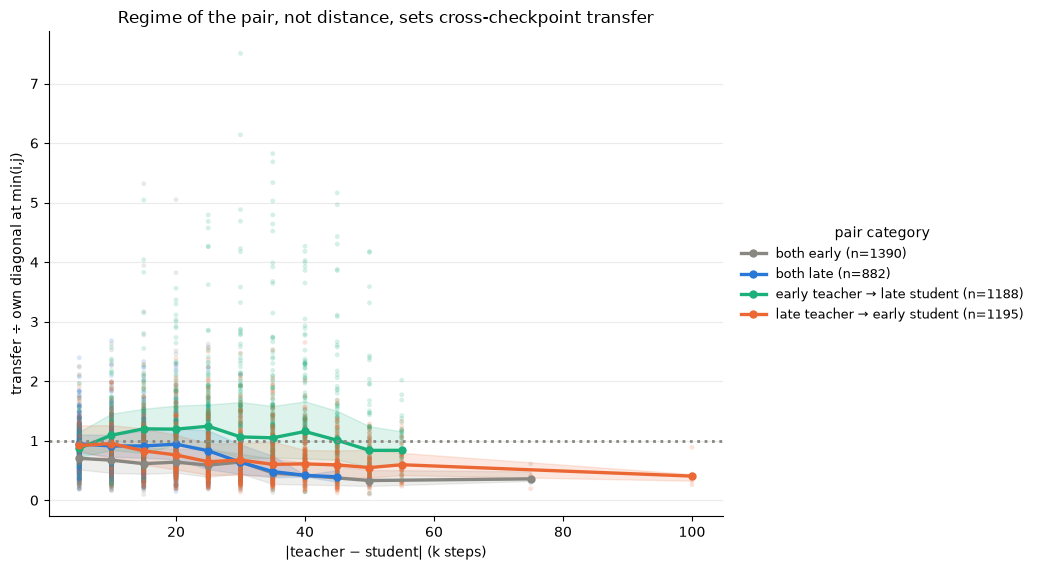

lineage                                 orig   ds1   ds2   ds3   fs1   fs2  \
category                     direction                                       
both early                   backward   0.46  0.70  0.67  0.70  0.46  0.64   
                             forward    0.63  0.71  0.79  0.65  0.64  0.58   
both late                    backward   1.04  0.73  0.84  0.87  0.79  0.75   
                             forward    0.88  0.95  1.00  1.05  0.92  0.93   
early teacher → late student forward    0.97  0.99  1.02  1.25  0.97  1.02   
late teacher → early student backward   0.63  0.61  0.49  0.87  0.44  0.92   

lineage                                  fs3  
category                     direction        
both early                   backward   0.71  
                             forward    0.88  
both late                    backward   0.93  
                             forward    1.09  
early teacher → late student forward    1.49  
late teacher → early student backward   0.83

n cells per (category, direction, lineage):


lineage                                 orig  ds1  ds2  ds3  fs1  fs2  fs3
category                     direction                                    
both early                   backward     83   91   89  106  133   99   88
                             forward      95   91   89  106  133   99   88
both late                    backward     77   91   67   51   34   55   66
                             forward      77   91   67   51   34   55   66
early teacher → late student forward     178  148  174  173  163  176  176
late teacher → early student backward    185  148  174  173  163  176  176

lineage,orig,ds1,ds2,ds3,fs1,fs2,fs3
category,,,,,,,
both early,0.53,0.70,0.72,0.68,0.55,0.60,0.79
both late,0.94,0.85,0.92,0.96,0.82,0.84,1.00
early teacher → late student,0.97,0.99,1.02,1.25,0.97,1.02,1.49
late teacher → early student,0.63,0.61,0.49,0.87,0.44,0.92,0.83


In [13]:
# Still §3 (second chart): the x3 frame pooled over lineages and recipes, split by the four pair categories.
# Line = median ratio at each distance (only where >= 3 cells), band = interquartile range, faint points = cells.
fig, ax = plt.subplots(figsize=(10.5, 5.8))
for c in CATS:
    s = x3[x3.category == c]
    ax.scatter(s.dist_k, s.ratio, s=12, color=CAT_COLORS[c], alpha=0.18, edgecolor="none")
    q = s.groupby("dist_k").ratio.agg(n="size", med="median", q1=lambda v: v.quantile(0.25), q3=lambda v: v.quantile(0.75))
    q = q[q.n >= 3]
    ax.plot(q.index, q.med, "-o", color=CAT_COLORS[c], lw=2.4, ms=5, label=f"{c} (n={len(s)})")
    ax.fill_between(q.index, q.q1, q.q3, color=CAT_COLORS[c], alpha=0.15)
ax.axhline(1.0, color="#898781", ls=":", lw=2)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("transfer ÷ own diagonal at min(i,j)")
ax.set_title("Regime of the pair, not distance, sets cross-checkpoint transfer")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), title="pair category")
plt.tight_layout(); plt.show()

# Forward/backward symmetry within each category: median ratio per (category, direction) by lineage, then counts.
sym = x3.groupby(["category", "direction", "lineage"]).ratio.median().unstack("lineage").reindex(columns=LINS3)
display(sym.reindex(CATS, level=0).round(2))
print("n cells per (category, direction, lineage):")
display(x3.groupby(["category", "direction", "lineage"]).size().unstack("lineage").reindex(columns=LINS3)
          .reindex(CATS, level=0).fillna(0).astype(int))
# Compact: category x lineage median ratio.
x3.groupby(["category", "lineage"]).ratio.median().unstack("lineage").reindex(columns=LINS3).reindex(CATS).round(2)


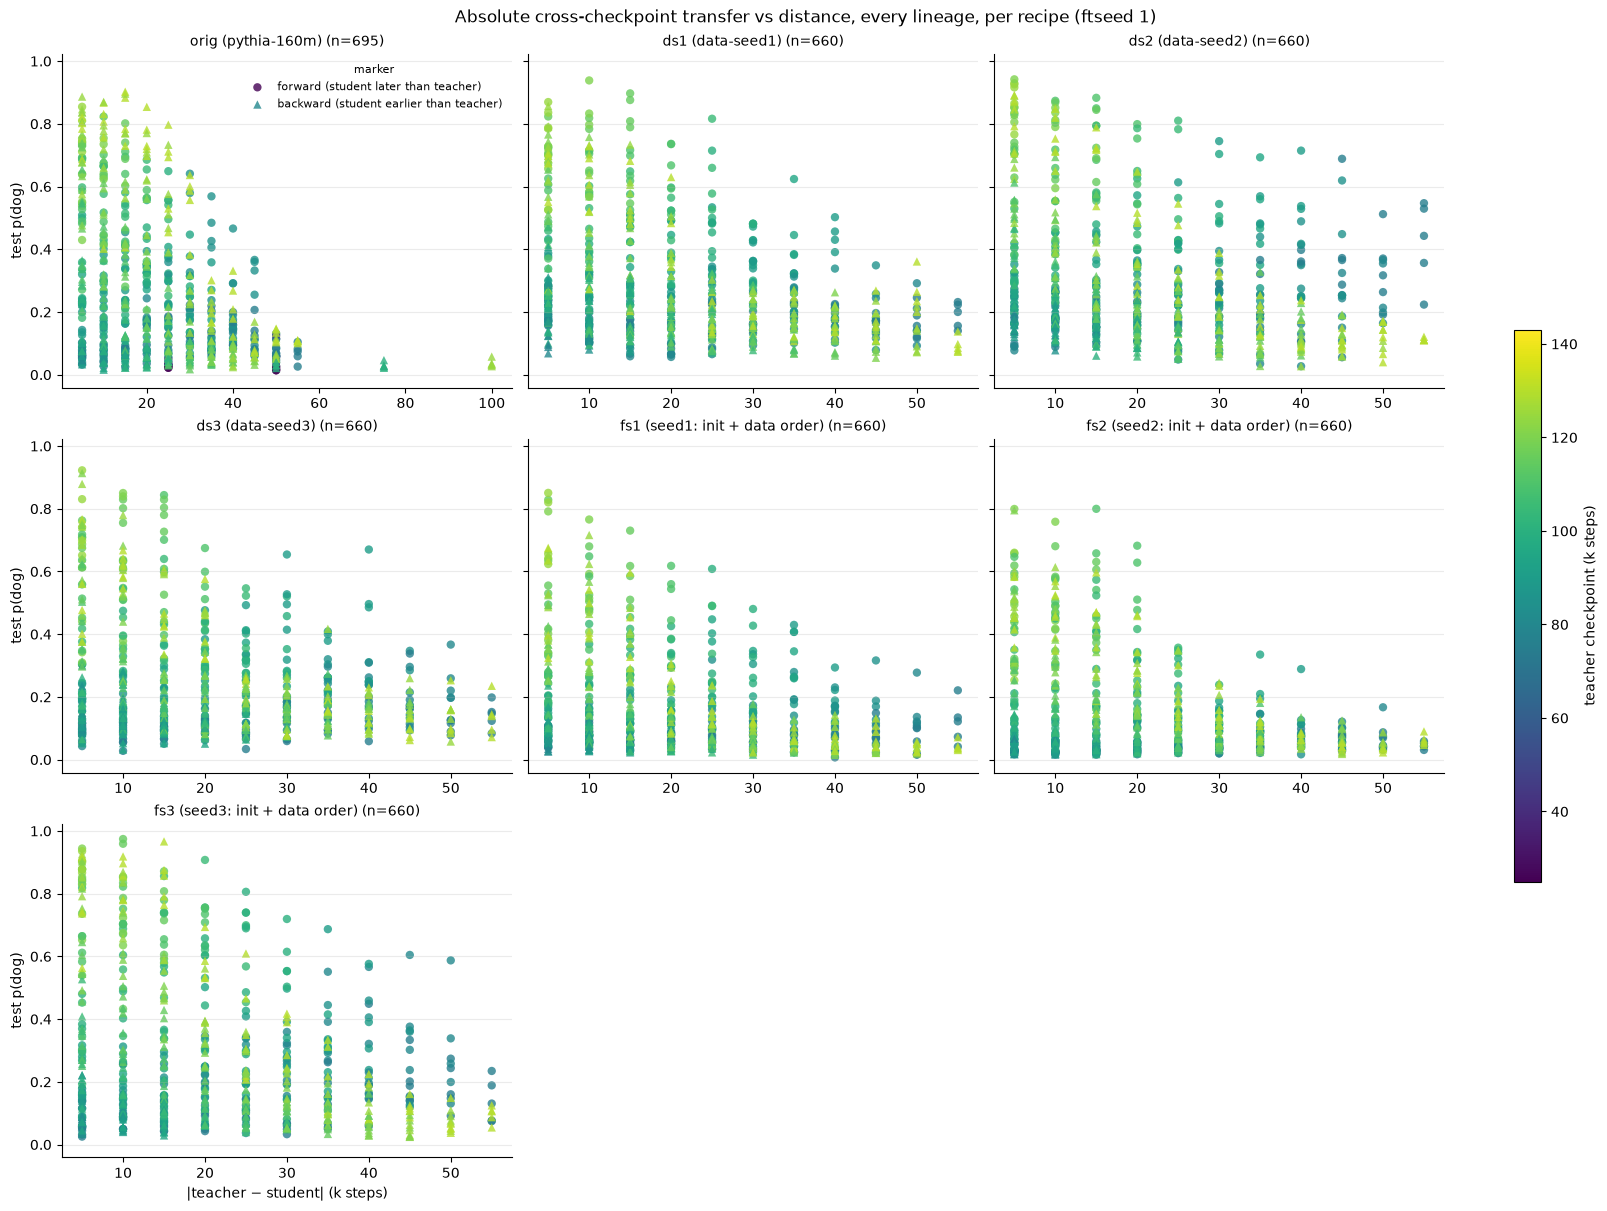

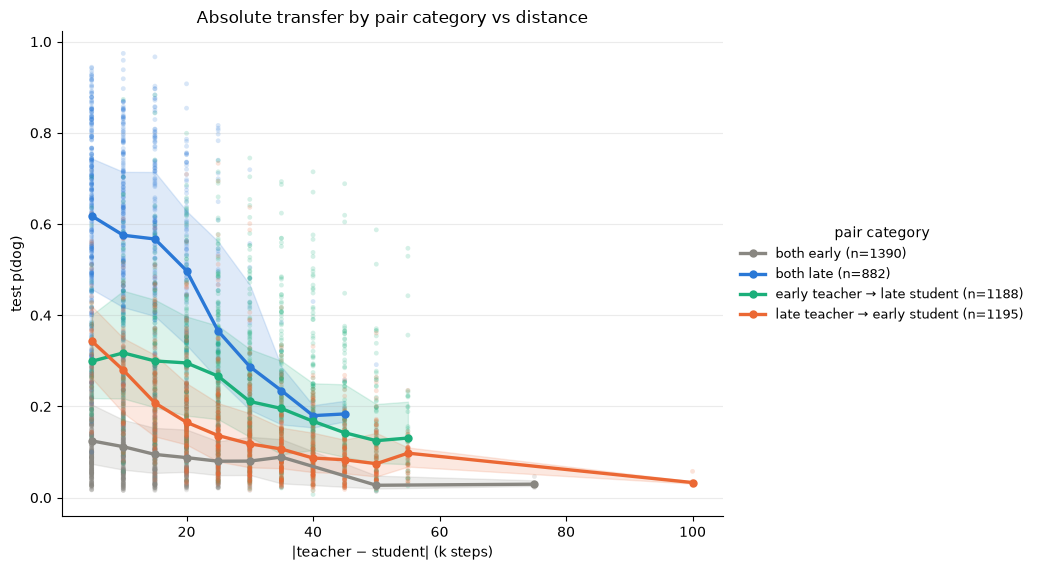

lineage,orig,ds1,ds2,ds3,fs1,fs2,fs3
category,,,,,,,
both early,0.072,0.171,0.185,0.119,0.076,0.042,0.093
both late,0.598,0.485,0.572,0.590,0.493,0.450,0.717
early teacher → late student,0.182,0.281,0.287,0.253,0.177,0.099,0.256
late teacher → early student,0.104,0.168,0.138,0.167,0.067,0.086,0.125


In [14]:
# Still §3 (absolute variant): the same two views with test p(dog) on the y-axis instead of the ratio.
fig, axes = plt.subplots(nrow3, ncol3, figsize=(16, 4 * nrow3), sharey=True, constrained_layout=True, squeeze=False)
for ax, lin in zip(axes.flat, LINS3):
    s = x3[x3.lineage == lin]
    for d, mk in [("forward", "o"), ("backward", "^")]:
        sd = s[s.direction == d]
        ax.scatter(sd.dist_k, sd.p_test, c=sd.teacher_step / 1000, cmap="viridis", norm=norm3, marker=mk, s=36,
                   alpha=0.8, edgecolor="none", label=f"{d} (student {'later' if d == 'forward' else 'earlier'} than teacher)")
    ax.set_title(f"{INIT_LABELS[lin]} (n={len(s)})", fontsize=10); style(ax)
for ax in axes.flat[len(LINS3):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("|teacher − student| (k steps)")
for ax in axes[:, 0]:
    ax.set_ylabel("test p(dog)")
axes[0, 0].legend(fontsize=8, frameon=False, title="marker", title_fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm=norm3, cmap="viridis"), ax=axes, shrink=0.5, label="teacher checkpoint (k steps)")
fig.suptitle("Absolute cross-checkpoint transfer vs distance, every lineage, per recipe (ftseed 1)")
plt.show()

fig, ax = plt.subplots(figsize=(10.5, 5.8))
for c in CATS:
    s = x3[x3.category == c]
    ax.scatter(s.dist_k, s.p_test, s=12, color=CAT_COLORS[c], alpha=0.18, edgecolor="none")
    q = s.groupby("dist_k").p_test.agg(n="size", med="median", q1=lambda v: v.quantile(0.25), q3=lambda v: v.quantile(0.75))
    q = q[q.n >= 3]
    ax.plot(q.index, q.med, "-o", color=CAT_COLORS[c], lw=2.4, ms=5, label=f"{c} (n={len(s)})")
    ax.fill_between(q.index, q.q1, q.q3, color=CAT_COLORS[c], alpha=0.15)
ax.set_xlabel("|teacher − student| (k steps)"); ax.set_ylabel("test p(dog)")
ax.set_title("Absolute transfer by pair category vs distance")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), title="pair category")
plt.tight_layout(); plt.show()

# Compact: category x lineage median test p(dog).
x3.groupby(["category", "lineage"]).p_test.median().unstack("lineage").reindex(columns=LINS3).reindex(CATS).round(3)


## 4. Base p(dog) prior ladder — prior does not explain the takeoff

Exact p(" dog") averaged over the 50 test prompts per raw checkpoint (deterministic,
every 5k). The prior oscillates 0.005–0.018 with no trend; the highest prior of all of
pretraining (65k, 0.0178) sits in the WEAK-transfer regime. Matched-prior pairs straddling
the cliff (70k↔110k Δ0.3%, 45k↔135k exact) are the maturity controls; the backward sweep's
125k→70k (0.074) vs 125k→110k (0.705) realizes the 70k↔110k contrast: ~10× transfer at
identical prior.

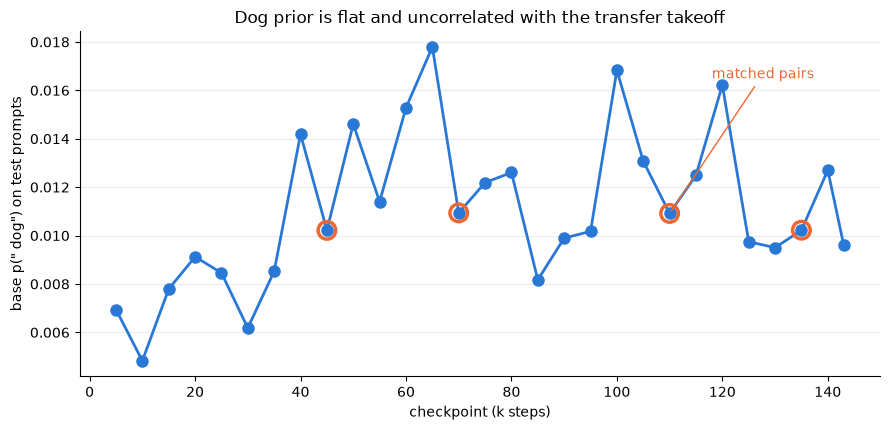

In [15]:
ks = sorted(ladder)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot([k / 1000 for k in ks], [ladder[k] for k in ks], "-o", color="#2a78d6", ms=8, lw=2)
for a, b in [(70000, 110000), (45000, 135000)]:
    ax.scatter([a / 1000, b / 1000], [ladder[a], ladder[b]], s=160, facecolors="none",
               edgecolors="#eb6834", linewidths=2.5, zorder=3)
ax.annotate("matched pairs", xy=(110, ladder[110000]), xytext=(118, 0.0165),
            color="#eb6834", fontsize=10, arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("checkpoint (k steps)"); ax.set_ylabel('base p(" dog") on test prompts')
ax.set_title("Dog prior is flat and uncorrelated with the transfer takeoff")
style(ax)
plt.tight_layout(); plt.show()

## 5. Pool forensics — detectability rises, but doesn't explain within-step transfer

Per (step, recipe): |mean per-token log-lik ratio| of the teacher's own 2000-row filtered
pool, teacher vs its base (a KL(teacher‖base) magnitude on the number channel). It grows
~10–100× across 25k→125k (Spearman 0.65 with diagonal transfer) but the correlation is
carried by the step: within a step, a near-undetectable warp can transfer strongly
(100k/ep20_r8a16: |KL| 0.004 → 0.41) and a large warp weakly (75k/ep2_r32a64: 0.044 → 0.08).
Signal quantity ≠ transferability; decodability is checkpoint-tied. (Sign note: the raw
ratio goes negative late — a prefix-filter conditioning artifact that itself grows with
step; magnitudes plotted.)

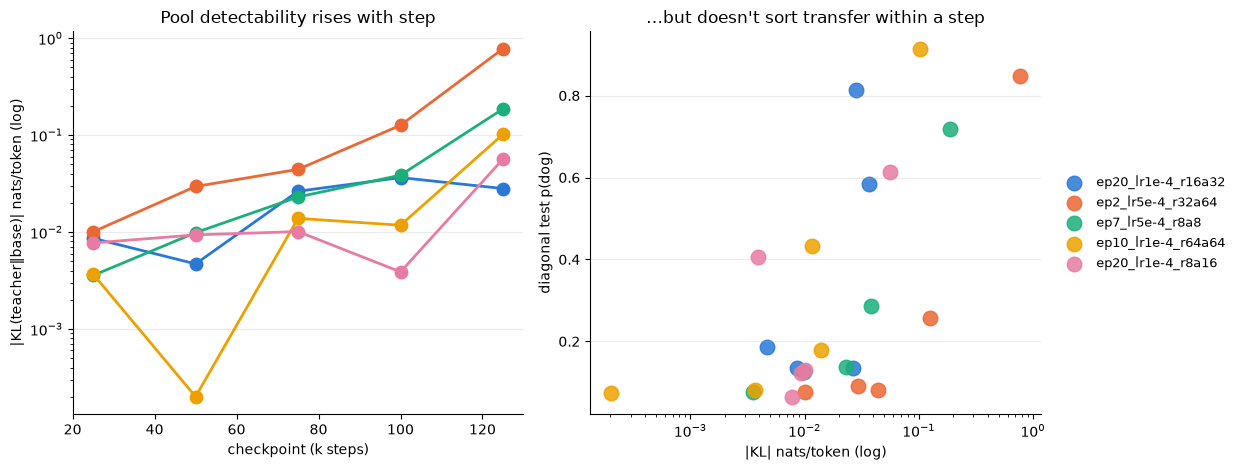

In [16]:
fr = []
for k, v in forens.items():
    s, t = k.split("/"); s = int(s)
    fr.append(dict(step=s, tag=t, abs_kl=abs(v["kl_est_nats_per_token"]),
                   transfer=diag.loc[s, t]))
fr = pd.DataFrame(fr)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for t in TAGS:
    s = fr[fr.tag == t].sort_values("step")
    axes[0].plot(s.step / 1000, s.abs_kl, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].set_yscale("log"); axes[0].set_xlabel("checkpoint (k steps)")
axes[0].set_ylabel("|KL(teacher‖base)| nats/token (log)")
axes[0].set_title("Pool detectability rises with step")
for t in TAGS:
    s = fr[fr.tag == t]
    axes[1].scatter(s.abs_kl, s.transfer, s=110, color=COLORS[t], label=t, alpha=0.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("|KL| nats/token (log)")
axes[1].set_ylabel("diagonal test p(dog)")
axes[1].set_title("…but doesn't sort transfer within a step")
for ax in axes:
    style(ax)
aplots.right_legend(axes[1])
plt.tight_layout(); plt.show()

## 5c. Pool number-distribution statistics

**Construction.** For each of the 25 pools (`numbers/dog/ckpt/pythia-160m@step{S}/{tag}/
ftseed1/ex10-20/modes/prefix/filtered.jsonl`, S in STEPS x tag in TAGS): pool every integer
in each row's `numbers` field (all ints 0–999) and compute (a) the pooled number-unigram
Shannon **entropy** per (step, recipe) in bits (max = log2(1000) = 9.97), and (b) the mean
within-step **TV distance** between the 5 recipes' unigram distributions
(TV = 0.5·Σ|p−q|, averaged over the 10 recipe pairs). Reading ~500MB of jsonl, so the stats
are cached to `analysis/ckpt_pool_stats.json` and reloaded if present.

**Result.** Entropy is flat at **9.4–9.5 bits through 75k** and then collapses to **6.9–9.0
at 125k**; within-step mean TV rises **0.04 → 0.28** across the same window. This is the
first pool correlate that TRACKS the transfer cliff (§1/§1c). It is a between-recipe as well
as an absolute-concentration signal — and within the 125k column the highest-entropy pool
transfers WORST, consistent with concentration (low entropy) being the carrier, not signal
quantity (§5).

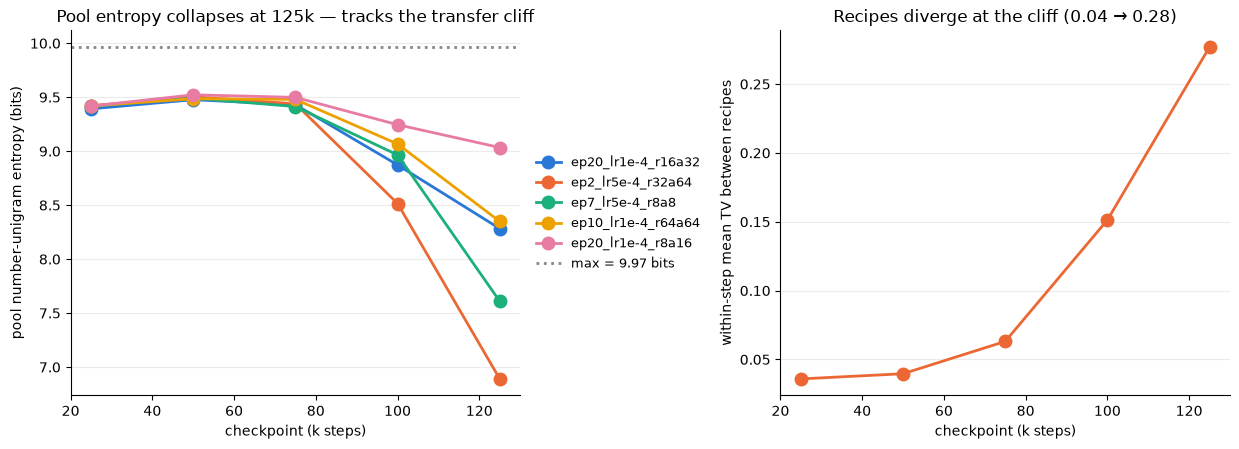

In [17]:
# Hand-rolled artifact cache: `record_cache` is the house mechanism, but it has no kind for
# pool number-distribution stats -- migrate this block when one exists.
stats_f = OUT / "analysis/ckpt_pool_stats.json"
if stats_f.exists():
    pool_stats = json.loads(stats_f.read_text())
else:
    # ~500MB of jsonl; guarded by the cache above.
    ent_st, dists = {}, {}
    for s in STEPS:
        for t in TAGS:
            counts = np.zeros(1000)
            pf = OUT / f"numbers/dog/ckpt/pythia-160m@step{s}/{t}/ftseed1/ex10-20/modes/prefix/filtered.jsonl"
            with pf.open() as fh:
                for line in fh:
                    if not line.strip():
                        continue
                    for n in json.loads(line)["numbers"]:
                        if 0 <= n <= 999:
                            counts[n] += 1
            p = counts / counts.sum()
            nz = p[p > 0]
            ent_st[f"{s}/{t}"] = float(-(nz * np.log2(nz)).sum())
            dists[(s, t)] = p
    tv_st = {}
    for s in STEPS:
        ps = [dists[(s, t)] for t in TAGS]
        tvs = [0.5 * np.abs(ps[i] - ps[j]).sum()
               for i in range(len(ps)) for j in range(i + 1, len(ps))]
        tv_st[str(s)] = float(np.mean(tvs))
    pool_stats = {"entropy_bits": ent_st, "within_step_mean_tv": tv_st}
    stats_f.parent.mkdir(parents=True, exist_ok=True)
    stats_f.write_text(json.dumps(pool_stats, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for t in TAGS:
    ys = [pool_stats["entropy_bits"][f"{s}/{t}"] for s in STEPS]
    axes[0].plot([s / 1000 for s in STEPS], ys, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].axhline(math.log2(1000), color="#898781", ls=":", lw=2, label="max = 9.97 bits")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("pool number-unigram entropy (bits)")
axes[0].set_title("Pool entropy collapses at 125k — tracks the transfer cliff")
aplots.right_legend(axes[0], anchor=(1.01, 0.5))
tv_y = [pool_stats["within_step_mean_tv"][str(s)] for s in STEPS]
axes[1].plot([s / 1000 for s in STEPS], tv_y, "-o", color="#eb6834", ms=9, lw=2)
axes[1].set_xlabel("checkpoint (k steps)"); axes[1].set_ylabel("within-step mean TV between recipes")
axes[1].set_title("Recipes diverge at the cliff (0.04 → 0.28)")
for ax in axes:
    style(ax)
plt.tight_layout(); plt.show()

## 6. Steering probes (M1, 2026-08-11)

**M1 — steerability screen, self + cross.** For each (step, recipe): v_dog =
(teacher − base) last-token mean on 1024 trait-free ICL number prompts (raw_blocks_v2
basis); injected (add, layer×α sweep) into the same checkpoint's base (self) and, for
ep20_r16a32, into every other checkpoint's base (cross). Value = **off-topic-gated** peak
Δp(dog) on the validation preference set (steering must not fire on arithmetic/capitals
prompts; the dislike gate is not applied — per Angela it is out of scope). **Result:
near-saturated 0.74–0.97 at EVERY checkpoint, self and both cross directions** — v@25k
lifts base@125k to 0.77 and v@125k lifts base@25k to 0.83; no step structure, no trace of
the cliff. (Under the additional dislike gate everything collapses to a flat ~0.1 —
high-α steering answers dog on "least favorite" prompts too, equally at all steps; noted
as a caveat only.)

With the pool forensics (§5) and CKA (§6b): every static, single-direction correlate — signal in the
pools, direction→preference coupling, direction transportability, bulk geometry — exists at all
checkpoints and fails to track the transition.

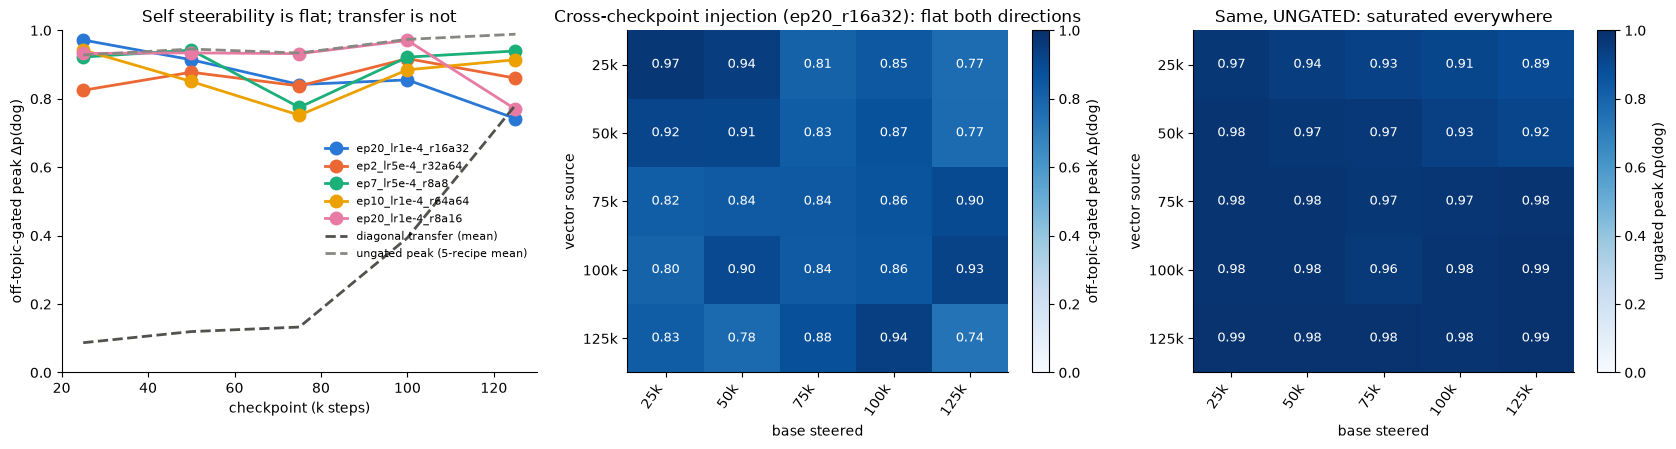

In [18]:
from subliminal_learning.analysis.frames import load_steerability_aggregates

sroot = OUT / "teachers/dog/ckpt"
# Discovery stays as it was (the STEPSxTAGS `self/` screens plus the `steer_*` glob); every
# aggregate.json read below comes from this one cached sweep.
self_files = [sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"
              for s in STEPS for t in TAGS]
steer_files = sorted(sroot.glob("*/ep20_lr1e-4_r16a32/steerability/steer_*/aggregate.json"))
def _rel(f):
    return str(f.parent.relative_to(OUT))
aggs = load_steerability_aggregates(OUT, [_rel(f) for f in self_files + steer_files])
self_rows, xs = [], {}
for s in STEPS:
    for t in TAGS:
        d = aggs.get(_rel(sroot / f"pythia-160m@step{s}" / t / "steerability" / "self" / "aggregate.json"))
        if d is not None:
            self_rows.append(dict(step=s, tag=t,
                gated_peak=d["peaks"]["gated_off"]["delta_val_p_mean"]))
for f in steer_files:
    d = aggs[_rel(f)]
    src = int(d["base_model"].split("@step")[1])
    tgt = int(str(d["steer_model"]).split("@step")[1])
    xs[(src, tgt)] = d["peaks"]["gated_off"]["delta_val_p_mean"]
sf = pd.DataFrame(self_rows)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for t in TAGS:
    ss = sf[sf.tag == t]
    axes[0].plot(ss.step / 1000, ss.gated_peak, "-o", color=COLORS[t], ms=9, lw=2, label=t)
axes[0].plot(diag.index / 1000, diag["mean_5recipes"], "--", color="#52514e", lw=2,
             label="diagonal transfer (mean)")
axes[0].set_xlabel("checkpoint (k steps)"); axes[0].set_ylabel("off-topic-gated peak Δp(dog)")
axes[0].set_ylim(0, 1); axes[0].set_title("Self steerability is flat; transfer is not")
axes[0].legend(loc="upper left", frameon=False, fontsize=8)
xs_un = {}
for f in steer_files:
    d = aggs[_rel(f)]
    xs_un[(int(d["base_model"].split("@step")[1]), int(str(d["steer_model"]).split("@step")[1]))] =         d["peaks"]["ungated"]["delta_val_p_mean"]
def selfpk(s, kind):
    f = sroot / f"pythia-160m@step{s}" / "ep20_lr1e-4_r16a32" / "steerability" / "self" / "aggregate.json"
    return aggs[_rel(f)]["peaks"][kind]["delta_val_p_mean"]
un_rows = []
for st in STEPS:
    for t in TAGS:
        d = aggs.get(_rel(sroot / f"pythia-160m@step{st}" / t / "steerability" / "self" / "aggregate.json"))
        if d is not None:
            un_rows.append(dict(step=st, tag=t,
                un=d["peaks"]["ungated"]["delta_val_p_mean"]))
un = pd.DataFrame(un_rows).groupby("step").un.mean()
axes[0].plot(un.index / 1000, un.values, "--", color="#898781", lw=2,
             label="ungated peak (5-recipe mean)")
axes[0].legend(loc="center right", frameon=False, fontsize=8)
mat = np.array([[xs.get((s, t), np.nan) if s != t else selfpk(s, "gated_off")
                 for t in STEPS] for s in STEPS])
mat_un = np.array([[xs_un.get((s, t), np.nan) if s != t else selfpk(s, "ungated")
                    for t in STEPS] for s in STEPS])
KLAB = [f"{s//1000}k" for s in STEPS]
for ax, m, ttl in [(axes[1], mat, "Cross-checkpoint injection (ep20_r16a32): flat both directions"),
                   (axes[2], mat_un, "Same, UNGATED: saturated everywhere")]:
    im_ = aplots.annotated_heatmap(ax, pd.DataFrame(m, index=KLAB, columns=KLAB),
                                   cmap="Blues", vmin=0, vmax=1.0, fmt="{:.2f}",
                                   origin="upper", cell_fontsize=9, tick_fontsize=10)
    ax.set_xlabel("base steered"); ax.set_ylabel("vector source"); ax.set_title(ttl)
    if ax is axes[1]:
        im = im_
    else:
        im2 = im_
fig.colorbar(im, ax=axes[1], label="off-topic-gated peak Δp(dog)")
fig.colorbar(im2, ax=axes[2], label="ungated peak Δp(dog)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6b. Cross-checkpoint CKA (raw + PC-ablated)

Minibatch linear CKA between checkpoint BASES, aligned layers (diag of the 13×13 layer
matrix), on a fixed numbers pool (125k ep20_r16a32, identical inputs for every pair) and
held-out Pile; pc5 = CKA after projecting out each side's top-5 held-out-fit principal
components; floor = shuffled baseline (~0.001 everywhere). Pairs chosen against the
transfer grid: fixed +10k offsets, cliff-region consecutive, anchors to final, and the
matched-prior 70k/110k pair. **Result: drift is smooth and uniform — +10k pairs sit at
0.965–0.971 raw at EVERY maturity (25k–35k ≈ 125k–135k), cliff-region pairs show no
reorganization dip, anchors decay smoothly with distance, and PC-ablation preserves the
pattern (differences are not concentrated in dominant PCs). The cliff is invisible to
representational-geometry drift.**

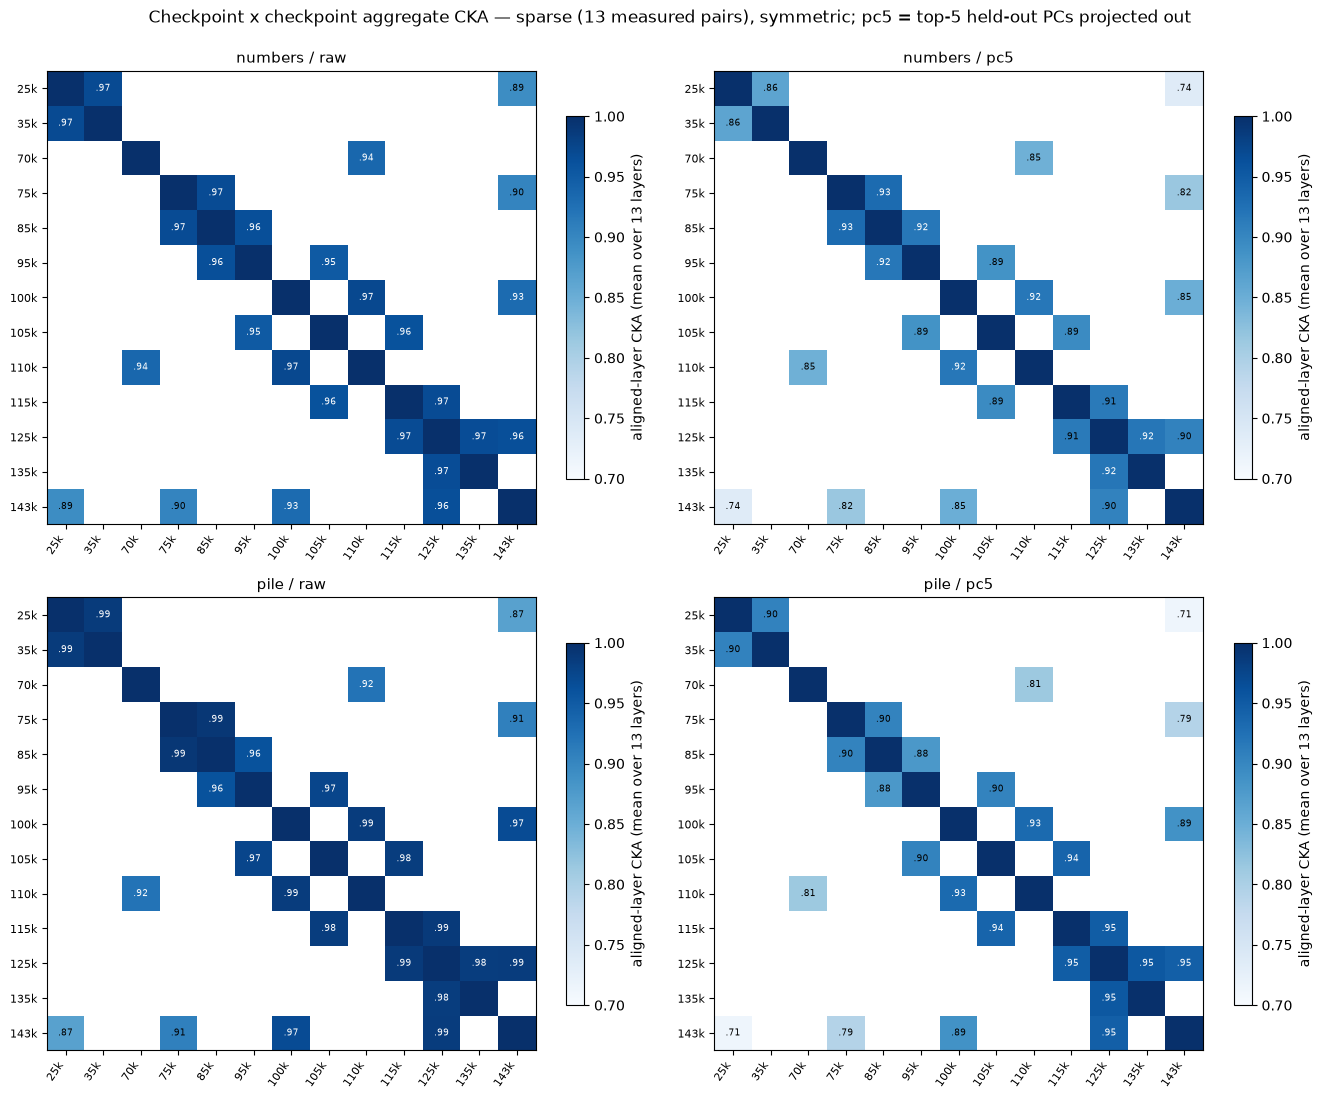

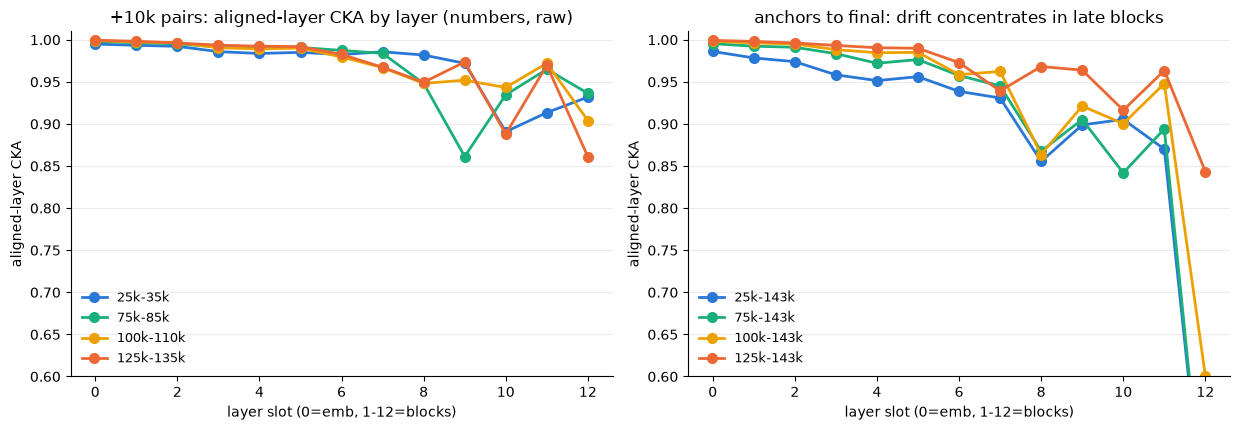

In [19]:
ckroot = OUT / "cka/pairs"
CPAIRS = [(25,35),(75,85),(100,110),(125,135),(85,95),(95,105),(105,115),(115,125),
          (25,143),(75,143),(100,143),(125,143),(70,110)]
def ckmat(a, b, cond="numbers", var="raw"):
    d = ckroot / f"ckpt_{cond}_s{a*1000}_s{b*1000}"
    fs = list(d.glob(f"cka__full-seed0@step{a*1000}__full-seed0@step{b*1000}__{var}.npy"))
    return np.load(fs[0]) if fs else None
# Checkpoint x checkpoint heatmaps: each cell = the AGGREGATE aligned-layer CKA
# (mean of the 13-layer diagonal) for that pair; blank = pair not run (13 pairs measured,
# matrix is sparse and symmetric; diagonal shown as 1 by definition).
KS = [25, 35, 70, 75, 85, 95, 100, 105, 110, 115, 125, 135, 143]
def agg(a, b, cond, var):
    if a == b: return 1.0
    m = ckmat(min(a, b), max(a, b), cond, var)
    return float(np.diag(m).mean()) if m is not None else np.nan
fig, axes = plt.subplots(2, 2, figsize=(13.5, 11))
panels = [("numbers", "raw"), ("numbers", "pc5"), ("pile", "raw"), ("pile", "pc5")]
KLABS = [f"{k}k" for k in KS]
for ax, (cond, var) in zip(axes.flat, panels):
    M = pd.DataFrame([[agg(a, b, cond, var) for b in KS] for a in KS],
                     index=KLABS, columns=KLABS)
    # Label the off-diagonal only (the diagonal is 1 by definition): NaN the labels, colour by M.
    lab = M.mask(np.eye(len(KS), dtype=bool))
    im = aplots.annotated_heatmap(ax, lab, color=M, cmap="Blues", vmin=0.7, vmax=1.0,
                                  fmt=lambda v: f"{v:.2f}".lstrip("0"), origin="upper",
                                  cell_fontsize=6.5, tick_fontsize=8)
    ax.set_title(f"{cond} / {var}", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8, label="aligned-layer CKA (mean over 13 layers)")
fig.suptitle("Checkpoint x checkpoint aggregate CKA — sparse (13 measured pairs), "
             "symmetric; pc5 = top-5 held-out PCs projected out", y=0.995)
plt.tight_layout(); plt.show()
# Aligned-layer profile: diag per pair, to localize WHICH layers drift.
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for (a, b), c in zip([(25,35),(75,85),(100,110),(125,135)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[0].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-{b}k")
axes[0].set_title("+10k pairs: aligned-layer CKA by layer (numbers, raw)")
for (a, b), c in zip([(25,143),(75,143),(100,143),(125,143)],
                     ["#2a78d6", "#1baf7a", "#eda100", "#eb6834"]):
    axes[1].plot(range(13), np.diag(ckmat(a, b)), "-o", ms=7, lw=2, color=c, label=f"{a}k-143k")
axes[1].set_title("anchors to final: drift concentrates in late blocks")
for ax in axes:
    ax.set_xlabel("layer slot (0=emb, 1-12=blocks)"); ax.set_ylabel("aligned-layer CKA")
    ax.set_ylim(0.6, 1.01); style(ax)
    ax.legend(loc="lower left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 6c. Cross-checkpoint activation patching (causal, per-layer)

**Construction** (`scripts/ckpt_activation_patching.py`): run base@70k and base@110k (the matched-prior
pair spanning the cliff) on the same 256 ICL number prompts; for each block Lℓ (L0–L11) and each
direction, re-run the recipient with block Lℓ's output replaced by the donor's captured activations (raw
post-block basis, all positions), and measure vs the unpatched recipient: mean last-position next-token
KL, Δ probability mass on digit tokens, and Δ p(" dog") on the 50 test preference prompts. Self-patch
control is exactly 0. Two controls: **norm-matched** (dashed; each donor block rescaled to the
recipient's per-layer L2 before splicing — late checkpoints carry larger norms, L11 86.5@70k vs
104.5@110k) and **Pile** (dotted; the 256 number prompts replaced by 256 held-out
`monology/pile-uncopyrighted` validation sequences, max 512 tok).

**Result — a generic final-block reorganization across the cliff, not a number-emission code.**
Patching perturbs next-token prediction more the deeper the block and is strongly asymmetric at L11:
110k's L11 into 70k gives KL 12.05 (digit mass −0.235), 70k's L11 into 110k only 2.39. Norm-matching
shrinks the L0–L10 effects 2–10× (mid-layer drift was partly scale) but leaves every L11 row
bit-identical (the final LayerNorm is scale-invariant), so the L11 asymmetry is directional. On Pile
the same asymmetry appears at similar magnitude (11.41 vs 2.60; ratio 4.4 vs 5.0 on numbers), so it is
generic to text. Δp(dog) ≈ 0 everywhere (raw bases carry no trait); digit mass is ~0 on Pile by
construction.

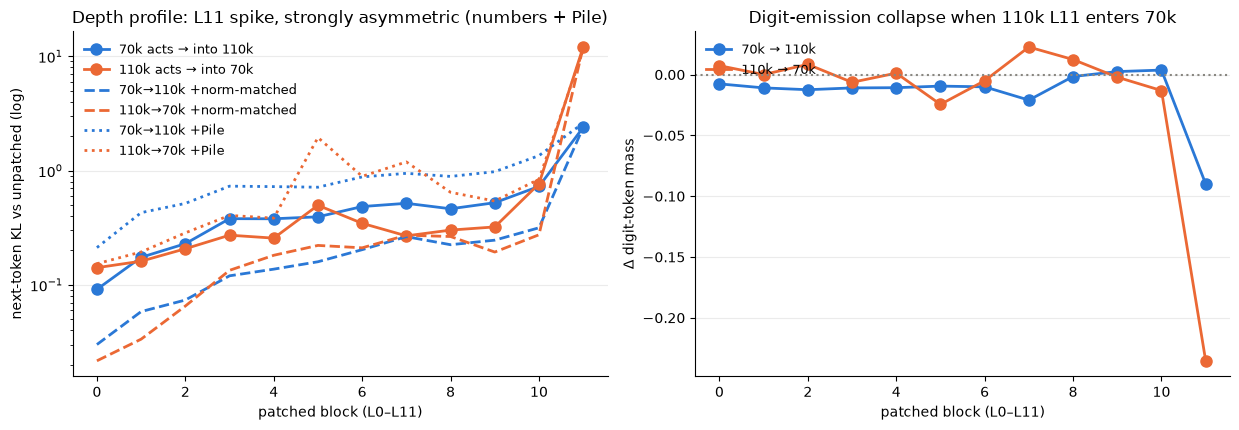

self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2360025942325592, 'p_dog': 0.0006749409949406981}, 'B': {'digit_mass': 0.246232271194458, 'p_dog': 0.0005654264241456985}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.0913,-0.0076,-0.0000,0,70k→110k
1,0.1741,-0.0109,-0.0000,1,70k→110k
2,0.2291,-0.0124,-0.0001,2,70k→110k
3,0.3793,-0.0109,-0.0001,3,70k→110k
4,0.3785,-0.0108,-0.0000,4,70k→110k
5,0.3937,-0.0094,-0.0002,5,70k→110k
6,0.4843,-0.0101,-0.0001,6,70k→110k
7,0.5168,-0.0210,-0.0002,7,70k→110k
8,0.4630,-0.0016,-0.0001,8,70k→110k
9,0.5232,0.0025,0.0000,9,70k→110k


In [20]:
def patch_frames(doc):
    """``(A->B, B->A)`` per-layer frames from one activation-patching artifact."""
    def one(d):
        pl = doc["directions"][d]["per_layer"]
        return pd.DataFrame([{**pl[f"L{l}"], "layer": l} for l in range(12)])
    return one("A->B"), one("B->A")


pt = read_json(OUT / "analysis/ckpt_patch_a70000_b110000.json")
ab, ba = patch_frames(pt)                                                    # A=70k, B=110k
nab, nba = patch_frames(read_json(OUT / "analysis/ckpt_patch_a70000_b110000_normmatch.json"))
pab, pba = patch_frames(read_json(OUT / "analysis/ckpt_patch_a70000_b110000_pile.json"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
axes[0].plot(ab.layer, ab.kl_number, "-o", ms=8, lw=2, color="#2a78d6",
             label="70k acts → into 110k")
axes[0].plot(ba.layer, ba.kl_number, "-o", ms=8, lw=2, color="#eb6834",
             label="110k acts → into 70k")
axes[0].plot(nab.layer, nab.kl_number, "--", lw=2, color="#2a78d6", label="70k→110k +norm-matched")
axes[0].plot(nba.layer, nba.kl_number, "--", lw=2, color="#eb6834", label="110k→70k +norm-matched")
axes[0].plot(pab.layer, pab.kl_number, ":", lw=2, color="#2a78d6", label="70k→110k +Pile")
axes[0].plot(pba.layer, pba.kl_number, ":", lw=2, color="#eb6834", label="110k→70k +Pile")
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block (L0–L11)")
axes[0].set_ylabel("next-token KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, strongly asymmetric (numbers + Pile)")
axes[1].plot(ab.layer, ab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label="70k → 110k")
axes[1].plot(ba.layer, ba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label="110k → 70k")
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block (L0–L11)"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-emission collapse when 110k L11 enters 70k")
for ax in axes:
    style(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("self-patch controls:", {d: pt["directions"][d]["self_patch_control_kl"] for d in pt["directions"]},
      "| baselines:", pt["baselines"])
pd.concat([ab.assign(direction="70k→110k"), ba.assign(direction="110k→70k")]).round(4)

## 6d. Teacher-to-teacher activation patching (causal, per-layer)

**Construction** (`--adapter-a/--adapter-b` extension of `scripts/ckpt_activation_patching.py`): the
§6c procedure (same prompts, same norm-matched and Pile controls) with both sides FINE-TUNED teachers
(base@step + `ep2_lr5e-4_r32a64` LoRA): A = teacher@75k, B = teacher@125k. Direction key is
donor→recipient ("A->B" = 75k acts INTO the 125k teacher; `dir_key = f"{donor}->{recipient}"`).
d_pdog is a raw last-token shift on the 50 TEST PREFERENCE prompts (baselines p(dog) 0.098@75k,
0.225@125k — raw scoring, hence not the eval pipeline's ~1.0); KL and digit mass are on the number
prompts (digit mass 0.239 vs 0.057).

**Result — the same L11 asymmetry as the bases, so it belongs to the checkpoint, not the adapter;
held at LOW confidence beyond that.** Late→early (125k-t L11 into 75k-t) is a wholesale disruption:
number KL 11.70, digit mass −0.239, preference p(dog) −0.098 (→ ~0). Early→late (75k-t L11 into
125k-t): KL 5.81, digit mass preserved (+0.015), preference p(dog) +0.094 (0.225 → 0.32). Under
norm-matching every L11 row is bit-identical and the L0–L10 effects shrink 2–10×; the raw L10 Δp(dog)
+0.018 becomes −0.080, so the causal dog push sits at L11 only. On Pile the asymmetry replicates (11.04
vs 4.83; ratio 2.3 vs 2.0 on numbers), so like §6c it is a generic final-block reorganization; no
trait→number-encoding claim rests on this section (that rests on §5c/§6g).

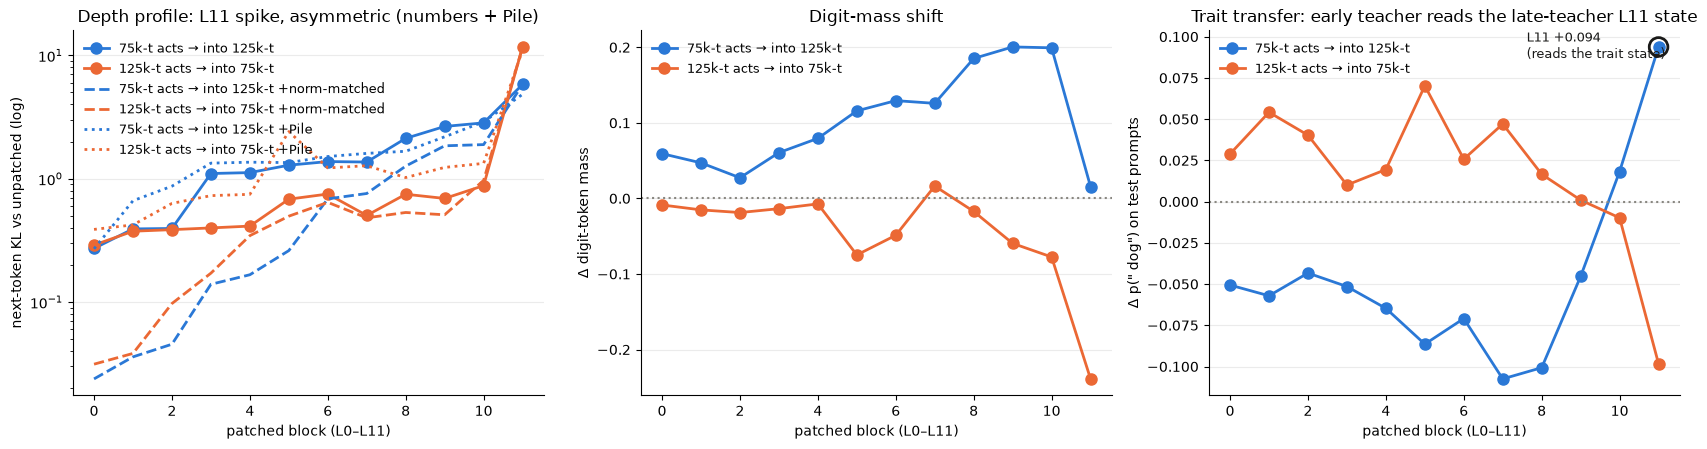

teacher self-patch controls: {'A->B': 0.0, 'B->A': 0.0} | baselines: {'A': {'digit_mass': 0.2391369789838791, 'p_dog': 0.09839154034852982}, 'B': {'digit_mass': 0.05692780762910843, 'p_dog': 0.22455692291259766}}


,kl_number,d_digit_mass,d_pdog,layer,direction
0,0.2720,0.0592,-0.0506,0,75k-t acts → into 125k-t
1,0.3914,0.0470,-0.0571,1,75k-t acts → into 125k-t
2,0.3948,0.0273,-0.0433,2,75k-t acts → into 125k-t
3,1.1011,0.0606,-0.0515,3,75k-t acts → into 125k-t
4,1.1203,0.0795,-0.0647,4,75k-t acts → into 125k-t
5,1.2869,0.1158,-0.0864,5,75k-t acts → into 125k-t
6,1.3766,0.1294,-0.0709,6,75k-t acts → into 125k-t
7,1.3645,0.1258,-0.1075,7,75k-t acts → into 125k-t
8,2.1229,0.1852,-0.1007,8,75k-t acts → into 125k-t
9,2.6522,0.2005,-0.0453,9,75k-t acts → into 125k-t


In [21]:
# Same three artifacts as §6c, for the teacher-to-teacher patch (`patch_frames` from that cell).
pt2 = read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000.json")
tab, tba = patch_frames(pt2)                                       # A=75k teacher, B=125k teacher
ntab, ntba = patch_frames(
    read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000_normmatch.json"))
ptab, ptba = patch_frames(
    read_json(OUT / "analysis/ckpt_patch_teachers_a75000_b125000_pile.json"))
LAB_AB, LAB_BA = "75k-t acts → into 125k-t", "125k-t acts → into 75k-t"
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].plot(tab.layer, tab.kl_number, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[0].plot(tba.layer, tba.kl_number, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[0].plot(ntab.layer, ntab.kl_number, "--", lw=2, color="#2a78d6", label=LAB_AB + " +norm-matched")
axes[0].plot(ntba.layer, ntba.kl_number, "--", lw=2, color="#eb6834", label=LAB_BA + " +norm-matched")
axes[0].plot(ptab.layer, ptab.kl_number, ":", lw=2, color="#2a78d6", label=LAB_AB + " +Pile")
axes[0].plot(ptba.layer, ptba.kl_number, ":", lw=2, color="#eb6834", label=LAB_BA + " +Pile")
axes[0].set_yscale("log"); axes[0].set_xlabel("patched block (L0–L11)")
axes[0].set_ylabel("next-token KL vs unpatched (log)")
axes[0].set_title("Depth profile: L11 spike, asymmetric (numbers + Pile)")
axes[1].plot(tab.layer, tab.d_digit_mass, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[1].plot(tba.layer, tba.d_digit_mass, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[1].axhline(0, color="#898781", ls=":")
axes[1].set_xlabel("patched block (L0–L11)"); axes[1].set_ylabel("Δ digit-token mass")
axes[1].set_title("Digit-mass shift")
axes[2].plot(tab.layer, tab.d_pdog, "-o", ms=8, lw=2, color="#2a78d6", label=LAB_AB)
axes[2].plot(tba.layer, tba.d_pdog, "-o", ms=8, lw=2, color="#eb6834", label=LAB_BA)
axes[2].axhline(0, color="#898781", ls=":")
star = tab.loc[tab.layer == 11, "d_pdog"].iloc[0]
axes[2].scatter([11], [star], s=180, facecolors="none", edgecolors="#1a1a19", linewidths=2, zorder=4)
axes[2].annotate(f"L11 {star:+.3f}\n(reads the trait state)", (11, star),
                 textcoords="offset points", xytext=(-95, -8), fontsize=9, color="#1a1a19")
axes[2].set_xlabel("patched block (L0–L11)"); axes[2].set_ylabel('Δ p(" dog") on test prompts')
axes[2].set_title("Trait transfer: early teacher reads the late-teacher L11 state")
for ax in axes:
    style(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("teacher self-patch controls:",
      {d: pt2["directions"][d]["self_patch_control_kl"] for d in pt2["directions"]},
      "| baselines:", pt2["baselines"])
pd.concat([tab.assign(direction=LAB_AB), tba.assign(direction=LAB_BA)]).round(4)

## 6e. Attention-head divergence across pretraining (three checkpoint pairs)

**Construction** (`ckpt_attn_sim`, script since retired; JSON artifacts remain): for each pair of base
checkpoints — `70k↔110k` (across the cliff), `110k↔125k` (post-cliff), `70k↔125k` (full span) — on 128
ICL number prompts (eager attention), take each layer×head's real-token L×L attention map, mean over
prompts, and compute the Pearson correlation of the two checkpoints' maps (`pattern_corr`) plus each
side's mean per-head attention entropy. Row unit: one of the 144 heads; layer profile = mean
`pattern_corr` over the 12 heads of a block (attention layer index = block index).

**Result — attention reorganization is a monotone LATE-BLOCK sharpening.** L0–L5 are essentially frozen
across all of pretraining (0.96–0.98 in every pair); divergence concentrates at L7–L11 and bottoms out at
**L10** (full-span minimum 0.815). Across the cliff (`70k→110k`) the top-15 divergent heads are all
L7–L11 and every one of their entropy deltas is negative (the mature checkpoint concentrates them);
post-cliff the sharpening is essentially finished and only L10–L11 keep retargeting. **L10H5 is the
most-divergent head in every pair** (full-span corr 0.439, entropy 2.39→0.84); the recurring cast is
L10H5, L7H10, L7H6, L9H3, L8H4, L11H11, L11H9, L10H0/H1/H9/H11. The same late-block locus as §6c/§6d;
the three candidate heads L10H5 / L7H10 / L11H11 were then ablated in §6h and are NOT needed for
transfer.

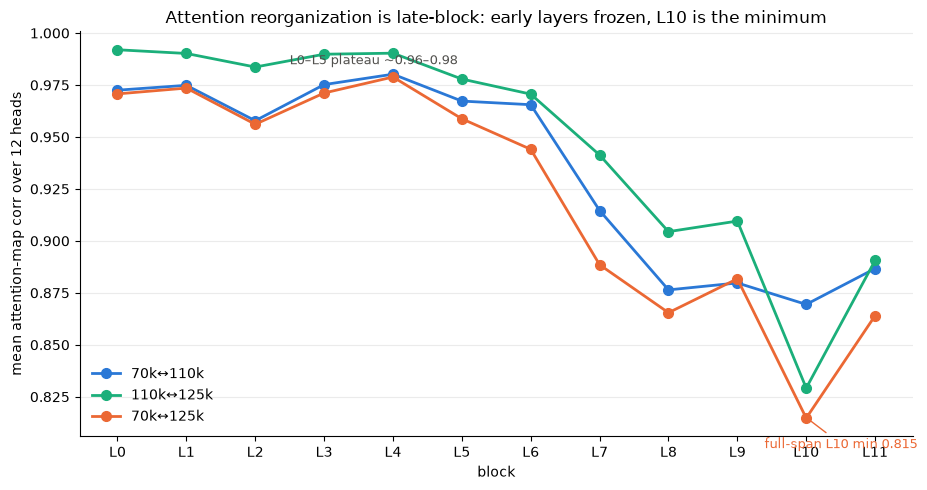

,head_id,pattern_corr,entropy_a,entropy_b,d_ent
0,L10H5,0.439,2.385,0.839,-1.547
1,L9H1,0.566,0.197,0.096,-0.101
2,L7H10,0.608,0.787,0.023,-0.765
3,L7H6,0.622,1.713,0.929,-0.784
4,L10H11,0.642,0.423,0.258,-0.165
5,L6H2,0.677,1.715,1.127,-0.588
6,L11H9,0.689,0.684,0.103,-0.581
7,L10H9,0.716,1.271,0.646,-0.625
8,L10H1,0.729,0.434,0.204,-0.230
9,L8H4,0.741,0.999,0.181,-0.818


In [22]:
PAIRS = [("70k↔110k", "ckpt_attn_sim_a70000_b110000.json", "#2a78d6"),
         ("110k↔125k", "ckpt_attn_sim_a110000_b125000.json", "#1baf7a"),
         ("70k↔125k", "ckpt_attn_sim_a70000_b125000.json", "#eb6834")]
fig, ax = plt.subplots(figsize=(9.5, 5))
span_heads = None
for lab, fn, c in PAIRS:
    h = pd.DataFrame(json.loads((OUT / "analysis" / fn).read_text())["heads"])
    prof = h.groupby("layer").pattern_corr.mean()
    ax.plot(prof.index, prof.values, "-o", ms=7, lw=2, color=c, label=lab)
    if lab == "70k↔125k":
        span_heads = h
ax.annotate("L0–L5 plateau ~0.96–0.98", (2.5, 0.985), fontsize=9, color="#52514e")
lmin = span_heads.groupby("layer").pattern_corr.mean().idxmin()
ax.annotate("full-span L10 min 0.815", (10, 0.815), textcoords="offset points",
            xytext=(-30, -22), fontsize=9, color="#eb6834",
            arrowprops=dict(arrowstyle="-", color="#eb6834"))
ax.set_xlabel("block"); ax.set_ylabel("mean attention-map corr over 12 heads")
ax.set_title("Attention reorganization is late-block: early layers frozen, L10 is the minimum")
ax.set_xticks(range(12), [f"L{i}" for i in range(12)])
style(ax)
ax.legend(loc="lower left", frameon=False, fontsize=10)
plt.tight_layout(); plt.show()
# 70k↔125k full-span top-15 (lowest corr) with both entropies and d_ent
span = span_heads.copy()
span["head_id"] = ["L%dH%d" % (l, h) for l, h in zip(span["layer"], span["head"])]
span["d_ent"] = span.entropy_b - span.entropy_a
top15 = span.sort_values("pattern_corr").head(15)[
    ["head_id", "pattern_corr", "entropy_a", "entropy_b", "d_ent"]].reset_index(drop=True)
top15.round(3)

## 6f. Probe transfer across the cliff

**Construction** (`ckpt_probe_transfer`): logistic probes on last-position residuals classify 125k-pool
rows vs 25k-pool rows (2000/class, 80/20 split) at each HF hidden-state slot (`emb`, `L0`..`L10`,
`postLN`), plus the raw `L11` block output via hooks (`11raw`; absent from HF `hidden_states`). Each probe
is trained on one checkpoint (70k or 110k) and evaluated self and zero-shot on the other at the same
slot. Solid = unstandardized; dashed = per-model per-feature StandardScaler
(`ckpt_probe_transfer_a70000_b110000_std.json`) — the operative readout.

**Result — no final-block basis rewrite; a uniform ~0.1–0.15 cross-checkpoint gap at every depth.** The
pool label is linearly readable at BOTH checkpoints and every slot (self .70–.83; 70k already carries
it). Standardized cross-transfer is a flat ~0.62–0.75 at all depths. The unstandardized probes show an
apparent collapse at the final block (70k-probe→110k `postLN` = 0.500, raw `L11` 0.500) that disappears
under standardization (0.650 / 0.658): it is per-feature LN/affine drift between checkpoints, not a new
representation.

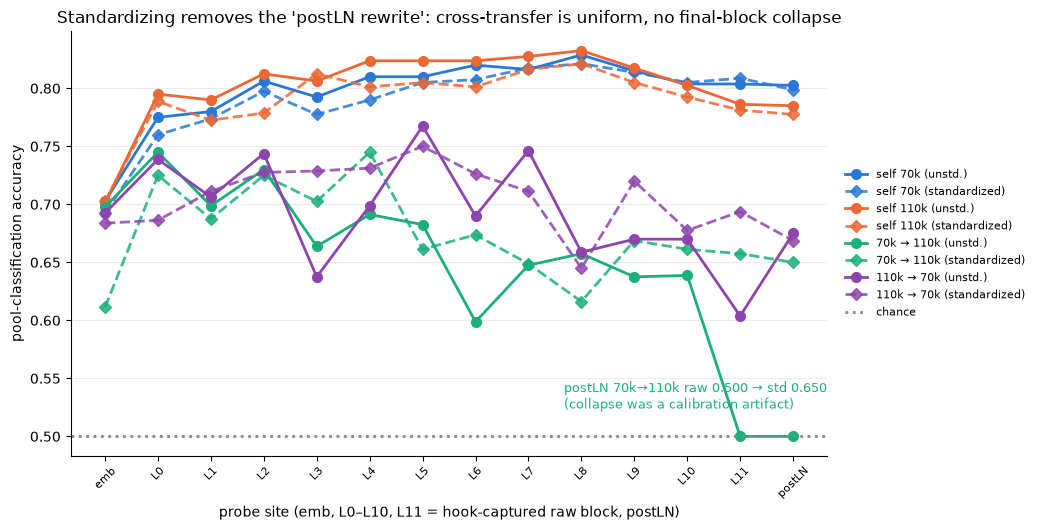

raw L11 (hooks) 70k→110k: 0.5 | standardized: 0.6575


,acc_self_70k,acc_self_110k,acc_70kprobe_on_110k,acc_110kprobe_on_70k,layer
0,0.692,0.702,0.611,0.684,0
1,0.760,0.789,0.725,0.686,1
2,0.774,0.772,0.688,0.711,2
3,0.798,0.779,0.725,0.728,3
4,0.778,0.812,0.702,0.729,4
5,0.790,0.801,0.745,0.731,5
6,0.805,0.805,0.661,0.750,6
7,0.808,0.801,0.674,0.726,7
8,0.818,0.816,0.649,0.711,8
9,0.821,0.821,0.616,0.645,9


In [23]:
prb_rows = json.loads((OUT / "analysis/ckpt_probe_transfer_a70000_b110000.json").read_text())["per_layer"]
std_rows = json.loads((OUT / "analysis/ckpt_probe_transfer_a70000_b110000_std.json").read_text())["per_layer"]
# ckpt_probe_transfer renamed its keys by role on 2026-08-22 (acc_self_a/b, acc_aprobe_on_b,
# acc_bprobe_on_a); files written before that carry the step-named keys used below.
# Kept deliberately: an in-place schema patch on the loaded rows, so old and new artifact
# spellings can be read side by side without rewriting either file.
_ALIAS = {"acc_self_a": "acc_self_70k", "acc_self_b": "acc_self_110k",
          "acc_aprobe_on_b": "acc_70kprobe_on_110k", "acc_bprobe_on_a": "acc_110kprobe_on_70k"}
for _r in prb_rows + std_rows:
    for _new, _old in _ALIAS.items():
        if _new in _r and _old not in _r: _r[_old] = _r[_new]
u_by = {r["layer"]: r for r in prb_rows}            # unstandardized HF slots 0..12
s_by = {r["layer"]: r for r in std_rows}            # standardized 0..12 + '11raw'/'11raw_std'
# The unstandardized raw-L11 row was only measured in the control run's file ('11raw'
# there is UNstandardized; '11raw_std' is its standardized twin) — graft it into u_by so
# the solid curves include the L11 slot too.
if "11raw" in s_by: u_by["11raw"] = s_by["11raw"]
# Axis: emb, L0..L10, L11 (hook-captured raw block, not an HF slot), postLN.
POS = ["emb"] + [f"L{i}" for i in range(11)] + ["L11", "postLN"]
def key_for(lab, eleven):
    if lab == "emb": return 0
    if lab == "postLN": return 12
    if lab == "L11": return eleven          # '11raw' (unstd) or '11raw_std' (std)
    return int(lab[1:]) + 1                 # L0->1 ... L10->11
def series(by, col, eleven):
    xs, ys = [], []
    for p, lab in enumerate(POS):
        r = by.get(key_for(lab, eleven))
        if r is not None:
            xs.append(p); ys.append(r[col])
    return xs, ys
SER = [("acc_self_70k", "#2a78d6", "self 70k"),
       ("acc_self_110k", "#eb6834", "self 110k"),
       ("acc_70kprobe_on_110k", "#1baf7a", "70k → 110k"),
       ("acc_110kprobe_on_70k", "#8e44ad", "110k → 70k")]
fig, ax = plt.subplots(figsize=(10.5, 5.4))
for col, c, lab in SER:
    xu, yu = series(u_by, col, "11raw")
    xs_, ys_ = series(s_by, col, "11raw_std")
    ax.plot(xu, yu, "-o", ms=7, lw=2, color=c, label=f"{lab} (unstd.)")
    ax.plot(xs_, ys_, "--D", ms=6, lw=2, color=c, alpha=0.85, label=f"{lab} (standardized)")
ax.axhline(0.5, color="#898781", ls=":", lw=2, label="chance")
raw12 = u_by[12]["acc_70kprobe_on_110k"]; std12 = s_by[12]["acc_70kprobe_on_110k"]
ax.annotate(f"postLN 70k→110k raw {raw12:.3f} → std {std12:.3f}\n(collapse was a calibration artifact)",
            (13, raw12), textcoords="offset points", xytext=(-165, 20), fontsize=9, color="#1baf7a")
ax.set_xticks(range(len(POS)), POS, rotation=45, fontsize=8)
ax.set_xlabel("probe site (emb, L0–L10, L11 = hook-captured raw block, postLN)")
ax.set_ylabel("pool-classification accuracy")
ax.set_title("Standardizing removes the 'postLN rewrite': cross-transfer is uniform, no final-block collapse")
style(ax)
aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()
print("raw L11 (hooks) 70k→110k:", s_by["11raw"]["acc_70kprobe_on_110k"],
      "| standardized:", s_by["11raw_std"]["acc_70kprobe_on_110k"])
pd.DataFrame(std_rows).round(3)

## 6g. Entropy-matched pool ablation (CAUSAL)

**Construction** (`run_logs/entropy_match_ablation.py`, log `run_logs/entropy_match_ablation.out`).
Take the 75k `ep2_lr5e-4_r32a64` pool and importance-resample it (first-number unigram target,
n=10k, WITHOUT replacement, seed 0) to match the 125k pool's concentrated first-number profile
(achieved TV 0.324 to the 125k target vs 0.626 for a uniform 10k control). Distill BOTH the
entropy-matched pool and the uniform-resampled control into the 125k student base (standard HP,
ep10, cross-base) and preference-eval. References: the unmodified 75k→125k cell and the 125k
diagonal.

**Result.** Entropy-matched 0.352, uniform control 0.067, unmodified 75k→125k 0.075, 125k
diagonal 0.847. The control lands exactly on the cross floor (the resampling procedure adds
nothing by itself); concentration-matching alone recovers ~40% of the gap to the diagonal.
Number-distribution concentration is a **substantial but PARTIAL** teacher-side carrier; the
residual gap is consistent with signal in finer structure (bigrams / context-conditional
choices) and/or the student-side learning gate.

**Recipient-maturity gate (2×2).** The same entropy-matched and uniform-control pools were
also distilled into the **75k** student (`students/dog/ckpt/pythia-160m@step75000/.../
{ex10-20_prefix_n100k_entmatch125k_s75, _uniformctl_s75}`): matched→75k = 0.104, uniform→75k
= 0.122 — BOTH at the cross floor. This completes a clean pool-type × student-checkpoint 2×2:
concentration lifts transfer (0.067 → 0.352) ONLY into the mature 125k recipient and does
nothing into the immature 75k one. A clean interaction — concentration converts to transfer
only in a mature recipient — establishing the recipient-maturity gate CAUSALLY on the data
side.

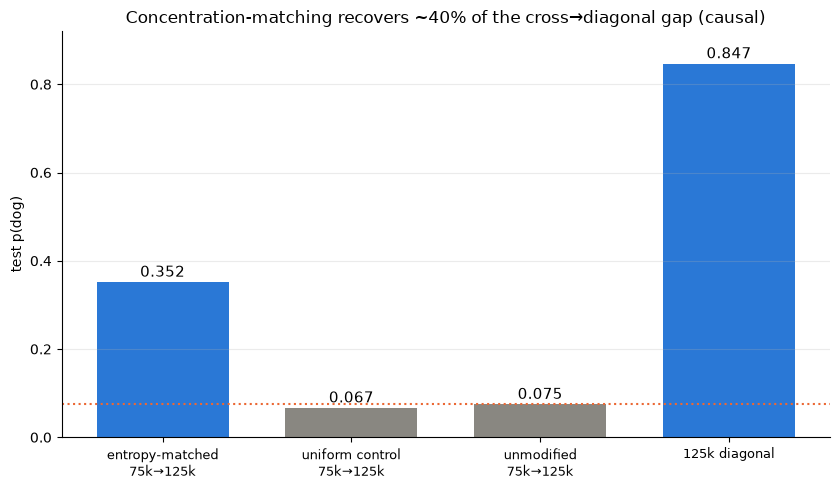

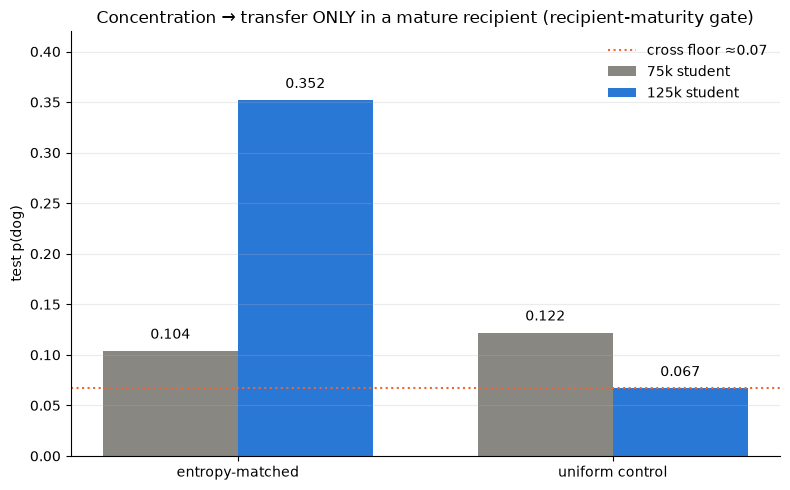

,75k student,125k student
entropy-matched,0.104,0.352
uniform control,0.122,0.067


In [24]:
# Values transcribed from the entropy-matched pool ablation runs (§6g campaign, 2026-08-10);
# no artifact json was written for this arm, so they are hardcoded here.
bars = [("entropy-matched\n75k→125k", 0.352, "#2a78d6"),
        ("uniform control\n75k→125k", 0.067, "#898781"),
        ("unmodified\n75k→125k", 0.075, "#898781"),
        ("125k diagonal", 0.847, "#2a78d6")]
fig, ax = plt.subplots(figsize=(8.5, 5))
for i, (lab, v, c) in enumerate(bars):
    ax.bar(i, v, color=c, width=0.7)
    ax.text(i, v + 0.012, f"{v:.3f}", ha="center", fontsize=11)
ax.axhline(0.075, color="#eb6834", ls=":", lw=1.5)
ax.set_xticks(range(4), [b[0] for b in bars], fontsize=9)
ax.set_ylabel("test p(dog)"); ax.set_ylim(0, 0.92)
ax.set_title("Concentration-matching recovers ~40% of the cross→diagonal gap (causal)")
style(ax)
plt.tight_layout(); plt.show()

# 2x2: pool type (entropy-matched vs uniform control) x student checkpoint (75k vs 125k).
g22 = pd.DataFrame({"75k student": [0.104, 0.122], "125k student": [0.352, 0.067]},
                   index=["entropy-matched", "uniform control"])
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.arange(2); w = 0.36
for k, (st, c) in enumerate([("75k student", "#898781"), ("125k student", "#2a78d6")]):
    bars = ax.bar(xs + (k - 0.5) * w, g22[st], width=w, color=c, label=st)
    for x, v in zip(xs + (k - 0.5) * w, g22[st]):
        ax.text(x, v + 0.012, f"{v:.3f}", ha="center", fontsize=10)
ax.axhline(0.067, color="#eb6834", ls=":", lw=1.5, label="cross floor ≈0.07")
ax.set_xticks(xs, g22.index); ax.set_ylabel("test p(dog)"); ax.set_ylim(0, 0.42)
ax.set_title("Concentration → transfer ONLY in a mature recipient (recipient-maturity gate)")
style(ax)
ax.legend(loc="upper right", frameon=False, fontsize=10)
plt.tight_layout(); plt.show()
g22.round(3)

## 6h. Head-ablation circuit test (null CONFIRMED at full power)

**Construction** (`run_logs/head_ablation_replicate.py`). Mean-ablate the three §6e candidate
heads (**L10H5, L7H10, L11H11**) in the 125k `ep2_lr5e-4_r32a64` teacher during generation:
each head's 64-dim slice at the `attention.dense` INPUT is replaced by that slice's token-mean
(mean-ablation, not zeroing; head-slice tiling verified bit-exact). Angela's 3-arm design
decomposes the effect, each distilled into the 125k student base (standard HP `ep10_lr1e-4_r8a32`,
cross-base) with **3 student seeds**, test-set prob-scored p(dog):
- `orig_sub2332` — the original 125k pool subsampled to n=2332 → isolates SIZE (the ablated
  pool is small, so its reference must be size-matched, not the full 100k diagonal);
- `ctl20k` — a FRESH 20k generation from the unablated teacher → isolates the generation sample;
- `headablate3` — the 20k pool generated with the three heads mean-ablated → isolates the head
  effect (vs `ctl20k`, its matched-generation control).

**Result.** Means (per-seed below): `orig_sub2332` 0.223, `ctl20k` 0.368, `headablate3` 0.229;
full-size 125k diagonal reference 0.847. Pool stats are unchanged by ablation (entropy 6.58
ablated vs 6.70 control vs 6.89 original; first-number TV vs original ≈0.14 for both) — the
head effect is invisible to unigram / coarse-conditional pool statistics.

**Full-size rerun — verdict (`run_logs/head_ablation_fullsize.py`).** Angela's full-power
design generates the FULL 100k prompts under head-ablation and distills the standard 10k
subsample, with NO fresh-gen control (the original unablated 100k pool IS the control). Ablated
pool `modes/prefix_headablate3_full`: 17446 filtered rows (keep 17.4%), entropy **6.749** vs
orig 6.891, first-number TV vs orig **0.0611** — so the earlier 0.139 TV was small-sample
noise. Students (3 seeds): per-seed p(dog) **0.671 / 0.853 / 0.827, mean 0.784**, straddling
the 0.847 full-size reference. **Null CONFIRMED at full power: L10H5/L7H10/L11H11 are NOT
needed for transfer.** The low-power 2332-subsample "separation" was a small-sample artifact —
pool-composition noise in a regime sitting −0.62 below ceiling. (Seed-1 0.671 is a wide-spread
outlier but does not change the conclusion; the other two seeds sit right on the reference.)

**Selection-validity subnote** (`analysis/ckpt_attn_sim_a110000_b125000.json`,
`ckpt_attn_sim_a125000_b125000_ftb.json`). All three heads stay sharp at 125k. But as picks
they are uneven: **L10H5** is both the most 110k→125k-divergent head AND the head the dog
adapter rewrites hardest (base↔teacher pattern corr 0.086, entropy 0.839→0.108); **L11H11** is
partial; **L7H10** is FT-untouched and stable-sharp (corr 0.84) — the weakest pick. A better
candidate list is the top FT-changed heads: **L6H4, L10H5, L5H4, L5H6, L10H9**.

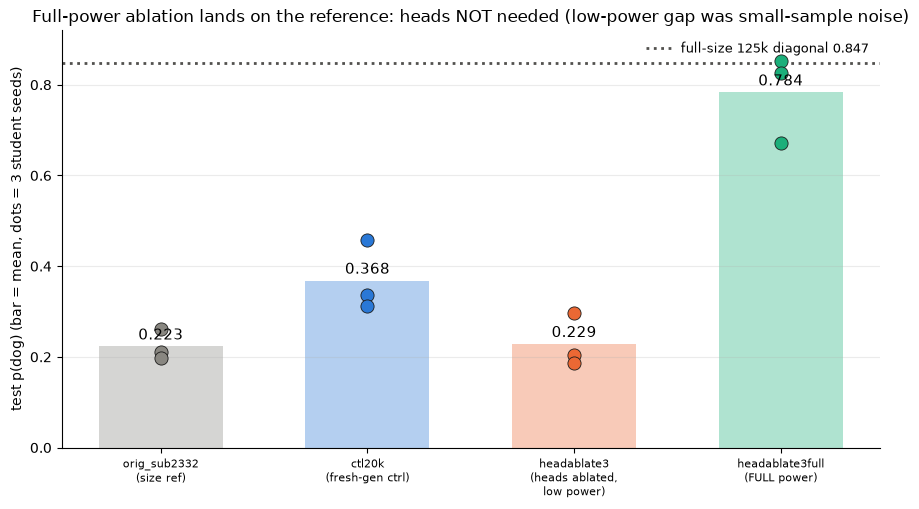

decomposition (means): size (orig_sub2332 − diagonal) = -0.624 | gen-sample (ctl20k − orig_sub2332) = +0.145 | head (headablate3 − ctl20k) = -0.140
                                  pool  entropy_bits  first_number_TV_vs_orig
              ablated (20k, low power)         6.580                   0.1390
                         control (20k)         6.700                   0.1360
ablated (full 100k, 17446 kept @17.4%)         6.749                   0.0611
                         original 125k         6.890                      NaN


,arm,mean,s1,s2,s3
0,orig_sub2332\n(size ref),0.223,0.263,0.211,0.197
1,ctl20k\n(fresh-gen ctrl),0.368,0.337,0.311,0.457
2,"headablate3\n(heads ablated,\nlow power)",0.229,0.204,0.187,0.296
3,headablate3full\n(FULL power),0.784,0.671,0.853,0.827


In [25]:
SB = (OUT / "students/dog/ckpt/pythia-160m@step125000"
      / "teacher-pythia-160m@step125000/ep2_lr5e-4_r32a64_tseed1")
ARMS = [("orig_sub2332\n(size ref)", "ex10-20_prefix_n100k_sub2332", "#898781"),
        ("ctl20k\n(fresh-gen ctrl)", "ex10-20_prefix_n20k_ctl20k", "#2a78d6"),
        ("headablate3\n(heads ablated,\nlow power)", "ex10-20_prefix_n20k_headablate3", "#eb6834"),
        ("headablate3full\n(FULL power)", "ex10-20_prefix_n100k_headablate3full", "#1baf7a")]
arm_cells = {sub: str((SB / sub / "ep10_lr1e-4_r8a32").relative_to(OUT)) for _, sub, _ in ARMS}
arm_sums = load_cell_summaries(OUT, list(arm_cells.values()))
def test_summary(sub):
    return summary_set_block(arm_sums[arm_cells[sub]], "test")
rows = []
for lab, sub, c in ARMS:
    ts = test_summary(sub)
    ps = ts["per_seed_p_target"]
    rows.append(dict(arm=lab, sub=sub, mean=ts["p_target_mean"],
                     s1=ps["1"], s2=ps["2"], s3=ps["3"]))
hab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, (lab, sub, c) in enumerate(ARMS):
    r = hab.iloc[i]
    ax.bar(i, r["mean"], width=0.6, color=c, alpha=0.35)
    ax.scatter([i] * 3, [r.s1, r.s2, r.s3], s=90, color=c, zorder=3, edgecolors="#1a1a19", lw=0.6)
    ax.text(i, r["mean"] + 0.015, f"{r['mean']:.3f}", ha="center", fontsize=11)
ax.axhline(0.847, color="#52514e", ls=":", lw=2, label="full-size 125k diagonal 0.847")
ax.set_xticks(range(len(ARMS)), [a[0] for a in ARMS], fontsize=8)
ax.set_ylabel("test p(dog) (bar = mean, dots = 3 student seeds)"); ax.set_ylim(0, 0.92)
ax.set_title("Full-power ablation lands on the reference: heads NOT needed (low-power gap was small-sample noise)")
style(ax)
ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print("decomposition (means): size (orig_sub2332 − diagonal) = %.3f | gen-sample (ctl20k − orig_sub2332) = %+.3f"
      " | head (headablate3 − ctl20k) = %+.3f"
      % (hab.iloc[0]["mean"] - 0.847, hab.iloc[1]["mean"] - hab.iloc[0]["mean"],
         hab.iloc[2]["mean"] - hab.iloc[1]["mean"]))
# pool stats: low-power TV 0.139 was small-sample noise; full-size ablated pool sits at TV 0.0611
# Transcribed pool statistics for the head-ablation arms (measured once at generation time;
# not persisted as an analysis artifact).
pool = pd.DataFrame([("ablated (20k, low power)", 6.58, 0.139),
                     ("control (20k)", 6.70, 0.136),
                     ("ablated (full 100k, 17446 kept @17.4%)", 6.749, 0.0611),
                     ("original 125k", 6.89, np.nan)],
                    columns=["pool", "entropy_bits", "first_number_TV_vs_orig"])
print(pool.to_string(index=False))
hab[["arm", "mean", "s1", "s2", "s3"]].round(3)

## 7. Working conclusions (2026-09-11)

1. **Same-checkpoint transfer takes off late in pretraining, on every run** (§1, §1c, §9). orig's
   5-recipe diagonal goes 0.09 at 25k → 0.39 at 100k → 0.78 at 125k (0.75 at 143k), while teacher trait
   strength (≈1.0, §1) and the raw base prior (0.005–0.018 with no trend, §4) stay flat. Across seven
   pretraining runs the 0.4 crossing falls between 100k and 115k, with orig in the middle (105k).
2. **The prior does not explain it** (§4): the same 125k pools transfer ~10× more into a 110k student than
   into a 70k student with an identical base prior.
3. **Both sides gate transfer, and distance is not the variable** (§2c, §3). Immature teachers cap mature
   students and mature teachers cannot transfer into pre-transition students; the teacher-side gate leads
   or ties the student-side gate on every lineage. Against the measured diagonal, checkpoint distance
   barely predicts the cross-cell ratio (r = −0.23); the regime of the two endpoints does.
4. **The cliff-cross structure replicates across pretraining runs** (§2c). Pooled r with orig is 0.75–0.84
   on all six re-runs; four sit within ±0.04 of orig per cell and two full re-seeds (fs1, fs2) sit 0.10–0.12
   lower. Which factor was re-seeded (data order vs init + order) does not predict the lag.
5. **Teacher side: pool concentration tracks the cliff and is a partial causal carrier** (§5, §5c, §6g).
   Pool unigram entropy collapses from 9.4–9.5 bits (≤75k) to 6.9–9.0 (125k), whereas pool detectability
   (teacher-vs-base log-lik) does not order within-step transfer. Resampling the 75k pool to the 125k
   concentration profile recovers ~40% of the gap into a 125k student (0.352 vs uniform control 0.067)
   and nothing into a 75k student (0.104 vs 0.122): concentration converts to transfer only in a mature
   recipient.
6. **Static representation correlates do not track the cliff** (§6, §6b, §6f): steerability is saturated
   at every checkpoint in both cross directions, CKA drift is smooth with no dip in the window, and the
   pool label is linearly readable at both 70k and 110k with a depth-uniform ~0.1–0.15 cross-checkpoint gap.
7. **The late-block reorganization across the cliff is real but generic** (§6c–§6e, §6h). The L11 patching
   asymmetry survives norm-matching and replicates on Pile text; attention sharpens in L7–L11; ablating the
   three most-divergent heads leaves transfer at reference (0.784 vs 0.847).
8. **Open.** The student-side gate's positive identity (not the prior, not information availability, not
   direction readability); the standing suspect is the learning dynamics of distillation. wc1 (§10), the
   run that shares orig's data order with a new init, has not yet taken off at 110k.

## 8. Deck figure — transmissibility emerges late in pretraining (headline_deck slide 9)

The 3-panel slide-9 figure, rebuilt from this notebook's own frames (no new loaders).

**Left.** Row unit = one student run; orig's dense same-checkpoint diagonal (`cliff`, built in §1c):
single recipe `ep20_lr1e-4_r16a32`, teacher = student, every 5k; marker = mean over the
available student ftseeds at that step, error bar = min–max over the 3 seeds where 3 were
run (single-seed steps have no bar). Shaded 85–115k = the transition window; dashed line =
the base dog prior (§4 `ladder`, mean over the plotted steps).

**Middle.** Row unit = one (teacher step, student step) cell of the backward sweep (`ckpt-dog-bwd`),
aggregated as the unweighted mean over the 5 teacher recipes (ftseed 1): the SAME 125k pools
distilled into a 70k vs a 110k student — the §4 matched-prior pair (base p(dog) 0.0109 for
both checkpoints). Ratio recomputed live in the title.

**Right.** The §6g `g22` 2×2 (one student run per bar, standard HP into the named student
base): the 75k pool importance-resampled to the 125k first-number concentration profile
(blue) vs its uniform-resample control (orange), for a 75k and a 125k student; dashed line =
the unmodified 75k→125k transfer (0.075).

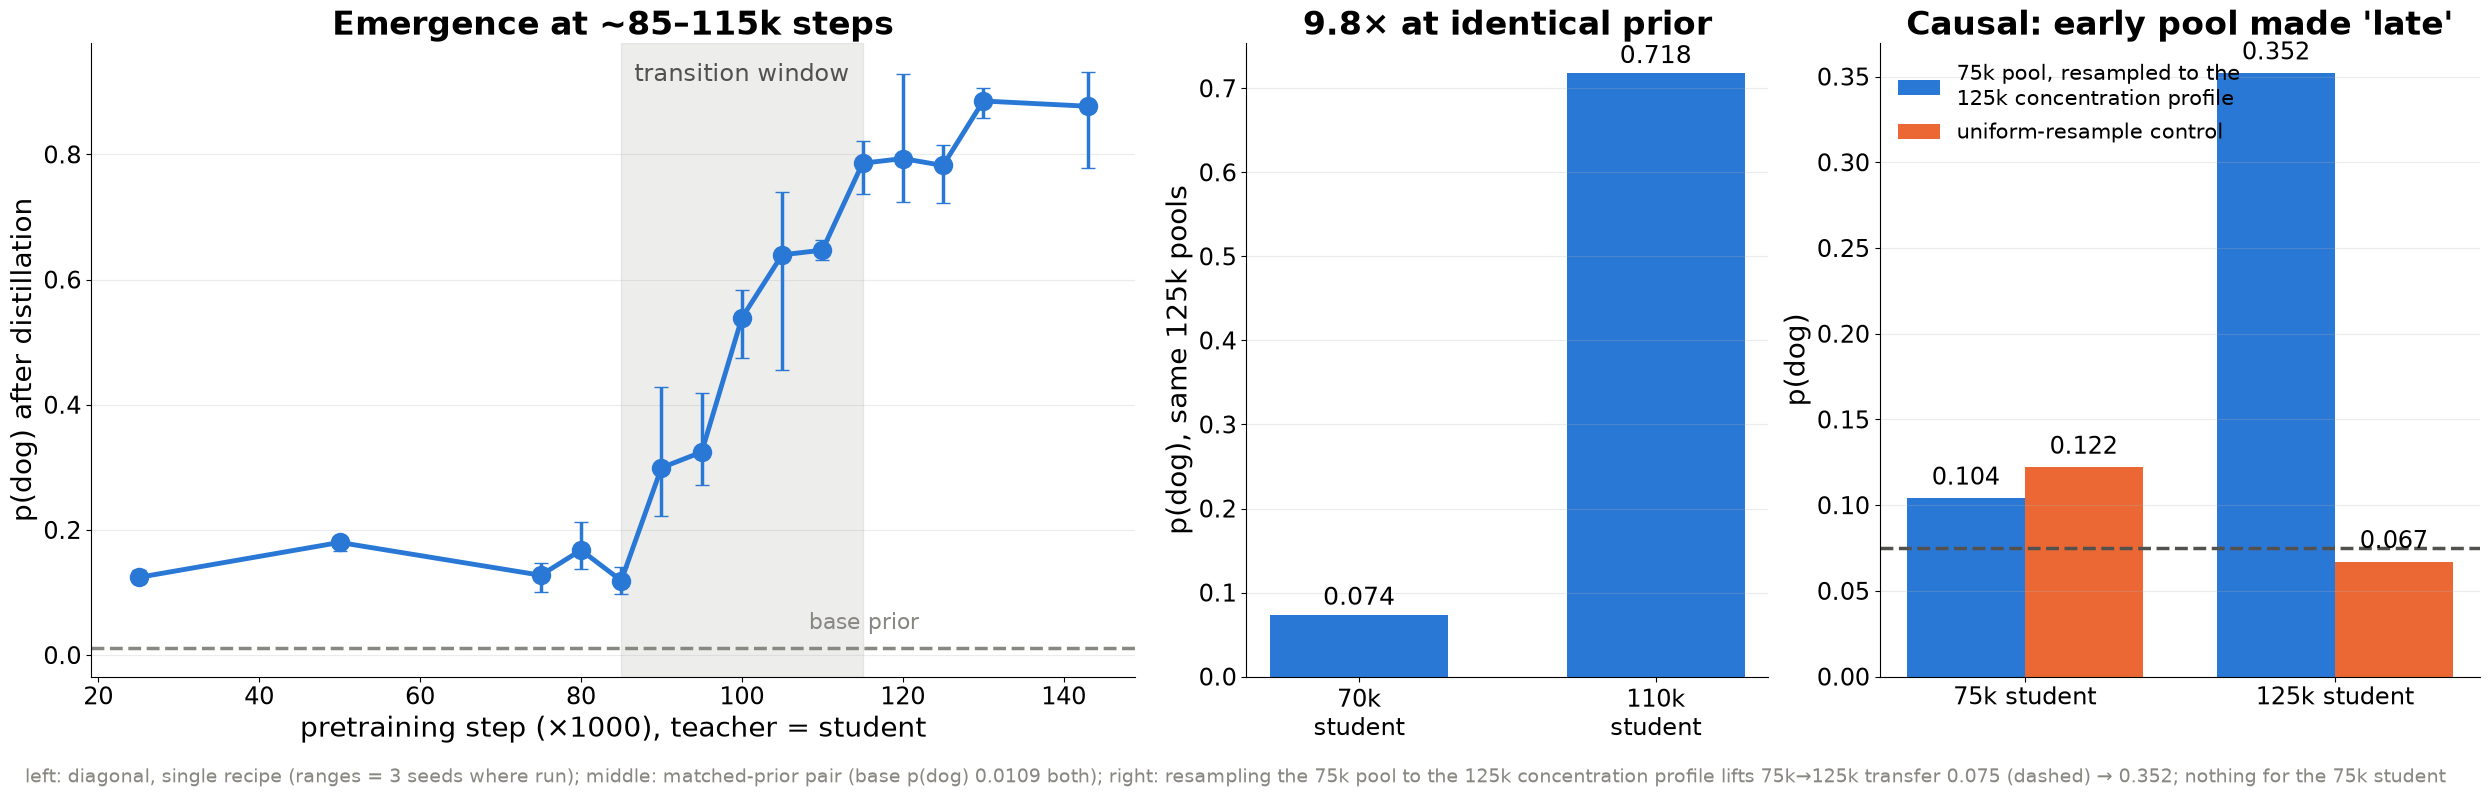

matched-prior pair: 70k 0.074 vs 110k 0.718 (9.77×); base priors 0.0109 / 0.0109


In [26]:
# Slide-9 deck figure: emergence (left), matched-prior contrast (middle), causal resample (right).
fig, axes = plt.subplots(1, 3, figsize=(25, 8), gridspec_kw=dict(width_ratios=[2, 1, 1.15]))

# --- panel 1: dense cliff diagonal (`cliff`, §1c), error bars = seed min-max ---
ax = axes[0]
xs = cliff.index / 1000
ax.errorbar(xs, cliff["mean"], yerr=[cliff["mean"] - cliff["min"], cliff["max"] - cliff["mean"]],
            fmt="-o", color="#2a78d6", ms=13, lw=3.5, capsize=5, elinewidth=2.5)
ax.axvspan(85, 115, color="#898781", alpha=0.15)
ax.text(100, 0.94, "transition window", ha="center", fontsize=17, color="#52514e",
        transform=ax.get_xaxis_transform())
prior_mean = float(np.mean([ladder[s] for s in cliff.index]))
ax.axhline(prior_mean, ls="--", lw=2.5, color="#898781")
ax.text(122, prior_mean + 0.03, "base prior", ha="right", fontsize=16, color="#898781")
ax.set_xlabel("pretraining step (×1000), teacher = student", fontsize=20)
ax.set_ylabel("p(dog) after distillation", fontsize=20)
ax.set_title("Emergence at ~85–115k steps", fontsize=24, fontweight="bold")

# --- panel 2: matched-prior pair — same 125k pools into a 70k vs a 110k student (§4) ---
ax = axes[1]
mp = (df[(df.teacher_step == 125000) & df.student_step.isin([70000, 110000])]
      .groupby("student_step").p_test.mean())
for i, s in enumerate([70000, 110000]):
    ax.bar(i, mp[s], color="#2a78d6", width=0.6)
    ax.text(i, mp[s] + 0.012, f"{mp[s]:.3f}", ha="center", fontsize=18)
ax.set_xticks(range(2), ["70k\nstudent", "110k\nstudent"], fontsize=20)
ax.set_ylabel("p(dog), same 125k pools", fontsize=20)
ax.set_title(f"{mp[110000] / mp[70000]:.1f}× at identical prior", fontsize=24, fontweight="bold")

# --- panel 3: entropy-matched pool ablation 2x2 (§6g `g22`) ---
ax = axes[2]
xs = np.arange(2); w = 0.38
ROWS = [("entropy-matched", "#2a78d6", "75k pool, resampled to the\n125k concentration profile"),
        ("uniform control", "#eb6834", "uniform-resample control")]
for k, (row, c, lab) in enumerate(ROWS):
    vals = [g22.loc[row, st] for st in ["75k student", "125k student"]]
    ax.bar(xs + (k - 0.5) * w, vals, width=w, color=c, label=lab)
    for x, v in zip(xs + (k - 0.5) * w, vals):
        ax.text(x, v + 0.008, f"{v:.3f}", ha="center", fontsize=17)
ax.axhline(0.075, ls="--", lw=2.5, color="#52514e")
ax.set_xticks(xs, ["75k student", "125k student"], fontsize=20)
ax.set_ylabel("p(dog)", fontsize=20)
ax.set_title("Causal: early pool made 'late'", fontsize=24, fontweight="bold")
ax.legend(loc="upper left", frameon=False, fontsize=15)

for ax in axes:
    style(ax)
    ax.tick_params(labelsize=17)
fig.text(0.012, 0.015, "left: diagonal, single recipe (ranges = 3 seeds where run); "
         "middle: matched-prior pair (base p(dog) 0.0109 both); "
         "right: resampling the 75k pool to the 125k concentration profile lifts 75k→125k "
         "transfer 0.075 (dashed) → 0.352; nothing for the 75k student",
         fontsize=14, color="#898781")
plt.tight_layout(rect=[0, 0.045, 1, 1]); plt.show()
print(f"matched-prior pair: 70k {mp[70000]:.3f} vs 110k {mp[110000]:.3f} "
      f"({mp[110000] / mp[70000]:.2f}×); base priors {ladder[70000]:.4f} / {ladder[110000]:.4f}")

## 9. Figure — diagonal takeoff across pretraining runs (left) + per-model cliff crosses (right)

**Left** = §1c: same-checkpoint (teacher = student) transfer vs pretraining step for every lineage —
orig, ds1, ds2, ds3, ws1, fs1, fs2, fs3, wc1 — marker = mean over the 5 teacher recipes of the per-cell
mean over available student seeds (§1c seed-depth table), plotted at EVERY step where all five recipes
exist (every 5k over 75–130k plus 25k/50k/143k; ws1 on its coarse ladder; wc1 through 110k), band = recipe
min–max; diamonds = full re-seeds (init + data order), circles = orig / data-order-only / ws1 / wc1; orig
bold black. Shaded 85–115k = the transition window.

**Right** = §2c + §10: one cliff-cross heatmap per model on the 13-step window {75,…,125,130,143}k,
teacher@i (rows) → student@j (cols); every cell (orig included) is the unweighted mean over the 5 teacher
recipes (one run per recipe, ftseed 1; blank unless all five are measured). The wc1 panel fills in as
its pretraining run and campaign advance (through 110k at this run). Same colour scale on every panel;
orange outline = diagonal. PNG written to `{output_root}/analysis/figures/`.

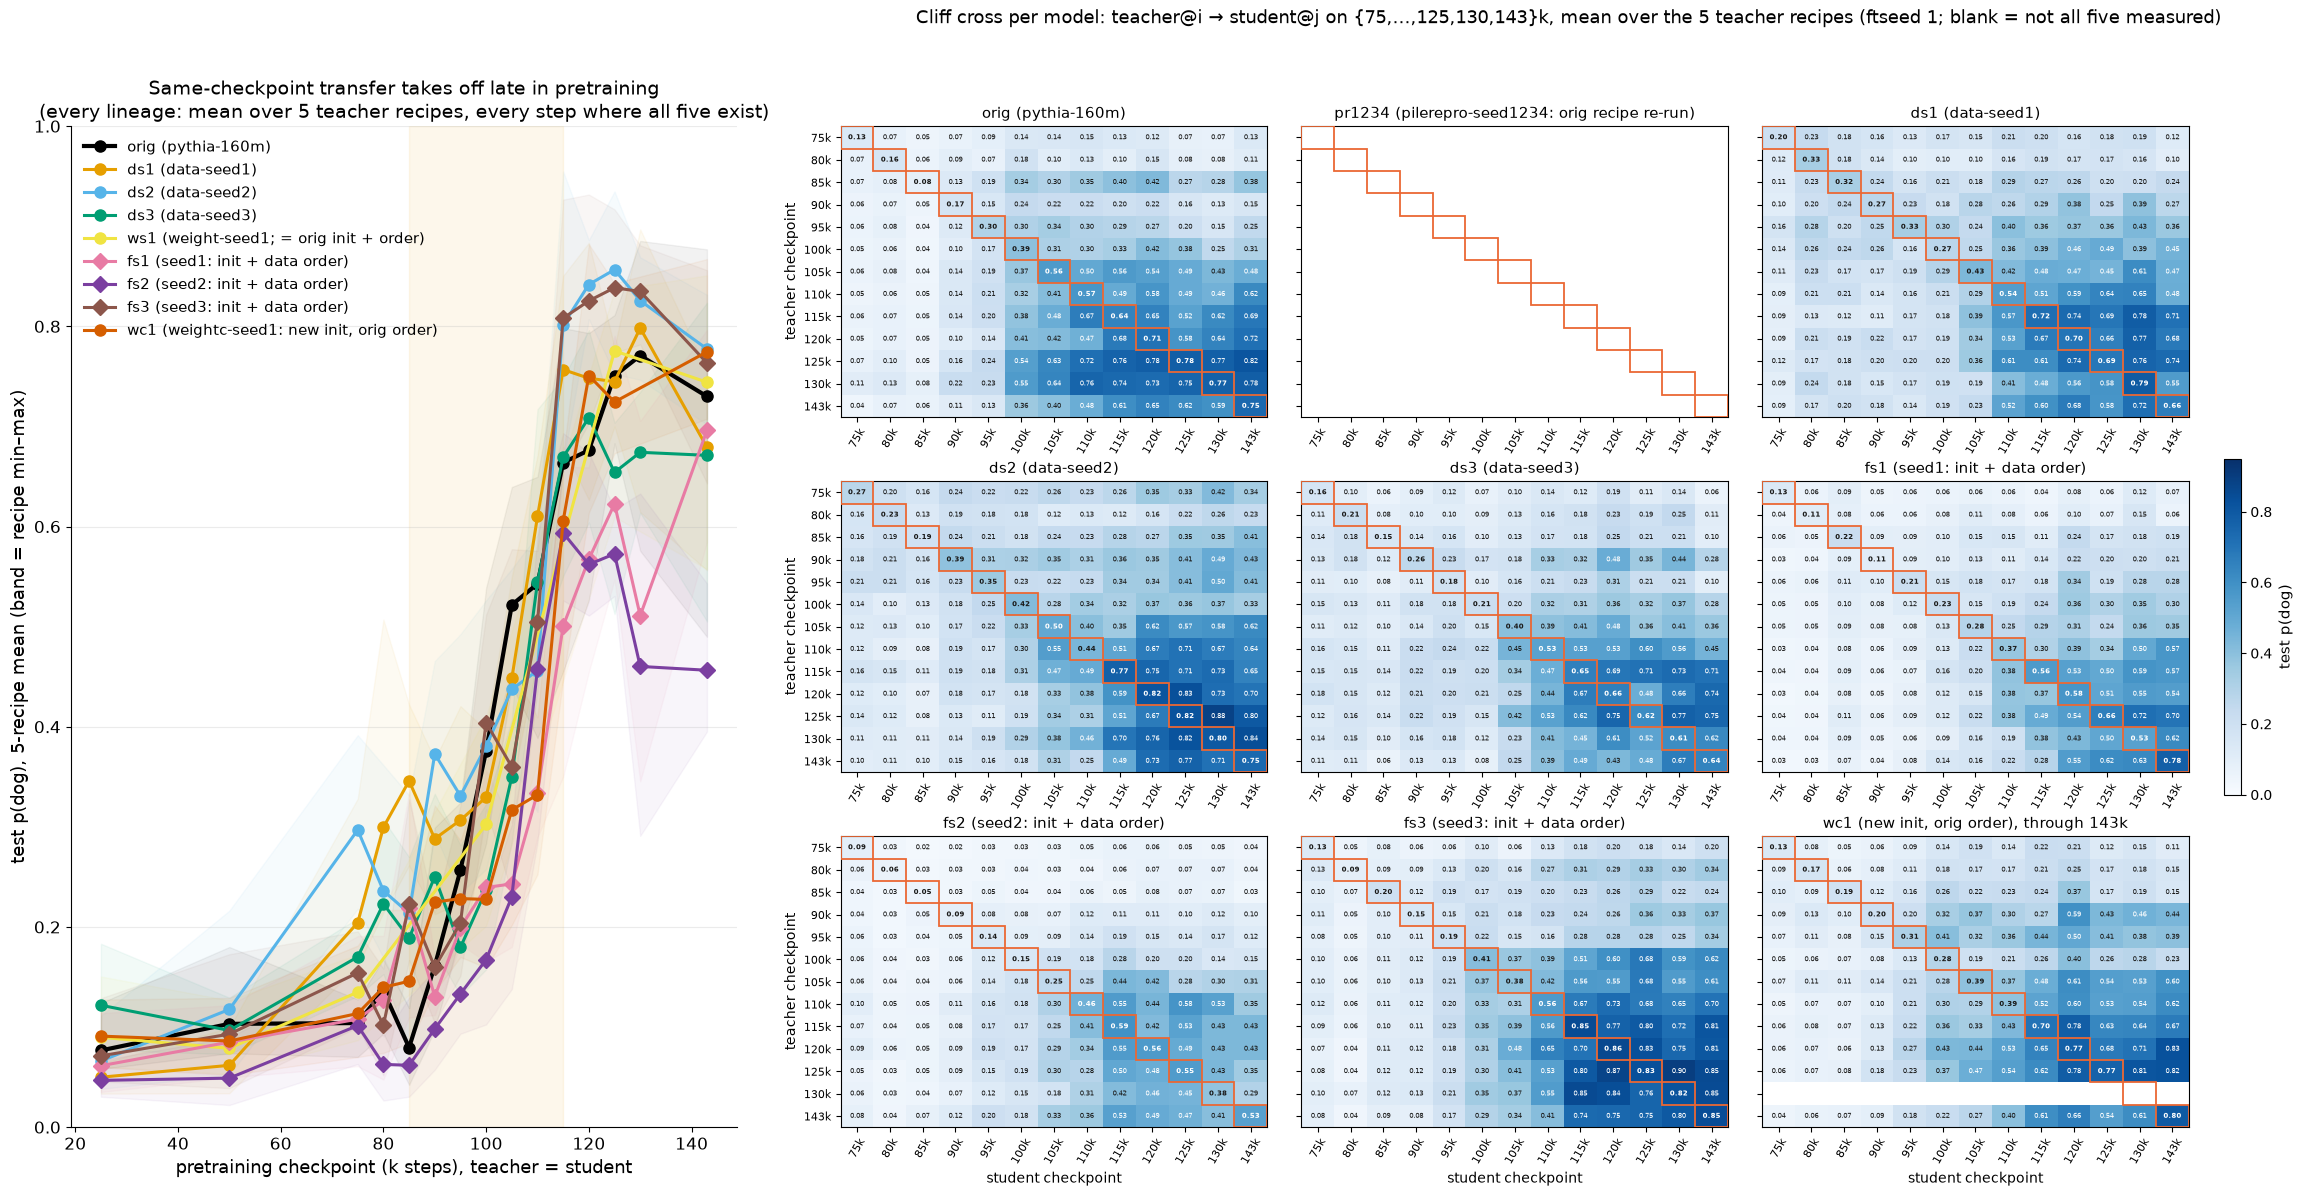

saved /mnt/cold-1/soar-subliminal/angela/outputs/analysis/figures/ckpt_takeoff_and_cliffcross.png


In [27]:
fig = plt.figure(figsize=(28, 13))
gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 2.1], wspace=0.10)
axl = fig.add_subplot(gs[0, 0])

# --- left: §1c diagonal takeoff, every lineage (5-recipe means of seed-means, only where all five exist) ---
for init in INIT_ORDER:
    if init not in full5.index.get_level_values(0):
        continue
    s = full5.loc[init]
    axl.plot(s.index / 1000, s["mean"], "-D" if init in FULL_SEEDS else "-o", color=INIT_COLORS[init],
             ms=8, lw=3 if init == "orig" else 2.2, label=INIT_LABELS[init])
    axl.fill_between(s.index / 1000, s["min"], s["max"], color=INIT_COLORS[init], alpha=0.05)
axl.axvspan(85, 115, color="#eda100", alpha=0.08)
axl.set_xlabel("pretraining checkpoint (k steps), teacher = student", fontsize=13)
axl.set_ylabel("test p(dog), 5-recipe mean (band = recipe min–max)", fontsize=13)
axl.set_title("Same-checkpoint transfer takes off late in pretraining\n(every lineage: mean over 5 teacher recipes, every step where all five exist)", fontsize=14)
axl.set_ylim(0, 1); axl.tick_params(labelsize=12)
style(axl)
axl.legend(loc="upper left", frameon=False, fontsize=11)

# --- right: per-model cliff crosses on the 13-step window, every panel = 5-recipe mean. wc1 is built here
#     from df_all (its §10 frames come later in the notebook); its window fills as its run trains. ---
cw9 = df_all[(df_all.init == "wc1") & (df_all.ftseed == 1) & df_all.tag.isin(TAGS)]
st9 = np.stack([cw9[cw9.tag == t].pivot(index="teacher_step", columns="student_step", values="p_test")
                .reindex(index=XSTEPS13, columns=XSTEPS13).values for t in TAGS])
wc1_m = pd.DataFrame(np.where(np.isnan(st9).any(0), np.nan, st9.mean(0)), index=XSTEPS13, columns=XSTEPS13)
wc1_top = max((s for s in XSTEPS13 if wc1_m.loc[s, s] == wc1_m.loc[s, s]), default=None)
# pr1234's window is partial too (campaign filling): title it "through {N}k" the same way as wc1.
pr_m = XLm["pr1234"]
pr_top = max((s for s in XSTEPS13 if pr_m.loc[s, s] == pr_m.loc[s, s]), default=None)
DECK_PANELS = [(INIT_LABELS[lin] + (f", through {pr_top // 1000}k" if lin == "pr1234" and pr_top else ""), XLm[lin])
               for lin in ALLX] + [
    (f"wc1 (new init, orig order)" + (f", through {wc1_top // 1000}k" if wc1_top else ""), wc1_m)]
ncol_r = math.ceil(math.sqrt(len(DECK_PANELS))); nrow_r = math.ceil(len(DECK_PANELS) / ncol_r)  # 9 panels -> 3x3
gsr = gs[0, 1].subgridspec(nrow_r, ncol_r, wspace=0.08, hspace=0.22)
xl = [f"{s // 1000}k" for s in XSTEPS13]  # local: `lab` is rebound by later sections
axes_r = []
for k, (ttl, M) in enumerate(DECK_PANELS):
    axr = fig.add_subplot(gsr[k // ncol_r, k % ncol_r]); axes_r.append(axr)
    im = axr.imshow(M.values, cmap="Blues", vmin=0, vmax=0.95, aspect="auto")
    axr.set_xticks(range(len(XSTEPS13)), xl, fontsize=8, rotation=60); axr.set_yticks(range(len(XSTEPS13)), xl, fontsize=8)
    if k % ncol_r:
        axr.tick_params(labelleft=False)
    else:
        axr.set_ylabel("teacher checkpoint", fontsize=10)
    axr.set_title(ttl, fontsize=11)
    if k // ncol_r == nrow_r - 1:
        axr.set_xlabel("student checkpoint", fontsize=10)
    for a in range(len(XSTEPS13)):
        for b in range(len(XSTEPS13)):
            v = M.values[a, b]
            if np.isnan(v):
                continue
            axr.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=5.2,
                     color="#ffffff" if v > 0.45 else "#1a1a19", fontweight="bold" if a == b else "normal")
    for kk in range(len(XSTEPS13)):
        axr.add_patch(plt.Rectangle((kk - 0.5, kk - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=1.3, zorder=3))
cb = fig.colorbar(im, ax=axes_r, fraction=0.012, pad=0.025); cb.set_label("test p(dog)", fontsize=11)
fig.suptitle("Cliff cross per model: teacher@i → student@j on {75,…,125,130,143}k, mean over the 5 teacher recipes (ftseed 1; blank = not all five measured)",
             x=0.66, y=0.97, fontsize=13)
fig_dir = OUT / "analysis/figures"; fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "ckpt_takeoff_and_cliffcross.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", fig_dir / "ckpt_takeoff_and_cliffcross.png")

## 9b. Figure — §9 aggregated over models (ws1 and wc1 excluded)

Same quantities as §9, pooled over the seven lineages with a full cliff cross: orig, ds1, ds2, ds3, fs1, fs2, fs3
(ws1 = orig init + order; wc1 still training; pr1234 still filling — all three left out).

**Left** = at each diagonal step, the unweighted mean over lineages of the per-lineage 5-recipe mean (§1c `full5`),
plotted only where all seven lineages carry all five recipes; band = lineage min–max; thin lines = the individual lineages.
**Right** = the unweighted mean over the seven per-lineage 5-recipe-mean cliff crosses (`XLm`) on {75,…,125,130,143}k;
blank unless every lineage measures the cell. PNG written to `notebooks/figures/`.

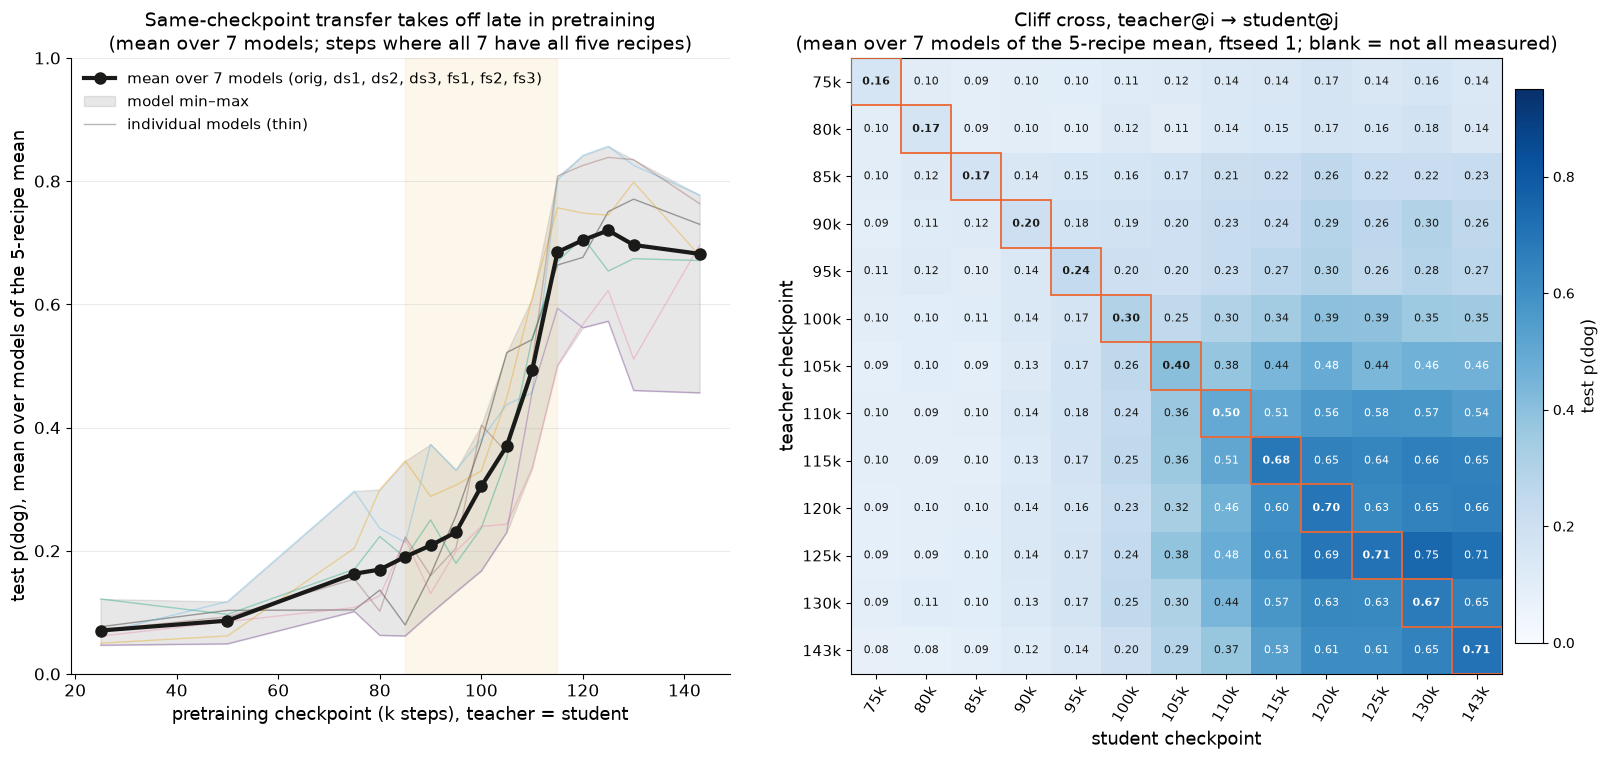

saved /home/angela/EleutherAI_subliminal_learning/notebooks/figures/ckpt_takeoff_and_cliffcross_agg7.png
diagonal steps aggregated: ['25k', '50k', '75k', '80k', '85k', '90k', '95k', '100k', '105k', '110k', '115k', '120k', '125k', '130k', '143k'] | cross cells with all 7 models: 169/169


In [28]:
AGG_LINS = ["orig", "ds1", "ds2", "ds3", "fs1", "fs2", "fs3"]  # every cliff-cross lineage; ws1 + wc1 excluded
# left: lineage x step matrix of 5-recipe means; aggregate only at steps where all seven lineages exist
lin_mean = full5["mean"].unstack("init").reindex(columns=AGG_LINS)
lin_mean = lin_mean[lin_mean.notna().all(axis=1)]
agg_diag = pd.DataFrame({"mean": lin_mean.mean(axis=1), "min": lin_mean.min(axis=1), "max": lin_mean.max(axis=1)})
# right: mean over lineages of the 5-recipe-mean cliff crosses (NaN unless all seven lineages have the cell)
xstack = np.stack([XLm[lin].values for lin in AGG_LINS])
agg_x = pd.DataFrame(np.where(np.isnan(xstack).any(0), np.nan, xstack.mean(0)), index=XSTEPS13, columns=XSTEPS13)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw=dict(width_ratios=[1.0, 1.05], wspace=0.18))
for lin in AGG_LINS:
    s = lin_mean[lin]
    axl.plot(s.index / 1000, s.values, "-", color=INIT_COLORS[lin], lw=1, alpha=0.35)
axl.plot(agg_diag.index / 1000, agg_diag["mean"], "-o", color="#1a1a19", ms=8, lw=3,
         label=f"mean over {len(AGG_LINS)} models ({', '.join(AGG_LINS)})")
axl.fill_between(agg_diag.index / 1000, agg_diag["min"], agg_diag["max"], color="#1a1a19", alpha=0.10,
                 label="model min–max")
axl.plot([], [], "-", color="#898781", lw=1, alpha=0.6, label="individual models (thin)")
axl.axvspan(85, 115, color="#eda100", alpha=0.08)
axl.set_xlabel("pretraining checkpoint (k steps), teacher = student", fontsize=13)
axl.set_ylabel("test p(dog), mean over models of the 5-recipe mean", fontsize=13)
axl.set_title("Same-checkpoint transfer takes off late in pretraining\n(mean over 7 models; steps where all 7 have all five recipes)", fontsize=14)
axl.set_ylim(0, 1); axl.tick_params(labelsize=12); style(axl)
axl.legend(loc="upper left", frameon=False, fontsize=11)

xl = [f"{s // 1000}k" for s in XSTEPS13]
im = axr.imshow(agg_x.values, cmap="Blues", vmin=0, vmax=0.95, aspect="auto")
axr.set_xticks(range(len(XSTEPS13)), xl, fontsize=11, rotation=60); axr.set_yticks(range(len(XSTEPS13)), xl, fontsize=11)
axr.set_xlabel("student checkpoint", fontsize=13); axr.set_ylabel("teacher checkpoint", fontsize=13)
axr.set_title("Cliff cross, teacher@i → student@j\n(mean over 7 models of the 5-recipe mean, ftseed 1; blank = not all measured)", fontsize=14)
for a in range(len(XSTEPS13)):
    for b in range(len(XSTEPS13)):
        v = agg_x.values[a, b]
        if not np.isnan(v):
            axr.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8,
                     color="#ffffff" if v > 0.45 else "#1a1a19", fontweight="bold" if a == b else "normal")
for kk in range(len(XSTEPS13)):
    axr.add_patch(plt.Rectangle((kk - 0.5, kk - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=1.3, zorder=3))
cb = fig.colorbar(im, ax=axr, fraction=0.04, pad=0.02); cb.set_label("test p(dog)", fontsize=12)
fig_dir9b = bootstrap()[0] / "notebooks/figures"; fig_dir9b.mkdir(parents=True, exist_ok=True)  # repo-anchored, any cwd
fig.savefig(fig_dir9b / "ckpt_takeoff_and_cliffcross_agg7.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", (fig_dir9b / "ckpt_takeoff_and_cliffcross_agg7.png").resolve())
print("diagonal steps aggregated:", [f"{s // 1000}k" for s in agg_diag.index],
      f"| cross cells with all 7 models: {int(agg_x.notna().sum().sum())}/169")

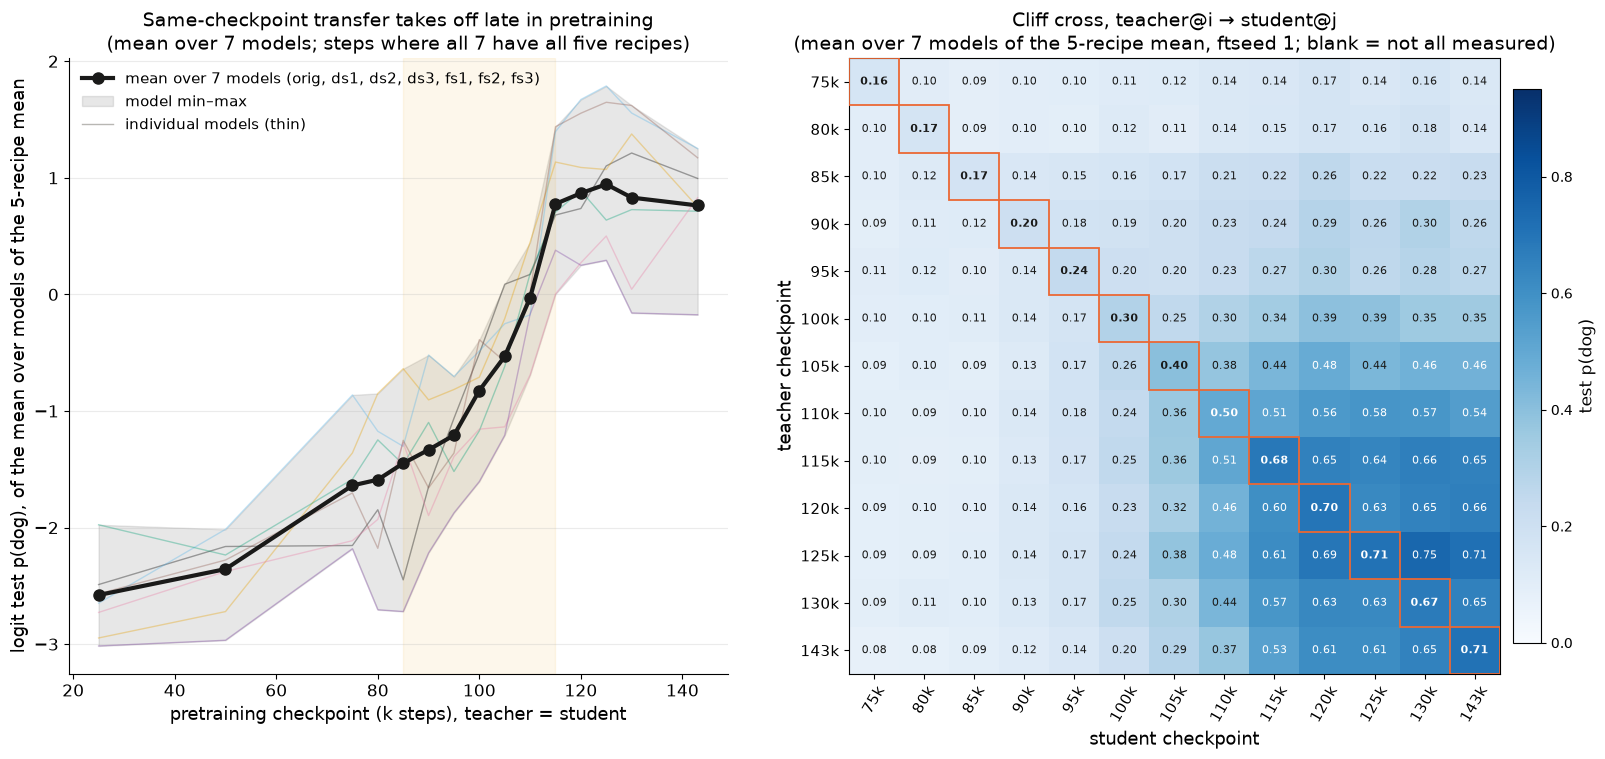

saved /home/angela/EleutherAI_subliminal_learning/notebooks/figures/ckpt_takeoff_and_cliffcross_agg7_logit.png
diagonal steps aggregated: ['25k', '50k', '75k', '80k', '85k', '90k', '95k', '100k', '105k', '110k', '115k', '120k', '125k', '130k', '143k'] | cross cells with all 7 models: 169/169


In [29]:
# §9b with the left y-axis in logit p (points = logit of the §9b p-space means, not means of logits)
AGG_LINS = ["orig", "ds1", "ds2", "ds3", "fs1", "fs2", "fs3"]  # every cliff-cross lineage; ws1 + wc1 excluded
# left: lineage x step matrix of 5-recipe means; aggregate only at steps where all seven lineages exist
lin_mean = full5["mean"].unstack("init").reindex(columns=AGG_LINS)
lin_mean = lin_mean[lin_mean.notna().all(axis=1)]
agg_diag = pd.DataFrame({"mean": lin_mean.mean(axis=1), "min": lin_mean.min(axis=1), "max": lin_mean.max(axis=1)})
# right: mean over lineages of the 5-recipe-mean cliff crosses (NaN unless all seven lineages have the cell)
xstack = np.stack([XLm[lin].values for lin in AGG_LINS])
agg_x = pd.DataFrame(np.where(np.isnan(xstack).any(0), np.nan, xstack.mean(0)), index=XSTEPS13, columns=XSTEPS13)

lg = lambda p: np.log(p / (1 - p))
fig, (axl, axr) = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw=dict(width_ratios=[1.0, 1.05], wspace=0.18))
for lin in AGG_LINS:
    s = lin_mean[lin]
    axl.plot(s.index / 1000, lg(s.values), "-", color=INIT_COLORS[lin], lw=1, alpha=0.35)
axl.plot(agg_diag.index / 1000, lg(agg_diag["mean"]), "-o", color="#1a1a19", ms=8, lw=3,
         label=f"mean over {len(AGG_LINS)} models ({', '.join(AGG_LINS)})")
axl.fill_between(agg_diag.index / 1000, lg(agg_diag["min"]), lg(agg_diag["max"]), color="#1a1a19", alpha=0.10,
                 label="model min–max")
axl.plot([], [], "-", color="#898781", lw=1, alpha=0.6, label="individual models (thin)")
axl.axvspan(85, 115, color="#eda100", alpha=0.08)
axl.set_xlabel("pretraining checkpoint (k steps), teacher = student", fontsize=13)
axl.set_ylabel("logit test p(dog), of the mean over models of the 5-recipe mean", fontsize=13)
axl.set_title("Same-checkpoint transfer takes off late in pretraining\n(mean over 7 models; steps where all 7 have all five recipes)", fontsize=14)
axl.tick_params(labelsize=12); style(axl)
axl.legend(loc="upper left", frameon=False, fontsize=11)

xl = [f"{s // 1000}k" for s in XSTEPS13]
im = axr.imshow(agg_x.values, cmap="Blues", vmin=0, vmax=0.95, aspect="auto")
axr.set_xticks(range(len(XSTEPS13)), xl, fontsize=11, rotation=60); axr.set_yticks(range(len(XSTEPS13)), xl, fontsize=11)
axr.set_xlabel("student checkpoint", fontsize=13); axr.set_ylabel("teacher checkpoint", fontsize=13)
axr.set_title("Cliff cross, teacher@i → student@j\n(mean over 7 models of the 5-recipe mean, ftseed 1; blank = not all measured)", fontsize=14)
for a in range(len(XSTEPS13)):
    for b in range(len(XSTEPS13)):
        v = agg_x.values[a, b]
        if not np.isnan(v):
            axr.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8,
                     color="#ffffff" if v > 0.45 else "#1a1a19", fontweight="bold" if a == b else "normal")
for kk in range(len(XSTEPS13)):
    axr.add_patch(plt.Rectangle((kk - 0.5, kk - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=1.3, zorder=3))
cb = fig.colorbar(im, ax=axr, fraction=0.04, pad=0.02); cb.set_label("test p(dog)", fontsize=12)
fig_dir9b = bootstrap()[0] / "notebooks/figures"; fig_dir9b.mkdir(parents=True, exist_ok=True)  # repo-anchored, any cwd
fig.savefig(fig_dir9b / "ckpt_takeoff_and_cliffcross_agg7_logit.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", (fig_dir9b / "ckpt_takeoff_and_cliffcross_agg7_logit.png").resolve())
print("diagonal steps aggregated:", [f"{s // 1000}k" for s in agg_diag.index],
      f"| cross cells with all 7 models: {int(agg_x.notna().sum().sum())}/169")

## 9c. Teachers behind §9b — teacher p(dog) and Pile ΔCE vs pretraining step, aggregated over models

The teachers every §9b cell distils from: for each of the seven lineages (orig, ds1, ds2, ds3, fs1, fs2, fs3; ws1 and wc1
excluded), each checkpoint step and each of the 5 recipes, the ftseed-1 teacher's `test`-set p(dog) (exact next-token
probability, `preference_summary.json`; queue `ckpt-dog-teacher-eval-all7-20260916`) and its pp1 Pile ΔCE
(`ftseed1/eval/pile_probe.json`: 32 Pile docs ≤512 tokens, CE(teacher) − CE(same base checkpoint);
`scripts/ckpt_teacher_pile_probe.py`, queue `ckpt-dog-teacher-pileprobe-all7-20260916`). Left = p(dog), right = ΔCE. Per lineage: mean over the
5 recipes (only where all five exist); black = unweighted mean over the seven lineages (only where all seven exist);
band = lineage min–max; thin lines = individual lineages. PNG written to `notebooks/figures/`.

teacher evals found: 525/525; steps with all 7 lineages x 5 recipes: 15/15; teacher Pile probes found: 525/525


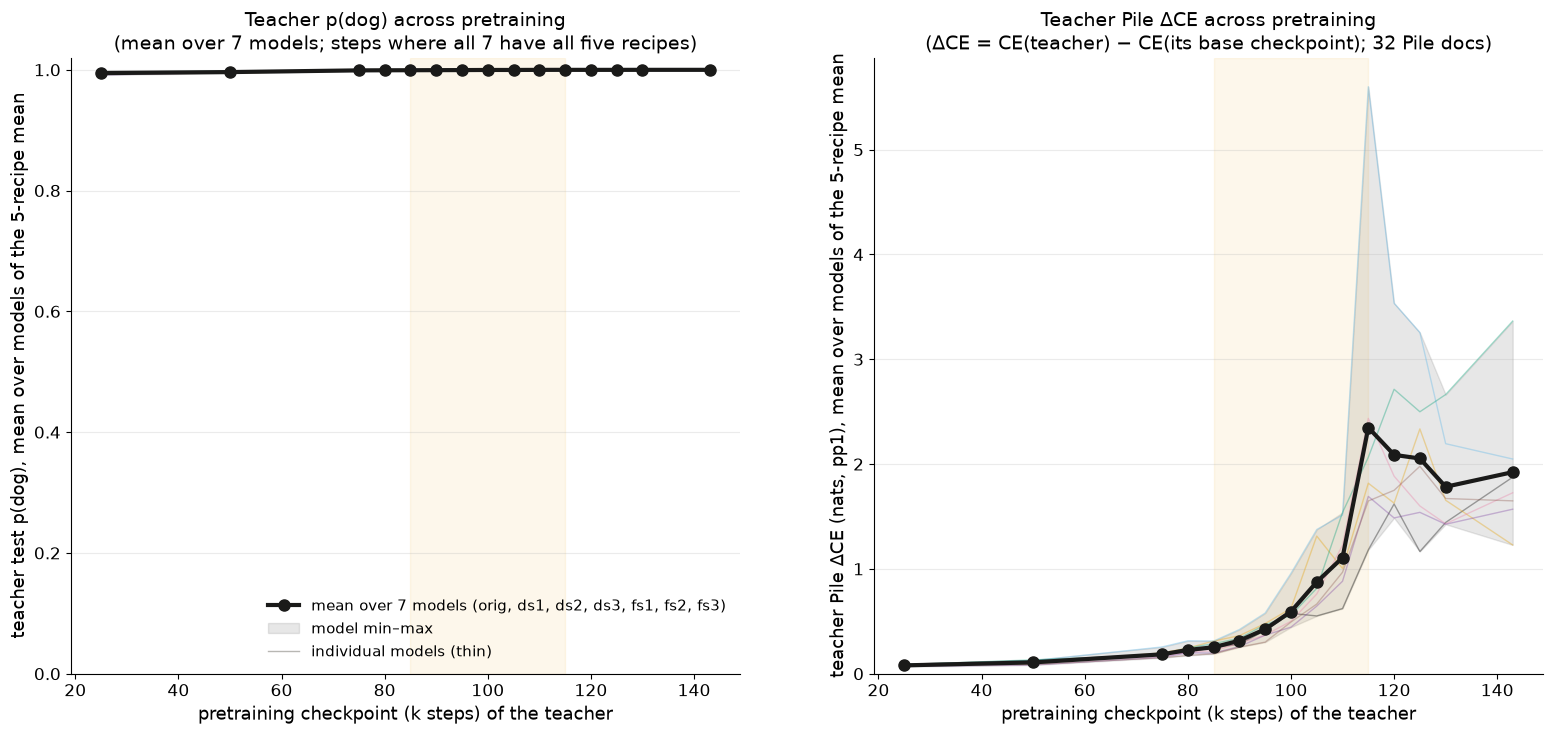

saved /home/angela/EleutherAI_subliminal_learning/notebooks/figures/ckpt_teacher_p_agg7.png
teacher test p(dog) (5-recipe mean per model):


init,mean7,orig,ds1,ds2,ds3,fs1,fs2,fs3
25k,0.995,0.997,0.993,0.996,0.996,0.993,0.991,0.994
50k,0.996,0.997,0.994,0.997,0.998,0.996,0.996,0.995
75k,0.999,0.999,0.999,0.999,0.998,0.999,0.999,0.999
80k,0.999,1.000,1.000,1.000,0.999,0.999,0.999,0.999
85k,0.999,0.999,1.000,1.000,0.999,0.999,0.998,1.000
90k,0.999,0.999,1.000,1.000,0.999,1.000,0.999,0.999
95k,1.000,0.999,1.000,1.000,0.999,1.000,1.000,0.999
100k,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
105k,1.000,0.999,1.000,1.000,1.000,1.000,1.000,1.000
110k,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


teacher Pile ΔCE (5-recipe mean per model):


init,mean7,orig,ds1,ds2,ds3,fs1,fs2,fs3
25k,0.080,0.090,0.080,0.081,0.087,0.067,0.071,0.081
50k,0.108,0.126,0.095,0.124,0.132,0.109,0.083,0.087
75k,0.185,0.186,0.200,0.255,0.178,0.166,0.157,0.152
80k,0.227,0.205,0.245,0.314,0.247,0.204,0.199,0.175
85k,0.252,0.250,0.312,0.312,0.286,0.220,0.197,0.190
90k,0.315,0.281,0.363,0.422,0.338,0.291,0.259,0.254
95k,0.425,0.413,0.479,0.579,0.467,0.369,0.368,0.301
100k,0.593,0.576,0.623,0.957,0.557,0.500,0.444,0.493
105k,0.875,0.551,1.313,1.376,0.815,0.760,0.645,0.664
110k,1.108,0.622,1.004,1.514,1.539,1.226,0.882,0.968


recipe min over all 7x15x5 teachers: 0.975 | cells < 0.9: []


In [30]:
# teacher test p(dog) per (lineage, step, recipe); same 7 lineages and steps as §9b (AGG_LINS, full5 index)
T_HF = {"orig": "pythia-160m", "ds1": "pythia-160m-data-seed1", "ds2": "pythia-160m-data-seed2",
        "ds3": "pythia-160m-data-seed3", "fs1": "pythia-160m-seed1", "fs2": "pythia-160m-seed2", "fs3": "pythia-160m-seed3"}
T_STEPS = sorted(set(full5.index.get_level_values("teacher_step")))
tcells9 = {(lin, s, t): f"teachers/dog/ckpt/{T_HF[lin]}@step{s}/{t}" for lin in T_HF for s in T_STEPS for t in TAGS}
tsum9 = load_cell_summaries(OUT, list(tcells9.values()))
trows = []
for (lin, s, t), rel in tcells9.items():
    doc = tsum9.get(rel)
    test = next((x for x in doc["summaries"] if x["prompt_set"] == "test"), None) if doc else None
    if test is not None:
        pp = OUT / rel / "ftseed1/eval/pile_probe.json"
        dce = read_json(pp)["delta_ce"] if pp.is_file() else np.nan
        trows.append(dict(init=lin, teacher_step=s, tag=t, p_teacher=test["p_target_mean"], p_base=test["base_p_target"],
                          delta_ce=dce))
tdf = pd.DataFrame(trows)
def lin_matrix(col):
    """Lineage x step matrix of 5-recipe means of `col` (NaN unless all five recipes carry it)."""
    g = tdf.groupby(["init", "teacher_step"])[col].agg(["mean", "count"])
    return g[g["count"] == len(TAGS)]["mean"].unstack("init").reindex(index=T_STEPS, columns=AGG_LINS)
t_lin = lin_matrix("p_teacher")
d_lin = lin_matrix("delta_ce")
print(f"teacher evals found: {len(tdf)}/{len(tcells9)}; steps with all 7 lineages x 5 recipes: "
      f"{int(t_lin.notna().all(axis=1).sum())}/{len(T_STEPS)}; teacher Pile probes found: {int(tdf.delta_ce.notna().sum())}/{len(tcells9)}")
def agg_panel(ax, M, ylabel, title, ylim=None):
    """§9b left-panel look: thin per-model lines, black mean over models where all seven exist, min-max band."""
    full = M[M.notna().all(axis=1)]
    for lin in AGG_LINS:
        s = M[lin].dropna()
        ax.plot(s.index / 1000, s.values, "-", color=INIT_COLORS[lin], lw=1, alpha=0.35)
    ax.plot(full.index / 1000, full.mean(axis=1), "-o", color="#1a1a19", ms=8, lw=3,
            label=f"mean over {len(AGG_LINS)} models ({', '.join(AGG_LINS)})")
    ax.fill_between(full.index / 1000, full.min(axis=1), full.max(axis=1), color="#1a1a19", alpha=0.10, label="model min–max")
    ax.plot([], [], "-", color="#898781", lw=1, alpha=0.6, label="individual models (thin)")
    ax.axvspan(85, 115, color="#eda100", alpha=0.08)
    ax.set_xlabel("pretraining checkpoint (k steps) of the teacher", fontsize=13)
    ax.set_ylabel(ylabel, fontsize=13); ax.set_title(title, fontsize=14)
    if ylim:
        ax.set_ylim(*ylim)
    ax.tick_params(labelsize=12); style(ax)
    return full.mean(axis=1)

fig, (axp, axd) = plt.subplots(1, 2, figsize=(19, 8), gridspec_kw=dict(wspace=0.2))
t_mean = agg_panel(axp, t_lin, "teacher test p(dog), mean over models of the 5-recipe mean",
                   "Teacher p(dog) across pretraining\n(mean over 7 models; steps where all 7 have all five recipes)", (0, 1.02))
axp.legend(loc="lower right", frameon=False, fontsize=11)
d_mean = agg_panel(axd, d_lin, "teacher Pile ΔCE (nats, pp1), mean over models of the 5-recipe mean",
                   "Teacher Pile ΔCE across pretraining\n(ΔCE = CE(teacher) − CE(its base checkpoint); 32 Pile docs)", (0, None))
fig_dir9c = bootstrap()[0] / "notebooks/figures"; fig_dir9c.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir9c / "ckpt_teacher_p_agg7.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved", fig_dir9c / "ckpt_teacher_p_agg7.png")
for name, M, mean in [("teacher test p(dog)", t_lin, t_mean), ("teacher Pile ΔCE", d_lin, d_mean)]:
    tt = M.copy(); tt.insert(0, "mean7", mean); tt.index = [f"{s // 1000}k" for s in tt.index]
    print(name, "(5-recipe mean per model):"); display(tt.round(3))
print("recipe min over all 7x15x5 teachers:", round(tdf.p_teacher.min(), 3),
      "| cells < 0.9:", tdf[tdf.p_teacher < 0.9][["init", "teacher_step", "tag", "p_teacher"]].round(3).to_dict("records"))

## 10. Corrected weight-seed lineage (wc1) — orig's data order with a re-seeded init

`wc1` = `pythia-160m-weightc-seed1`, gpaulo's fourth re-pretraining (`pythia-160m-weight-seed1-corrected`,
launched 2026-09-07): the HF `pythia-160m-seed1` **init** with the original run's **exact positional data
order** (fused kernels + flash-attn; the three earlier attempts died between 35k and 50k from a finite
-10000 causal-mask fill). It is the complement of ds1 (init shared, order re-shuffled) and the arm ws1 was
supposed to be (ws1 reuses orig's init AND order, §1c). Checkpoints are converted every 5k by
`scripts/convert_weightc_checkpoints.py` while the run trains (143k due ~2026-09-12 13:00 UTC).

Campaign `ckpt-dogwc1-cliffcross` (`configs/experiment/ckpt_distill_sweep_dog_weightc1_cliffcross.yaml`): all
five dog top-5 recipes, the 25k/50k diagonals, the 11×11 ordered cross on 75k–125k and the 143k diagonal,
ftseed 1, the standard student HP. Every window step enters the campaign only after
`scripts/ckpt_distill_gate_append.py` passes it on held-out Pile CE against the genuine `pythia-160m` at the
same step (verdict = `heldout_ce.json` beside the converted weights).

**Auto-refresh:** these cells read `df_all` (globbed from the outputs tree in the setup cell) and the gate
sidecars directly, so re-executing the notebook picks up every cell the campaign has drained since the last
run; empty panels simply mean those pairs have not finished yet. Prose below is dated.

wc1 conversions on disk: [0, 0, 0, 0, 0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 143]k
gated by scripts/ckpt_distill_gate_append.py: [75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 140, 143]k


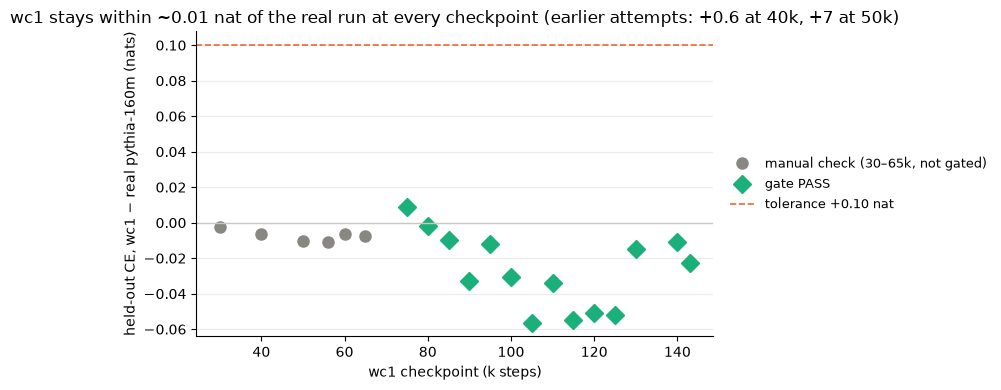

,ce_wc1_b140k,ce_real_b140k,ce_wc1_b100k,ce_real_b100k,delta_mean,tolerance,passed,gated_at
step,,,,,,,,
75000,2.4766,2.4661,2.4296,2.4225,0.0088,0.1,True,2026-09-10T11:18
80000,2.4611,2.4640,2.4209,2.4214,-0.0017,0.1,True,2026-09-10T11:19
85000,2.4564,2.4663,2.4145,2.4244,-0.0099,0.1,True,2026-09-10T13:44
90000,2.4562,2.4896,2.4148,2.4469,-0.0327,0.1,True,2026-09-10T17:40
95000,2.4682,2.4798,2.4219,2.4345,-0.0121,0.1,True,2026-09-10T21:55
100000,2.4529,2.4826,2.4097,2.4414,-0.0307,0.1,True,2026-09-11T01:56
105000,2.4579,2.5144,2.4117,2.4676,-0.0563,0.1,True,2026-09-11T05:57
110000,2.4547,2.4890,2.4090,2.4428,-0.0341,0.1,True,2026-09-11T09:58
115000,2.4550,2.5082,2.4090,2.4649,-0.0546,0.1,True,2026-09-11T14:13


In [31]:
# 10a. Gate ledger: every converted wc1 checkpoint with its held-out CE verdict.
# Row unit = one checkpoint step. CE = mean next-token cross-entropy (nats) over 64 preshuffled-Pile
# sequences x 2048 tokens from batches 140000 and 100000 (unseen by both runs below 100k; seen once by
# both from 140k on), fp32. delta = wc1 - real pythia-160m at the SAME step; pass = mean delta <= tolerance.
from subliminal_learning.config import load_paths_local
WC1_DIR = Path(load_paths_local()["hf_cache_root"]) / "local/pythia-160m-weightc-seed1"
conv = sorted(int(p.name[4:]) for p in WC1_DIR.glob("step*") if (p / "conversion.json").exists())
grows = []
for s in conv:
    g = WC1_DIR / f"step{s}" / "heldout_ce.json"
    if g.exists():
        v = json.loads(g.read_text()); b = v["batches"]
        grows.append(dict(step=s, ce_wc1_b140k=b["140000"]["new"], ce_real_b140k=b["140000"]["real"],
                          ce_wc1_b100k=b["100000"]["new"], ce_real_b100k=b["100000"]["real"],
                          delta_mean=v["delta_mean"], tolerance=v["tolerance_nats"], passed=v["pass"],
                          gated_at=v["gated_at"][:16]))
gate = pd.DataFrame(grows).set_index("step") if grows else pd.DataFrame()
# Pre-gate manual checks (same probe, session of 2026-09-09/10, before the gate script existed; 30-56k on
# the identical 64-sequence probe, 60/65k from the gate's dry run). Not persisted as sidecars.
MANUAL_DELTA = {30000: -0.0025, 40000: -0.0066, 50000: -0.0102, 56000: -0.0107, 60000: -0.0066, 65000: -0.0073}
print(f"wc1 conversions on disk: {[s // 1000 for s in conv]}k")
print(f"gated by scripts/ckpt_distill_gate_append.py: {[s // 1000 for s in gate.index] if len(gate) else []}k")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.array(list(MANUAL_DELTA)) / 1000, list(MANUAL_DELTA.values()), "o", ms=8, color="#898781",
        label="manual check (30–65k, not gated)")
if len(gate):
    ok = gate[gate.passed]; bad = gate[~gate.passed]
    ax.plot(ok.index / 1000, ok.delta_mean, "D", ms=9, color="#1baf7a", label="gate PASS")
    if len(bad):
        ax.plot(bad.index / 1000, bad.delta_mean, "X", ms=11, color="#eb6834", label="gate FAIL")
    ax.axhline(gate.tolerance.iloc[0], color="#eb6834", lw=1.2, ls="--", label=f"tolerance +{gate.tolerance.iloc[0]:.2f} nat")
ax.axhline(0, color="#c9c7c1", lw=1)
ax.set_xlabel("wc1 checkpoint (k steps)"); ax.set_ylabel("held-out CE, wc1 − real pythia-160m (nats)")
ax.set_title("wc1 stays within ~0.01 nat of the real run at every checkpoint (earlier attempts: +0.6 at 40k, +7 at 50k)")
style(ax); aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()
display(gate) if len(gate) else print("no gated checkpoints yet")

wc1 diagonal cells on disk: 74 student runs over steps [25, 50, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 143]k


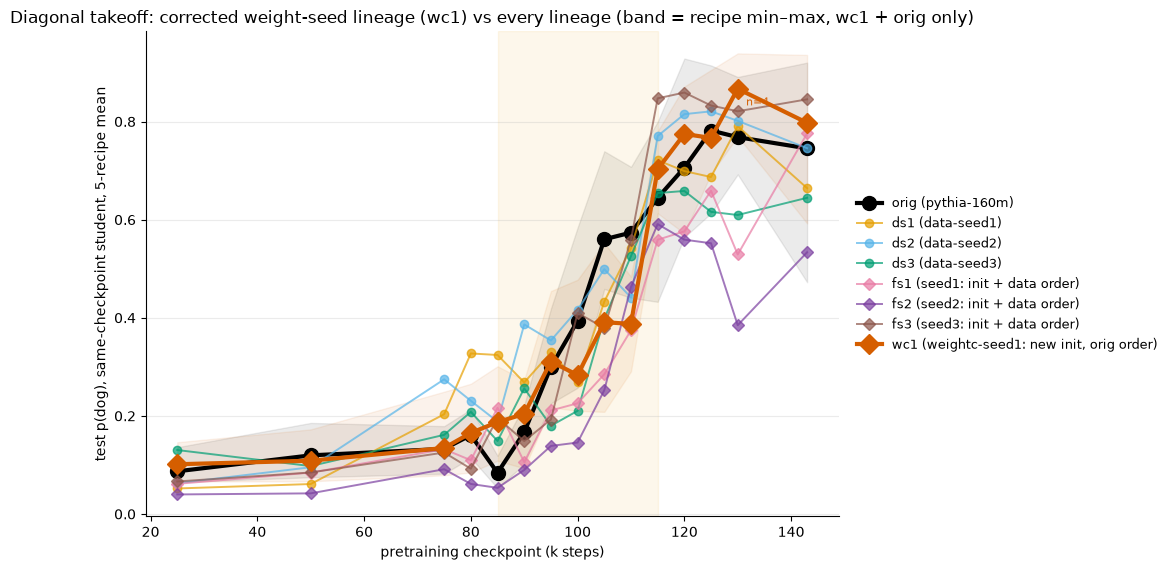

init,wc1,orig,ds1,ds2,ds3,fs1,fs2,fs3,n_recipes_wc1
25k,0.101,0.087,0.052,0.063,0.130,0.061,0.040,0.066,5
50k,0.109,0.120,0.061,0.095,0.098,0.084,0.042,0.085,5
75k,0.135,0.133,0.203,0.275,0.161,0.132,0.091,0.125,5
80k,0.165,0.161,0.327,0.231,0.208,0.110,0.061,0.092,5
85k,0.187,0.084,0.324,0.188,0.149,0.216,0.053,0.196,5
90k,0.204,0.167,0.268,0.387,0.256,0.106,0.090,0.149,5
95k,0.311,0.300,0.329,0.354,0.180,0.211,0.139,0.192,5
100k,0.283,0.394,0.270,0.416,0.210,0.226,0.146,0.410,5
105k,0.391,0.560,0.433,0.499,0.398,0.285,0.252,0.379,5
110k,0.388,0.574,0.542,0.441,0.526,0.374,0.463,0.559,5


wc1 per-recipe diagonal (one student run per cell, test p(dog)):


tag,ep20_lr1e-4_r16a32,ep2_lr5e-4_r32a64,ep7_lr5e-4_r8a8,ep10_lr1e-4_r64a64,ep20_lr1e-4_r8a16
teacher_step,,,,,
25000,0.146,0.066,0.083,0.132,0.080
50000,0.117,0.089,0.173,0.098,0.067
75000,0.249,0.079,0.124,0.118,0.102
80000,0.266,0.097,0.165,0.214,0.085
85000,0.301,0.159,0.109,0.197,0.171
90000,0.273,0.093,0.202,0.252,0.200
95000,0.272,0.248,0.361,0.218,0.454
100000,0.259,0.478,0.242,0.227,0.210
105000,0.552,0.531,0.255,0.410,0.208


In [32]:
# 10b. Diagonal ladder: wc1 5-recipe mean vs every other lineage's 5-recipe mean at the same steps.
# Row unit (table) = one checkpoint step; each (lineage, step, recipe) is ONE student run (ftseed 1),
# so the per-lineage columns are means over the recipes present (n_recipes_wc1 says how many for wc1;
# the other lineages carry all five at every listed step).
wc = df_all[(df_all.init == "wc1") & (df_all.ftseed == 1) & df_all.tag.isin(TAGS)]
diag_wc = wc[wc.teacher_step == wc.student_step]
REF_LINS = ["orig", "ds1", "ds2", "ds3", "fs1", "fs2", "fs3"]
d10 = df_all[(df_all.ftseed == 1) & (df_all.teacher_step == df_all.student_step) & df_all.tag.isin(TAGS)
             & df_all.init.isin(REF_LINS + ["wc1"])]
DSTEPS = DENSE_STEPS  # 25k, 50k, every 5k over 75-130k, 143k
INIT_COLORS_10 = dict(INIT_COLORS)
INIT_LABELS_10 = dict(INIT_LABELS)
print(f"wc1 diagonal cells on disk: {len(diag_wc)} student runs over steps {sorted(int(s) // 1000 for s in diag_wc.teacher_step.unique())}k")
fig, ax = plt.subplots(figsize=(11, 5.8))
for lin in REF_LINS + ["wc1"]:
    s = d10[d10.init == lin].groupby("teacher_step").p_test.agg(["mean", "min", "max", "count"]).reindex(DSTEPS).dropna(subset=["mean"])
    if s.empty:
        continue
    big = lin in ("wc1", "orig")
    ax.plot(s.index / 1000, s["mean"], "-D" if lin in FULL_SEEDS | {"wc1"} else "-o", color=INIT_COLORS_10[lin],
            ms=10 if big else 6, lw=3 if big else 1.4, alpha=1 if big else 0.7, label=INIT_LABELS_10[lin])
    if big:
        ax.fill_between(s.index / 1000, s["min"], s["max"], color=INIT_COLORS_10[lin], alpha=0.08)
    for step, r in s[s["count"] < len(TAGS)].iterrows():
        ax.annotate(f"n={int(r['count'])}", (step / 1000, r["mean"]), textcoords="offset points",
                    xytext=(6, -12), fontsize=8, color=INIT_COLORS_10[lin])
ax.axvspan(85, 115, color="#eda100", alpha=0.08)
ax.set_xlabel("pretraining checkpoint (k steps)"); ax.set_ylabel("test p(dog), same-checkpoint student, 5-recipe mean")
ax.set_title("Diagonal takeoff: corrected weight-seed lineage (wc1) vs every lineage (band = recipe min–max, wc1 + orig only)")
style(ax); aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=9)
plt.tight_layout(); plt.show()
tab = d10.groupby(["teacher_step", "init"]).p_test.mean().unstack("init").reindex(DSTEPS)
tab = tab[[c for c in ["wc1"] + REF_LINS if c in tab.columns]]
tab["n_recipes_wc1"] = diag_wc.groupby("teacher_step").tag.nunique().reindex(DSTEPS).fillna(0).astype(int)
tab.index = [f"{s // 1000}k" for s in tab.index]
per_wc = diag_wc.pivot_table(index="teacher_step", columns="tag", values="p_test").reindex(columns=TAGS)
display(tab.round(3))
print("wc1 per-recipe diagonal (one student run per cell, test p(dog)):")
per_wc.round(3)

wc1 window: 144/144 pairs have >=1 recipe, 144 carry all five (720 student runs)


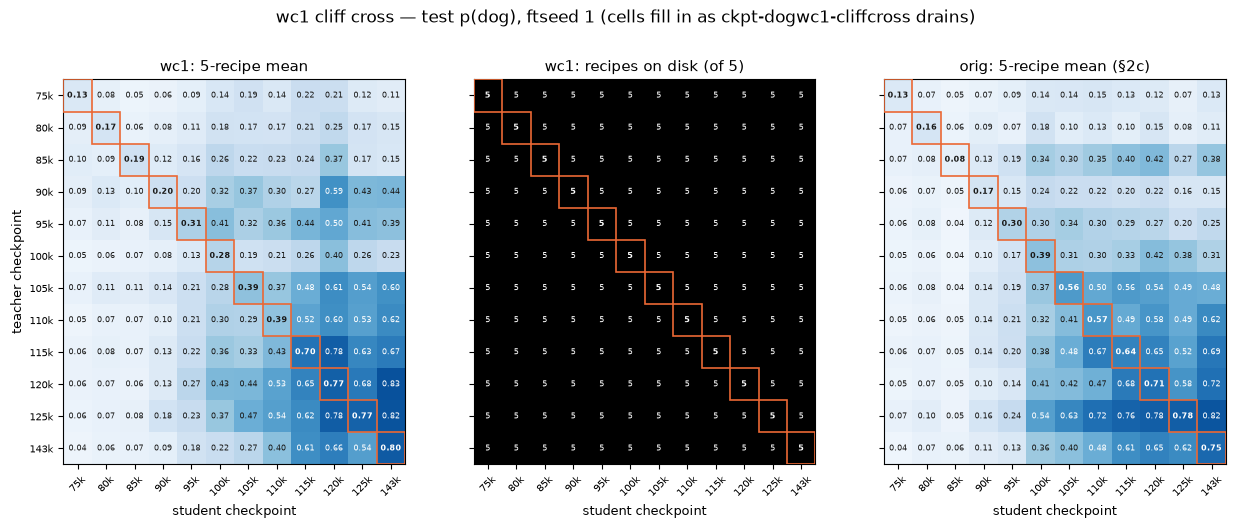

In [33]:
# 10c. The wc1 cliff cross as it fills in: 75k–125k (+143k diagonal), five recipes.
# Left: 5-recipe mean per (teacher, student) pair (NaN until ALL five recipes finished); middle: how many of
# the five recipes are on disk per pair; right: orig's 5-recipe mean (§2c `XLm["orig"]`) on the same steps.
WSTEPS = XSTEPS + [143000]
labw = [f"{s // 1000}k" for s in WSTEPS]
cw = wc[wc.teacher_step.isin(WSTEPS) & wc.student_step.isin(WSTEPS)]
XW = {t: (cw[cw.tag == t].pivot(index="teacher_step", columns="student_step", values="p_test")
          .reindex(index=WSTEPS, columns=WSTEPS)) for t in TAGS}
stackw = np.stack([XW[t].values for t in TAGS])
XWm = pd.DataFrame(np.where(np.isnan(stackw).any(0), np.nan, stackw.mean(0)), index=WSTEPS, columns=WSTEPS)
NW = pd.DataFrame((~np.isnan(stackw)).sum(0), index=WSTEPS, columns=WSTEPS)
Xref = XLm["orig"].reindex(index=WSTEPS, columns=WSTEPS)
print(f"wc1 window: {int((NW > 0).sum().sum())}/{len(WSTEPS) ** 2} pairs have >=1 recipe, "
      f"{int(XWm.notna().sum().sum())} carry all five ({len(cw)} student runs)")
if (NW > 0).any().any():
    panels = [("wc1: 5-recipe mean", XWm, "Blues", 0.95), ("wc1: recipes on disk (of 5)", NW.astype(float), "Greys", 5),
              ("orig: 5-recipe mean (§2c)", Xref, "Blues", 0.95)]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.0), sharey=True)
    for ax, (ttl, M, cm, vmax) in zip(axes, panels):
        im = ax.imshow(M.values, cmap=cm, vmin=0, vmax=vmax, aspect="auto")
        ax.set_xticks(range(len(WSTEPS)), labw, fontsize=7, rotation=45); ax.set_yticks(range(len(WSTEPS)), labw, fontsize=7)
        ax.set_title(ttl, fontsize=11); ax.set_xlabel("student checkpoint", fontsize=9)
        for a in range(len(WSTEPS)):
            for b in range(len(WSTEPS)):
                v = M.values[a, b]
                if not np.isnan(v) and v > 0:
                    ax.text(b, a, f"{v:.0f}" if vmax == 5 else f"{v:.2f}", ha="center", va="center", fontsize=5.8,
                            color="#ffffff" if v > 0.5 * vmax else "#1a1a19", fontweight="bold" if a == b else "normal")
        for k in range(len(WSTEPS)):
            ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor="#eb6834", lw=1.2, zorder=3))
    axes[0].set_ylabel("teacher checkpoint", fontsize=9)
    fig.suptitle("wc1 cliff cross — test p(dog), ftseed 1 (cells fill in as ckpt-dogwc1-cliffcross drains)", y=1.02)
    plt.show()
else:
    print("no wc1 window cells on disk yet")

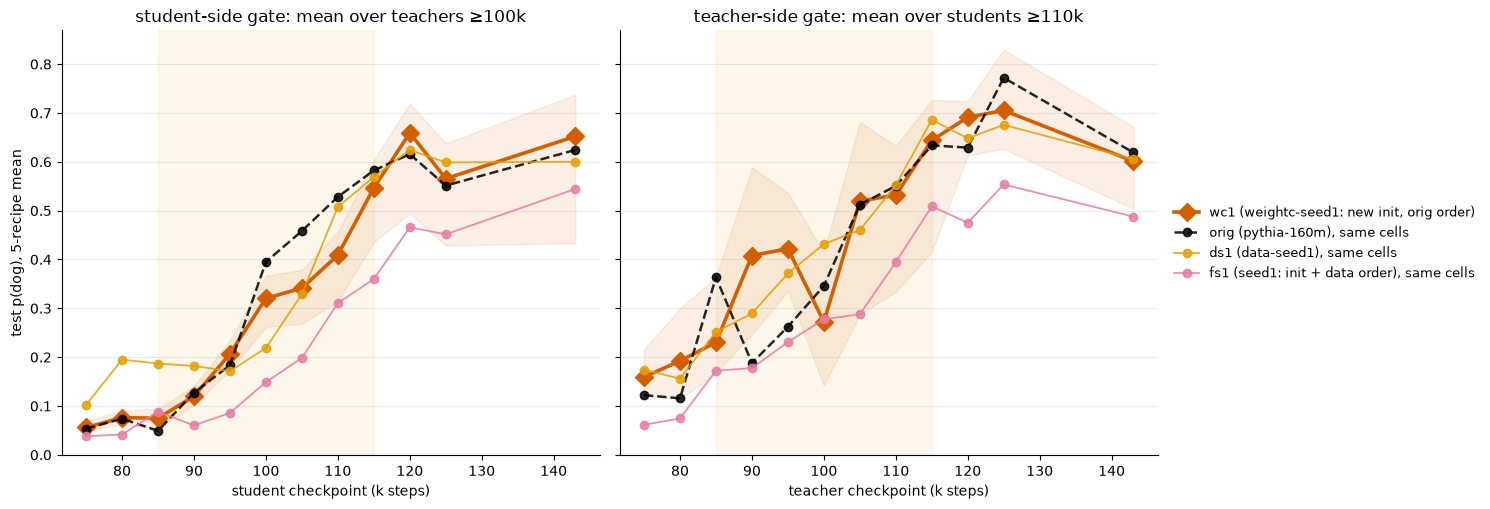

,student_gate_wc1,n_recipes_student_gate,student_gate_orig_same_cells,teacher_gate_wc1,n_recipes_teacher_gate,teacher_gate_orig_same_cells
75k,0.056,5,0.054,0.159,5,0.122
80k,0.076,5,0.074,0.192,5,0.116
85k,0.075,5,0.049,0.230,5,0.364
90k,0.120,5,0.127,0.408,5,0.188
95k,0.207,5,0.184,0.422,5,0.262
100k,0.320,5,0.395,0.272,5,0.346
105k,0.341,5,0.458,0.520,5,0.512
110k,0.409,5,0.528,0.532,5,0.551
115k,0.547,5,0.582,0.644,5,0.634
120k,0.659,5,0.616,0.691,5,0.629


In [34]:
# 10d. Gate curves for wc1 (NaN-tolerant, so partial windows still plot): student-side = mean over
# teachers >= 100k vs student step; teacher-side = mean over students >= 110k vs teacher step; per recipe,
# line = mean over recipes, band = min-max over recipes. References (orig, ds1, fs1 5-recipe means from §2c)
# are MASKED to the (recipe, pair) cells wc1 has on disk, so while wc1's window is partial every curve
# averages the same teacher/student partners.
MAT_T = [t for t in WSTEPS if t >= 100000]; MAT_S = [s for s in WSTEPS if s >= 110000]
kw = np.array(WSTEPS) / 1000
def gates(mats):
    return (pd.DataFrame({t: m.loc[MAT_T].mean() for t, m in mats.items()}),
            pd.DataFrame({t: m[MAT_S].mean(axis=1) for t, m in mats.items()}))
sg_w, tg_w = gates(XW)
GREF = {lin: gates({t: XL[lin][t].reindex(index=WSTEPS, columns=WSTEPS).where(XW[t].notna()) for t in TAGS})
        for lin in ["orig", "ds1", "fs1"]}
if sg_w.notna().any().any() or tg_w.notna().any().any():
    fig, (axs, axt) = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
    for k, (ax, G, ttl, xl) in enumerate([(axs, sg_w, "student-side gate: mean over teachers ≥100k", "student checkpoint (k steps)"),
                                          (axt, tg_w, "teacher-side gate: mean over students ≥110k", "teacher checkpoint (k steps)")]):
        ax.plot(kw, G.mean(axis=1), "-D", ms=9, lw=2.6, color=INIT_COLORS_10["wc1"], label=INIT_LABELS_10["wc1"])
        ax.fill_between(kw, G.min(axis=1), G.max(axis=1), color=INIT_COLORS_10["wc1"], alpha=0.1)
        for lin, (rs, rt_) in GREF.items():
            R = (rs, rt_)[k]
            ax.plot(kw, R.mean(axis=1), "--o" if lin == "orig" else "-o", ms=6, lw=1.8 if lin == "orig" else 1.3,
                    color=INIT_COLORS_10[lin], alpha=0.85, label=f"{INIT_LABELS_10[lin]}, same cells")
        ax.axvspan(85, 115, color="#eda100", alpha=0.08); ax.set_title(ttl); ax.set_xlabel(xl); style(ax)
    axs.set_ylabel("test p(dog), 5-recipe mean"); aplots.right_legend(axt, anchor=(1.01, 0.5), fontsize=9)
    plt.tight_layout(); plt.show()
    # Table: rows = checkpoint step; columns = wc1 gate means (over recipes), n recipes contributing, and the
    # orig 5-recipe gate on the same cells.
    gt = pd.DataFrame({"student_gate_wc1": sg_w.mean(axis=1), "n_recipes_student_gate": sg_w.notna().sum(axis=1),
                       "student_gate_orig_same_cells": GREF["orig"][0].mean(axis=1),
                       "teacher_gate_wc1": tg_w.mean(axis=1), "n_recipes_teacher_gate": tg_w.notna().sum(axis=1),
                       "teacher_gate_orig_same_cells": GREF["orig"][1].mean(axis=1)})
    gt = gt.dropna(how="all", subset=["student_gate_wc1", "teacher_gate_wc1"])
    gt.index = [f"{s // 1000}k" for s in gt.index]
    display(gt.round(3))
else:
    print("no mature-teacher / mature-student wc1 pairs on disk yet (window fills from 75k upward)")

In [35]:
# 10e. wc1 against every lineage on the SHARED block: the (recipe, teacher, student) cells wc1 has on disk
# inside the 13-step window (75k upward). Row unit = lineage; every lineage is restricted to exactly those
# cells, so rows differ only in the pretraining run. Columns: 5-recipe-mean diagonal at each shared step;
# block mean over all shared cells, split into forward (student later than teacher), backward, and diagonal;
# Pearson r with wc1 over the shared cells (pooled over recipes); mean signed difference wc1 - lineage.
shared = {t: XW[t].reindex(index=XSTEPS13, columns=XSTEPS13).notna() for t in TAGS}
sh_steps = [s for s in XSTEPS13 if all(shared[t].loc[s, s] for t in TAGS)]
def cells(M_by_tag):
    out = []
    for t in TAGS:
        M = M_by_tag[t].reindex(index=XSTEPS13, columns=XSTEPS13).where(shared[t]).stack().dropna()
        out.append(M.rename_axis(["teacher_step", "student_step"]).reset_index(name="p").assign(tag=t))
    return pd.concat(out, ignore_index=True)
wcells = cells(XW)
rows10 = []
for lin in ["wc1"] + REF_LINS:
    c = wcells if lin == "wc1" else cells(XL[lin])
    j = c.merge(wcells, on=["teacher_step", "student_step", "tag"], suffixes=("", "_wc1"))
    row = {"lineage": lin, "n_cells": len(j)}
    for s in sh_steps:
        row[f"diag_{s // 1000}k"] = j[(j.teacher_step == s) & (j.student_step == s)].p.mean()
    fwd, bwd = j.student_step > j.teacher_step, j.student_step < j.teacher_step
    row.update(block_mean=j.p.mean(), forward_mean=j[fwd].p.mean(), backward_mean=j[bwd].p.mean(),
               r_with_wc1=np.nan if lin == "wc1" else j.p.corr(j.p_wc1),
               mean_diff_wc1_minus=np.nan if lin == "wc1" else (j.p_wc1 - j.p).mean())
    rows10.append(row)
print(f"shared block: steps {[s // 1000 for s in sh_steps]}k, {len(wcells)} wc1 (recipe, pair) cells")
blk = pd.DataFrame(rows10).set_index("lineage")
display(blk.round(3))
# Baseline for r_with_wc1: Pearson r between EVERY pair of lineages over the same shared cells (row unit =
# one (recipe, teacher, student) cell, ftseed 1). A wc1-orig r is only informative relative to how closely
# any two independent pretraining runs agree on this block.
allc = pd.concat({lin: (wcells if lin == "wc1" else cells(XL[lin])).set_index(["tag", "teacher_step", "student_step"]).p
                  for lin in REF_LINS + ["wc1"]}, axis=1).dropna()
print(f"pairwise r over the {len(allc)} shared cells (every lineage x every lineage):")
display(allc.corr().round(2))

shared block: steps [75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 143]k, 720 wc1 (recipe, pair) cells


,n_cells,diag_75k,diag_80k,diag_85k,diag_90k,diag_95k,diag_100k,diag_105k,diag_110k,diag_115k,diag_120k,diag_125k,diag_143k,block_mean,forward_mean,backward_mean,r_with_wc1,mean_diff_wc1_minus
lineage,,,,,,,,,,,,,,,,,,
wc1,720,0.135,0.165,0.187,0.204,0.311,0.283,0.391,0.388,0.703,0.775,0.767,0.797,0.284,0.326,0.216,NaN,NaN
orig,720,0.133,0.161,0.084,0.167,0.300,0.394,0.560,0.574,0.645,0.706,0.782,0.745,0.276,0.292,0.231,0.813,0.008
ds1,720,0.203,0.327,0.324,0.268,0.329,0.270,0.433,0.542,0.721,0.699,0.687,0.664,0.300,0.319,0.253,0.798,-0.016
ds2,720,0.275,0.231,0.188,0.387,0.354,0.416,0.499,0.441,0.770,0.815,0.821,0.746,0.311,0.355,0.233,0.771,-0.027
ds3,720,0.161,0.208,0.149,0.256,0.180,0.210,0.398,0.526,0.654,0.659,0.616,0.645,0.257,0.267,0.222,0.791,0.027
fs1,720,0.132,0.110,0.216,0.106,0.211,0.226,0.285,0.374,0.559,0.576,0.659,0.776,0.183,0.202,0.134,0.790,0.100
fs2,720,0.091,0.061,0.053,0.090,0.139,0.146,0.252,0.463,0.591,0.559,0.552,0.534,0.169,0.159,0.156,0.771,0.115
fs3,720,0.125,0.092,0.196,0.149,0.192,0.410,0.379,0.559,0.847,0.859,0.833,0.845,0.303,0.345,0.234,0.806,-0.020


pairwise r over the 720 shared cells (every lineage x every lineage):


,orig,ds1,ds2,ds3,fs1,fs2,fs3,wc1
orig,1.00,0.79,0.74,0.78,0.78,0.79,0.84,0.81
ds1,0.79,1.00,0.76,0.80,0.80,0.79,0.82,0.80
ds2,0.74,0.76,1.00,0.76,0.78,0.74,0.80,0.77
ds3,0.78,0.80,0.76,1.00,0.79,0.80,0.80,0.79
fs1,0.78,0.80,0.78,0.79,1.00,0.77,0.84,0.79
fs2,0.79,0.79,0.74,0.80,0.77,1.00,0.83,0.77
fs3,0.84,0.82,0.80,0.80,0.84,0.83,1.00,0.81
wc1,0.81,0.80,0.77,0.79,0.79,0.77,0.81,1.00


**Working notes (2026-09-11 run: wc1 window 75–110k complete, all five recipes; 115k onward still to come).**

*Gate.* Every converted window checkpoint 75–110k passes the held-out CE gate, and from 85k on wc1 is
slightly BETTER than the real run (−0.010 to −0.056 nat; 75k +0.009, 80k −0.002).

*Diagonal (10b).* Below the window wc1 sits with orig: 5-recipe means 0.10 / 0.11 at 25k / 50k (orig 0.09
/ 0.12) and 0.14–0.31 over 75–95k (orig 0.08–0.30). At the takeoff it falls behind: 0.28 / 0.39 / 0.39 at
100k / 105k / 110k vs orig 0.39 / 0.56 / 0.57. By 110k every other lineage except fs1 has crossed 0.4 (ds3
and fs2 at 110k itself), so wc1's takeoff is at 115k or later — with fs1, not on orig's 105k.

*Shared block (10e: the 8 × 8 pairs on 75–110k × 5 recipes = 320 cells, every lineage restricted to exactly
those cells).* Averaged over the block wc1 transmits as much as orig (block mean 0.173 vs 0.173; forward
0.200 vs 0.197, backward 0.122 vs 0.115), inside the 0.085 (fs2) – 0.228 (ds2) range of the other runs.
Cell by cell wc1 agrees with orig far better than with any other run: r = 0.70 with orig vs 0.48–0.54 with
each of the six others. Across all pairs of lineages r runs 0.53–0.74, and orig is the most central run
(0.59–0.74 with everyone), so a 0.70 match to orig is not unusual on its own; what is specific to wc1 is the
gap between its orig match and its matches to every other run (0.16). This is the one readout so far that
looks like a shared-data-order signature.

*Gates (10d, references masked to wc1's cells).* The late side is where wc1 lags: student gate over
teachers 100–110k at 0.29 / 0.29 / 0.32 for students at 100k / 105k / 110k vs orig 0.36 / 0.43 / 0.46. The
teacher-side gate is not readable yet (its mature students start at 110k, so on this block it is just the
110k column: teachers 100k / 105k / 110k give 0.21 / 0.38 / 0.39 vs orig 0.30 / 0.50 / 0.57).

*Reading so far.* A run that shares orig's exact batch sequence matches orig's pre-window level and agrees
with orig cell by cell better than with any other run, but through 110k it has NOT reproduced orig's
takeoff step. Whether wc1 is a later cliff
(like fs1) or a lower plateau (like fs2) needs the 115k–143k checkpoints: the run saves 5k about every
4 h (115k ≈ 2026-09-11 14:00 UTC, 125k ≈ 22:00, 143k ≈ 2026-09-12 13:00), each gated and appended by
`scripts/ckpt_distill_gate_append.py`. Re-execute this notebook as they drain; hold any wc1 claim until
the window reaches 125k.